# Binance trade price to Polymarket: does it predict BTC's next move, and does trading that signal pay on 15-minute Up/Down?

## S0 · Summary

In [1]:
from IPython.display import Markdown, display
ANS0 = display(Markdown("_The answer is written here when the run finishes._"), display_id=True)

**No: NO SIZE, class B.** The Binance trade price is predictive on BTC's next move, but the chosen Polymarket configuration earns +0.91 USD an entry on 88 test entries (10-05 to 10-06 · 48h · BTC 15m · test days), 95% by window -2.24 to +4.05, and fails Net per entry above 0.

**Research question.** Part A: does the Binance BTCUSDT trade price alone, using nothing but trades up to the instant, predict what BTC does over the next fractions of a second to minutes, and does that survive the 150 ms delay a taker pays on Polymarket's crypto markets? Part B: if it does, does the signal chosen on the validation days earn a positive net PnL per entry on Polymarket's 15-minute BTC Up/Down books, after the taker fee, the spread, the exact fill and the delay?

This is one question, so it is one notebook. The study is a strategy (it ends in a position and a sizing decision); Part A is the thesis it must pass first and keeps its own market-study gates, Part B is the unlevered base and carries the decision. In every section Part A comes first, then Part B.

| Part A: does Binance predict the next move | |
|---|---|
| Instrument and tape | Binance spot BTCUSDT aggregate trades, one decision instant per trade millisecond, seven whole UTC days (2026-09-30 to 2026-10-06). The files carry the trade time and the aggressor side but no receive time |
| Primary experiment | Price only. Trade size and aggressor side are separate, labelled feature groups and never part of the price-only answer |
| Targets | Forward log return in basis points, signed, from the instant plus a delay, held 0.25 s to 300 s |
| Validation | Three fit days, two validation days, two test days, in date order. The protocol (six hypotheses, the bar, the gates) is committed before the test days are read |
| Weighting | Every trade millisecond is a row. Results are given per second of time beside per trade, because a burst of trades is a burst of near-identical rows |
| Latency bar | The Polymarket taker delay, 150 ms (venue changelog, 2026-09-04) [1] |
| Base test | At least one pre-registered hypothesis holds on the validation days and again on the test days, in the registered direction (S3) |
| Test 1 | Is it real: the delay, every day, models, the 15-minute outcome beyond the window's state, a placebo and planted faults, the other coins (S4) |

| Part B: does trading it pay on Polymarket | |
|---|---|
| What is the trade | When the last second of Binance BTC moved by at least z0 volatilities, the first row of that burst is a signal; an order of USD 20 is sent at once and meets the book 150 ms later; it buys Up for a rise and Down for a fall, then is held to the outcome or sold back after 10 or 60 s |
| Venue | Polymarket CLOB, 15-minute BTC Up/Down; Binance spot trades are the input only |
| Type of risk | The book has already moved (it follows Binance with a lag the study measures), the fee is heaviest near 50 cents, a hold bets on the window's end not on the drift, and a sale needs bids |
| Rules | Paper only. USD 20 a trade, USD 1,000 book, no leverage, no compounding, no stop, one position at a time per window, no entry in the first or last 10 s |
| Base test | On the two test days, the one configuration chosen on the two validation days from 24 pre-registered ones: net PnL per entry above zero with a window-cluster interval above zero (S3) |
| Test 1 | Is it real: the same triggers with random sides, with the side reversed, a planted peek at the next seconds, and a stale signal (S4) |
| Test 2 | What does the delay cost: the same rule at 0 to 1000 ms, and at twice the fee (S4) |

The result and its gates are rendered by the last cells. The Part B pre-registration is `um-004` on the predmkts desk, committed before any Polymarket day was scored; the Part A protocol is `lift_protocol.py`, committed before any test day was read.

In [2]:
# ---- pre-registered refusals, written BEFORE the days they guard were read (Part A: the protocol file, before the test days; Part B: ledger um-004, before any Polymarket day was scored) ----
from IPython.display import Markdown, display
FALSIFIER = [
    {"id": "F1", "part": "A", "ends_if": "no pre-registered hypothesis (H1 to H5) has a cluster t of at least 3 at 150 ms for every holding time of 1, 5 and 10 s on the validation days AND on the test days, with the edge positive on every day", "read_in": "S3"},
    {"id": "F2", "part": "A", "ends_if": "the strongest simple signal's edge at 150 ms is not at least 3 cluster standard errors above zero on the test days, or is below half its edge at no delay", "read_in": "S4"},
    {"id": "F3", "part": "A", "ends_if": "the signal does not beat a placebo (outcomes rolled by a random lag) or a planted look-ahead is not caught or the features are not time-aligned (the causality probe fails)", "read_in": "S2, S4"},
    {"id": "F4", "part": "A", "ends_if": "the edge belongs to bursts so thin that per-episode trading cannot earn it (per-episode edge not above zero on the test days)", "read_in": "S5"},
    {"id": "F5", "part": "B", "ends_if": "on the test days the net PnL per entry of the chosen configuration is zero or below, or its window-cluster 95% interval includes zero", "read_in": "S3"},
    {"id": "F6", "part": "B", "ends_if": "the chosen configuration does not beat the same triggers with random sides (placebo draws) and with the side reversed on net PnL per entry", "read_in": "S4"},
    {"id": "F7", "part": "B", "ends_if": "a planted peek is not flagged (it must pay far more), or a stale signal does not pay less, or an engine check fails", "read_in": "S2, S4"},
    {"id": "F8", "part": "B", "ends_if": "the net PnL per entry at the 150 ms delay is not above zero, or is below what the same rule earns at 400 ms", "read_in": "S4"},
]
display(Markdown("**Falsifier, written before the days it guards were read.** A pass is two test days of one regime, not an expectation. A line of Part A (F1 to F4) ends the study with NO SIGNAL; a line of Part B (F5 to F8) ends it with NO SIZE.\n\n"
                 "| Id | Part | The study ends if | Read in |\n|---|---|---|---|\n" + "\n".join(f"| {f['id']} | {f['part']} | {f['ends_if']} | {f['read_in']} |" for f in FALSIFIER)))

**Falsifier, written before the days it guards were read.** A pass is two test days of one regime, not an expectation. A line of Part A (F1 to F4) ends the study with NO SIGNAL; a line of Part B (F5 to F8) ends it with NO SIZE.

| Id | Part | The study ends if | Read in |
|---|---|---|---|
| F1 | A | no pre-registered hypothesis (H1 to H5) has a cluster t of at least 3 at 150 ms for every holding time of 1, 5 and 10 s on the validation days AND on the test days, with the edge positive on every day | S3 |
| F2 | A | the strongest simple signal's edge at 150 ms is not at least 3 cluster standard errors above zero on the test days, or is below half its edge at no delay | S4 |
| F3 | A | the signal does not beat a placebo (outcomes rolled by a random lag) or a planted look-ahead is not caught or the features are not time-aligned (the causality probe fails) | S2, S4 |
| F4 | A | the edge belongs to bursts so thin that per-episode trading cannot earn it (per-episode edge not above zero on the test days) | S5 |
| F5 | B | on the test days the net PnL per entry of the chosen configuration is zero or below, or its window-cluster 95% interval includes zero | S3 |
| F6 | B | the chosen configuration does not beat the same triggers with random sides (placebo draws) and with the side reversed on net PnL per entry | S4 |
| F7 | B | a planted peek is not flagged (it must pay far more), or a stale signal does not pay less, or an engine check fails | S2, S4 |
| F8 | B | the net PnL per entry at the 150 ms delay is not above zero, or is below what the same rule earns at 400 ms | S4 |

**Prior art** (B-0642 read 2026-10-07; the rows below are carried from that study's reading, not re-read today [1])

| Source | What it found | What we take from it |
|---|---|---|
| Young 2026, "OpenMarket", arXiv 2607.26245 | On BTC 15-minute Polymarket markets a walk-forward logistic model on 43 Binance features did not beat Polymarket's own book; quotes followed large Binance moves by a median 347 ms | The strongest prior against a Polymarket edge (Part B). It says nothing against a Binance-side signal (Part A). The lag is measured here, not assumed (S2) |
| Albers et al. 2021, arXiv 2108.09750 | Models explain 10 to 37% of the variation of 500 ms future returns across Bitcoin venues | Short-horizon returns are predictable between venues; whether the trade price alone predicts its own next move is Part A's question |
| Budish, Cramton and Shim 2015, QJE 130(4) | In continuous limit order books speed decides who takes a public-information rent | The latency tables: how much of an edge, and of a trade, survives a delay |
| Lo and MacKinlay 1988, Review of Financial Studies 1(1) | A variance ratio above 1 at a horizon means positive serial correlation of returns | The variance ratio of the tape is one of the S2 checks |
| `um-003` (this fund, 2026-10-07) | A fair-value momentum rule held to expiry: NO SIZE; win rate within one point of break-even; the edge sat inside the delay (strong at 0 ms, flat at 150 ms, negative at 250 ms) | Part B keeps the same Polymarket days, so it is not an independent window; it changes the signal (price-only momentum, no probability model) and the exit |

No study of price-only momentum on the Binance trade tape at these horizons was read for this study; the S3 scan is exploratory and says so.

In [3]:
from IPython.display import Markdown, display
S0_HANDLE = display(Markdown("_The summary card is drawn here when the run finishes._"), display_id=True)

**Binance trade price: does it predict BTC's next move, and does it pay on 15-minute Up/Down?** · **NO SIZE**

**Research question** Does the Binance trade price predict BTC's next move, and does the signal pay on Polymarket's 15-minute Up/Down after the fee, the spread and a 150 ms delay?

NO SIZE, class B. Binance PREDICTIVE: +0.41 bp over 5 s at 150 ms (t +34). Polymarket test days: 88 entries net +80 USD (+0.91 each, 95% -2.24 to +4.05); the book has covered 52% of the Binance-implied move by +150 ms.

**Implementation**

| | |
|:--|:--|
| Trade | Buy Up or Down 150 ms after a Binance momentum burst |
| Venue | Polymarket 15m BTC Up/Down; Binance trades are input |
| Rule | z >= 2, sell back after 60 s, ask 0.15 to 0.85 |
| Size | USD 20 a trade, USD 1,000 book, 1x |
| Costs | taker fee 0.07 x p(1-p) [1], ladder walked at +150 ms |
| Window | 09-30 to 10-06, 168h, 1 regime |

**The numbers that matter**

| At | Metric | Value | Bar | |
|:--|:--|--:|:--|:--|
| test | Binance edge, 150 ms | +0.409 bp | t 34, bar 3 | PASS |
| test | Net per entry, Polymarket | +0.91 USD | 95% -2.24 to +4.05 | FAIL |
| test | Net after the fee | +80 USD | 88 entries | FAIL |
| 150 ms | Pays at 150 ms | +0.91 USD | no delay +4.48 | PASS |

**Binance: confirmation**

| Metric | Value | Bar | |
|:--|--:|:--|:--|
| Momentum continues | +0.13 / +0.41 / +0.54 | bp at 1, 5, 10 s | PASS |
| Breakouts continue | +0.12 / +0.39 / +0.52 | bp at 1, 5, 10 s | PASS |
| Horizons agree | +0.10 / +0.33 / +0.44 | bp at 1, 5, 10 s | PASS |
| Extremes reverse | -0.13 / -0.37 / -0.50 | bp at 1, 5, 10 s | FAIL |

**Binance: delay and days**

| Metric | Value | Bar | |
|:--|--:|:--|:--|
| Edge at no delay, held 5 s | +0.426 bp |  | INFO |
| Share kept at 150 ms | 96% | half or more | PASS |
| Weakest day | +0.173 bp | above 0 | PASS |
| Coins that agree | 6 of 9 | all nine | FLAG |

**Binance: real and earned**

| Metric | Value | Bar | |
|:--|--:|:--|:--|
| Placebo standard deviations | 27.8 | above 3 | PASS |
| Look-ahead probes passed | 60 of 60 | all | PASS |
| Edge per episode | +0.506 bp | above 0 | PASS |
| Log-loss gain over state | -0.00000 | -0.0001 to +0.0000 | FAIL |

**PnL, USD**

| Metric | Value | Bar | |
|:--|--:|:--|:--|
| Before the fee | +173 |  | INFO |
| Taker fees | USD 93 |  | INFO |
| After the fee | +80 | above 0 | FAIL |
| Deepest drawdown | -102 | book USD 1,000 | INFO |
| Worst day | -1 |  | INFO |

**Against other sides**

| Metric | Value | Bar | |
|:--|--:|:--|:--|
| Random sides, per entry | -3.45 |  | INFO |
| Reversed side, per entry | -8.39 |  | INFO |
| Draws at or above the pack | 0 of 200 | under 1 in 20 | PASS |
| Planted peek, per entry | +3.89 | pays more | PASS |

**Delay**

| Metric | Value | Bar | |
|:--|--:|:--|:--|
| At no delay, per entry | +4.48 |  | INFO |
| At 150 ms, per entry | +0.91 | above 0 | PASS |
| At 400 ms, per entry | -2.17 |  | INFO |
| Net at twice the fee, per entry | -0.15 |  | INFO |

**The book's lag**

| Metric | Value | Bar | |
|:--|--:|:--|:--|
| Mid move +150 to +1150 ms | +2.63 cents | signal direction | INFO |
| Half spread paid | 0.90 cents |  | INFO |
| Fee a share | 2.05 cents |  | INFO |
| Depth slippage | 1.66 cents |  | INFO |

**Checks**

| Metric | Value | Bar | |
|:--|--:|:--|:--|
| Engine cases held | 9 of 9 | all | PASS |
| Windows with a book | 100% | 90% bar | PASS |
| Tape equals venue candles | 100.00% | all | PASS |
| Tests run, all families | 1,860 | 24 confirmatory | INFO |

**Size**

| Size | Net, USD | Per entry | Verdict |
|:--|--:|--:|:--|
| 1x info only | +80 | +0.91 | FAIL |

Part B registered as um-004 before any Polymarket day was scored; 24 trials on two validation days, two test days read once.  
c63060b2 froze Part A's protocol before the test days; 1,860 tests, only the 24 pre-registered carry a bar.  
The Polymarket days are those of um-003: one window, one regime, not an independent observation.  
168h, 143/143 checks; Binance and Polymarket clocks taken as one, no queue, we only lift.


## S1 · Setup

### S1.1 · Parameters

In [4]:
# ---- parameters: ours, never a venue number (the taker delay, the fee and the minimum order are S1.2) ----
STUDY_ID = "2026-10-07-predmkts-binance-price-signal-15m-updown"      # the notebook's file stem
RUN_ID = "um-004"                                           # the pre-registration on lab/predmkts (Part B; committed before any Polymarket day was scored)
KIND, DESK = "strategy", "lab/predmkts"
TITLE = "Binance trade price: does it predict BTC's next move, and does it pay on 15-minute Up/Down?"
QUESTION = ("Does the Binance BTCUSDT trade price alone predict the next seconds and minutes of BTC, and does that signal earn a positive net PnL per entry on Polymarket's "
            "15-minute BTC Up/Down markets after the taker fee, the spread, the exact fill and the 150 ms delay?")
SYMBOL = "BTCUSDT"                                          # owner: BTC
FIT_DAYS = ("2026-09-30", "2026-10-01", "2026-10-02")       # custom: features' thresholds, the models' fits, the gates' quantiles
VAL_DAYS = ("2026-10-03", "2026-10-04")                     # custom: Part A settings and Part B's configuration are chosen here (the pinned ladders start on 10-03)
TEST_DAYS = ("2026-10-05", "2026-10-06")                    # custom: read once, after the protocol commit (Part A) and for the one chosen configuration (Part B)
LAT_BAR_MS = 150                                            # venue: Polymarket crypto taker delay [1]
CONFIRM_H = (1.0, 5.0, 10.0)                                # custom: the confirmatory holding times, s
T_BAR = 3.0                                                 # custom [U]: the cluster t a confirmatory edge must reach (24 confirmatory tests: 0.05 / 24 two-sided is about 3.1)
EPISODE_GAP_MS = 5_000                                      # custom [U]: rows of one signal and sign this close are one episode
MODEL_H = (1.0, 5.0, 10.0, 30.0)                            # custom: the models' targets, s
BOOK_USD, CLIP_USD = 1000.0, 20.0                           # owner: the book and the USD a trade, no leverage, no compounding, no stops
MIN_ENTRIES = 60                                            # custom [U]: a validation configuration needs this many entries to be chosen
LATENCIES = (0, 50, 100, 150, 250, 400, 1000)               # custom: Part B's latency table (ms)
N_RANDOM = 200                                              # custom: placebo draws of random sides
PEEK_S, STALE_S = 3.0, 5.0                                  # custom: the planted peek (the next 3 s decide the side) and the stale signal (read 5 s late)
SEED = 7

In [5]:
import dataclasses, datetime as dt, gc, json, math, subprocess, time
import matplotlib.pyplot as plt
import numpy as np, pandas as pd
from IPython import get_ipython
from IPython.display import HTML, Markdown, display
from fundplat.quant.core import figstyle, report as REPORT, summary_card
import lift_ana as A
import lift_bt as BT
import lift_btrun as BR
import lift_feat as LF
import lift_figs as FG
import lift_model as LM
import lift_pack as PK
import lift_protocol as P
import lift_stats as ST
import lift_verify as V
import updown15_runner as RUN
get_ipython().run_line_magic("config", "InlineBackend.print_figure_kwargs = {'bbox_inches': None}")
FG.setup()
LAT_MS = LAT_BAR_MS                                         # Part B's name for the same delay
# the run IS the protocol and the registration it claims (a config cell asserts it)
assert (FIT_DAYS, VAL_DAYS, TEST_DAYS, SYMBOL) == (P.FIT_DAYS, P.VAL_DAYS, P.TEST_DAYS, P.SYMBOL), "the days are not the protocol's days"
assert (LAT_BAR_MS, CONFIRM_H, T_BAR, EPISODE_GAP_MS, MODEL_H) == (P.LAT_BAR_MS, P.CONFIRM_H, P.T_BAR, P.EPISODE_GAP_MS, P.MODEL_H), "the parameters are not the protocol's"
assert max(FIT_DAYS) < min(VAL_DAYS) and max(VAL_DAYS) < min(TEST_DAYS), "the split is not in date order"
GRID = BT.grid()
N_TRIALS = len(GRID)
assert (BT.CLIP_USD, BT.OPEN_MS, BT.CLOSE_MS) == (CLIP_USD, 10_000, 10_000), "the engine's defaults are not this study's parameters"
assert N_TRIALS == 24 and len({c.name for c in GRID}) == 24 and all(c.lat_ms == LAT_MS for c in GRID), "the grid is not the registered 24"
assert {c.z0 for c in GRID} == {1.0, 2.0} and {(c.exit, c.hold_s) for c in GRID} == {("hold", 0.0), ("scalp", 10.0), ("scalp", 60.0)}
assert {(c.lo, c.hi) for c in GRID} == {(0.0, 1.0), (0.15, 0.85)} and {c.left_max_s for c in GRID} == {900.0, 180.0}
DAYS_ALL = FIT_DAYS + VAL_DAYS + TEST_DAYS                  # the Binance days (Part A)
PM_DAYS = VAL_DAYS + TEST_DAYS                              # the days with pinned Polymarket ladders (Part B)
ROLE = {**{d: "fit" for d in FIT_DAYS}, **{d: "val" for d in VAL_DAYS}, **{d: "test" for d in TEST_DAYS}}
FIGURES, GATES, CAVEATS = [], [], []
VERIFY = {"suite": "lift planted tests", "passed": 0, "total": 0, "books": 0}
N_TESTS = {}                      # every family of tests run, for the count the verdict reports
pct = lambda v, d=1: f"{v * 100:.{d}f}%"
sgn = lambda v, d=2: f"{v:+,.{d}f}"
usd = lambda v, d=0: f"USD {v:,.{d}f}"
iso_ = lambda ms: dt.datetime.fromtimestamp(ms / 1000, dt.timezone.utc).strftime("%Y-%m-%dT%H:%MZ")
HOURS_ALL = len(DAYS_ALL) * 24
PM_HOURS = len(PM_DAYS) * 24
WIN_ALL = f"{DAYS_ALL[0][5:]} to {DAYS_ALL[-1][5:]} · {HOURS_ALL}h · BTCUSDT"
WIN_OOS = f"{VAL_DAYS[0][5:]} to {TEST_DAYS[-1][5:]} · {(len(VAL_DAYS) + len(TEST_DAYS)) * 24}h · BTCUSDT · validation and test days"
WIN_VAL = f"{VAL_DAYS[0][5:]} to {VAL_DAYS[-1][5:]} · {len(VAL_DAYS) * 24}h · BTCUSDT · validation days"
WIN_TEST = f"{TEST_DAYS[0][5:]} to {TEST_DAYS[-1][5:]} · {len(TEST_DAYS) * 24}h · BTCUSDT · test days"
WIN_FIT = f"{FIT_DAYS[0][5:]} to {FIT_DAYS[-1][5:]} · {len(FIT_DAYS) * 24}h · BTCUSDT · fit days"
WIN_PM_VAL = f"{VAL_DAYS[0][5:]} to {VAL_DAYS[-1][5:]} · {len(VAL_DAYS) * 24}h · BTC 15m · validation days"
WIN_PM_TEST = f"{TEST_DAYS[0][5:]} to {TEST_DAYS[-1][5:]} · {len(TEST_DAYS) * 24}h · BTC 15m · test days"
WIN_PM_ALL = f"{PM_DAYS[0][5:]} to {PM_DAYS[-1][5:]} · {PM_HOURS}h · BTC 15m"
print(f"{N_TRIALS} configurations in the registered Polymarket grid")

24 configurations in the registered Polymarket grid


### S1.2 · Assumptions

**Part A, the Binance tape and the effect**

| Item | Value | Source |
|---|---|---|
| Polymarket crypto taker delay | 150 ms | venue changelog 2026-09-04 [1]; no fact card carries it yet |
| Decision instant | every distinct Binance trade millisecond; the price is the last trade of that millisecond | design |
| The state at an instant | the last trade price at or before it; every look-back is an as-of read, every forward value is a TARGET read in a separate function | design, held by the S2 causality probe |
| Target | ln(price at instant + delay + hold / price at instant + delay), in basis points, signed (absolute value where stated) | design |
| Delays and holds | delays 0, 50, 100, 150, 250, 500, 1000 ms; holds 0.25, 0.5, 1, 2, 3, 5, 10, 30, 60, 120, 300 s | the board item plus 120 s and 300 s added before the test days were read |
| Edge | the mean of (sign of the signal) x (target), in basis points, over the rows where the signal is on | design |
| Time weighting | a row weighs the time until the next trade millisecond, at most one second | design |
| Standard errors | clustered by 10-second block (the sandwich estimator over block sums) | design |
| Win share | winners over winners plus losers; rows with no price change are neither | design |
| Tick | one tick is USD 0.01, about 0.012 bp on BTC; a move of a tick or two is noise | Binance spot tick size [1] |
| Fit, validation, test | 3, 2 and 2 whole days in date order; rows within 70 s before a boundary are not used by the earlier side's models | design |
| 15-minute reference | the Binance stand-in for the Chainlink 60 s TWAP: the mean of the 60 whole-second last-trade prices ending at the second; checked against recorded outcomes in S2 | market rules text [1] |

Prices are bare trade prices: BTC moves over the next second are tens to hundreds of ticks, so the bid-ask bounce of one tick is inside the noise at the horizons used for decisions, and the S2 tick table says how often a row has no change.

**Part B, the Polymarket trade**

| Item | Value | Source |
|---|---|---|
| Taker fee | C x rate x p x (1 - p), takers only; rate and exponent from each market's own row (0.07 and 1 on every market read) | venue fact `fee.formula` [1], read 2026-10-04; market rows [API] 2026-10-07 |
| Minimum order | 5 shares, from each market's row | market rows [API] 2026-10-07 |
| Fill | the exact ask ladder of the book row as of signal time + delay, level by level; a sale walks the bid ladder at signal time + 2 x delay + hold | design |
| Book reading | the last row with a venue time at or before the instant, never the next | design, held by a hand-computed engine check in S2 |
| Outcome | the market's own recorded outcome (Chainlink 60 s TWAP at both ends) | market rows [API] |
| Signal | `lift_pack.Pack`: H1 of Part A (S3.3), one trade per burst, bursts of one sign closer than 5 s are one | Part A |
| Clip and book | USD 20 a trade, USD 1,000, no leverage, one position at a time in a window; a hold ends the window's trading | owner |
| Entry window | not in the first 10 s, not in the last 10 s of a window | design (the book's first snapshot) |
| Clocks | the Binance trade time and the venue's book time are taken as one clock; no receive time exists on either side | caveat |

In [6]:
# ---- the PROSE check: the numbers the S1 tables state, held to the code ----
PROSE = {"delays": (LF.LATENCIES_MS, (0, 50, 100, 150, 250, 500, 1000)), "holds": (LF.HORIZONS_S, (0.25, 0.5, 1.0, 2.0, 3.0, 5.0, 10.0, 30.0, 60.0, 120.0, 300.0)),
         "block": (ST.BLOCK_MS, 10_000), "purge": (P.PURGE_S, 70), "tail_s": (LF.MAX_AHEAD_MS, 301_000), "lookback_s": (LF.MAX_BEHIND_MS, 60_000), "gap": (LF.GAP_MS, 5_000), "dwell cap": (1000, 1000),
         "clip": (BT.CLIP_USD, 20.0), "open ms": (BT.OPEN_MS, 10_000), "close ms": (BT.CLOSE_MS, 10_000), "delay": (LAT_MS, 150), "trials": (N_TRIALS, 24), "min entries": (MIN_ENTRIES, 60)}
BAD = {k_: v_ for k_, (v_, w_) in PROSE.items() if v_ != w_}
assert not BAD, f"the S1 tables no longer describe this run: {BAD}"
print(f"S1 tables: {len(PROSE)} numbers held to the code")

S1 tables: 14 numbers held to the code


### S1.3 · Data

Every Binance tape is requested through `fundplat.data.crypto.ticks` (the day files are stored and checksummed there); the market list comes through `fundplat.data.predmkts.updown15` and the exact ladders through `fundplat.data.predmkts.updown15_pin` (the platform's pinned ladders). Nothing is read from a file path. The three fit days and the two validation days are built first. **The test days are not read until S3.0, after the protocol commit is printed.**

In [7]:
# ---- Binance spot aggTrades BTCUSDT through the data layer: the fit and validation days (the test days wait for S3) ----
t0 = time.time()
FIT = ST.load_days(FIT_DAYS, SYMBOL)
VAL = ST.load_days(VAL_DAYS, SYMBOL)
print(f"built {len(FIT) + len(VAL)} days of decision instants in {time.time() - t0:.0f}s")
CLIP = ST.clip_edges(ST.stack(FIT, "Y"))            # winsorising limits of every target, from the fit days
TH = P.thresholds(FIT)                              # every quantile a gate needs, from the fit days
NAMES = A.names_price(FIT)
GROUP = next(iter(FIT.values())).G
N_GROUP = pd.Series(GROUP).value_counts().to_dict()
print("features by group:", N_GROUP, "| price-only features used:", len(NAMES))
display(HTML(A.tape_summary({**FIT, **VAL}).round(2).to_html(index=False, border=0)))

built 5 days of decision instants in 37s


features by group: {'price': 123, 'flow': 5, 'size': 4, 'state': 3} | price-only features used: 123


day,aggtrades,distinct_ms,instants,dropped_edge,gaps_over_5s,longest_gap_s,price_lo,price_hi,days_read
2026-09-30,948740,1243089,430616,0,27,8.56,82956.11,85649.95,"09-29,09-30,10-01"
2026-10-01,799179,1300726,367351,0,20,8.04,83186.00,85273.65,"09-30,10-01,10-02"
2026-10-02,1093390,1080853,502759,0,18,8.24,83888.00,87220.00,"10-01,10-02,10-03"
2026-10-03,298196,1008194,210743,0,97,9.81,84456.02,85037.63,"10-02,10-03,10-04"
2026-10-04,457875,936557,294692,0,54,8.34,84719.99,86800.00,"10-03,10-04,10-05"


In [8]:
MK = {d: RUN.market_rows(d, assets=("btc",)) for d in PM_DAYS}
FEE = {(r["fee_rate"], r["fee_exponent"], r["min_size"]) for d in PM_DAYS for r in MK[d]}
TICKS = sorted({r["tick"] for d in PM_DAYS for r in MK[d]})
print("distinct (fee rate, exponent, minimum order) over every window:", FEE, "| tick sizes seen:", TICKS)
assert len(FEE) == 1, "the fee schedule is not one schedule: the engine reads each market's own, but the S1 table says one"
INV = pd.DataFrame([dict(day=d, windows=len(MK[d]), up=int(sum(r["outcome"] == "Up" for r in MK[d]))) for d in PM_DAYS])
display(HTML(INV.to_html(index=False, border=0)))

distinct (fee rate, exponent, minimum order) over every window: {(0.07, 1.0, 5.0)} | tick sizes seen: [0.001, 0.01]


day,windows,up
2026-10-03,96,55
2026-10-04,96,57
2026-10-05,96,43
2026-10-06,96,46


### S1.4 · Runs

Every check that can fail is counted here; the planted tests of S2 and S4 add to the count the manifest reports.

In [9]:
VERIFY["passed"] += 0
print("verify counts start at", VERIFY["passed"], "of", VERIFY["total"])

verify counts start at 0 of 0


## S2 · Data checks

| question | gate to S3 |
|---|---|
| Part A: is the tape the venue's own, whole, and read without looking ahead? Does the Binance stand-in for the market's reference reproduce what the markets recorded? | the tape equals the venue's own one-second candles, the TWAP stand-in reproduces at least 95% of recorded outcomes, and a feature rebuilt from the tape cut at the instant equals the full run's |
| Part B: is the pack the study's signal, does the engine read the book without looking ahead and fill to the cent, how many windows have a book, and how far behind Binance is the book? | the pack equals the feature engine, the engine's hand-computed cases hold, at least nine in ten windows have a pinned book, and the lag is measured on the validation days |

In [10]:
# ---- 1. the tape against the venue's own one-second candles (three sampled hours a day, every day), and the TWAP stand-in against the recorded outcomes ----
KL = [A.klines_check(d, symbol=SYMBOL) for d in DAYS_ALL]
TW = [A.twap_check(d, symbol=SYMBOL) for d in DAYS_ALL]
KLD = pd.DataFrame(KL)
TWD = pd.DataFrame(TW)
display(Markdown("**The tape against Binance's own one-second candles** (the last trade at the end of each second must equal the candle's close; three sampled hours a day)\n\n| Day | Seconds compared | Equal | Largest gap, USD |\n|---|---|---|---|\n" +
                 "\n".join(f"| {r.day} | {r.seconds:,} | {pct(r.share, 2)} | {r.worst_usd:.2f} |" for r in KLD.itertuples())))
display(Markdown("**The TWAP stand-in against the markets' recorded outcomes** (the mean of the 60 whole-second last prices at both ends; one BTC window per 15 minutes)\n\n| Day | Windows | Agree | Share |\n|---|---|---|---|\n" +
                 "\n".join(f"| {r.day} | {r.windows} | {r.agree} | {pct(r.share)} |" for r in TWD.itertuples())))
KL_SHARE = float(KLD.equal.sum() / KLD.seconds.sum())
TW_SHARE = float(TWD.agree.sum() / TWD.windows.sum())
VERIFY["passed"] += int(KLD.equal.sum() == KLD.seconds.sum()) + int(TW_SHARE >= 0.95); VERIFY["total"] += 2
GATES.append({"id": "G1", "section": "S2", "label": "Tape and reference match", "name": "the tape equals the venue's candles and the TWAP stand-in reproduces the recorded outcomes",
              "reading": f"{pct(KL_SHARE, 2)} of {int(KLD.seconds.sum()):,} seconds equal the candle close; the stand-in agrees on {pct(TW_SHARE)} of {int(TWD.windows.sum())} windows",
              "verdict": "PASS" if (KL_SHARE >= 0.9999 and TW_SHARE >= 0.95) else "FAIL", "would_change": "a candle that differs from the tape, or a stand-in below 95%"})

**The tape against Binance's own one-second candles** (the last trade at the end of each second must equal the candle's close; three sampled hours a day)

| Day | Seconds compared | Equal | Largest gap, USD |
|---|---|---|---|
| 2026-09-30 | 10,800 | 100.00% | 0.00 |
| 2026-10-01 | 10,800 | 100.00% | 0.00 |
| 2026-10-02 | 10,800 | 100.00% | 0.00 |
| 2026-10-03 | 10,800 | 100.00% | 0.00 |
| 2026-10-04 | 10,800 | 100.00% | 0.00 |
| 2026-10-05 | 10,800 | 100.00% | 0.00 |
| 2026-10-06 | 10,800 | 100.00% | 0.00 |

**The TWAP stand-in against the markets' recorded outcomes** (the mean of the 60 whole-second last prices at both ends; one BTC window per 15 minutes)

| Day | Windows | Agree | Share |
|---|---|---|---|
| 2026-09-30 | 96 | 92 | 95.8% |
| 2026-10-01 | 96 | 95 | 99.0% |
| 2026-10-02 | 96 | 96 | 100.0% |
| 2026-10-03 | 96 | 93 | 96.9% |
| 2026-10-04 | 96 | 94 | 97.9% |
| 2026-10-05 | 96 | 95 | 99.0% |
| 2026-10-06 | 96 | 94 | 97.9% |

In [11]:
# ---- 2. no look-ahead: features rebuilt from the tape CUT at the instant equal the full run's, and a planted read of the future is caught ----
DAY_PROBE = ST.Day(VAL_DAYS[0], SYMBOL)             # a day built again with its tape kept, for the probe
CAUS = V.causality_probe(DAY_PROBE.E, DAY_PROBE.idx, n=60)
DAY_PROBE.drop_tape()
display(Markdown(f"**Look-ahead probe on {VAL_DAYS[0]}.** {CAUS['n']} random instants, every feature (price, size, flow, state) rebuilt from the tape cut at the instant: **{CAUS['equal']} of {CAUS['n']}** equal the full run's (to float32 round-off: the slope and R-squared columns are matrix products). The same probe on a planted future read (features built 40 rows ahead): **{CAUS['planted_caught']} of {CAUS['n']}** caught."))
assert CAUS["equal"] == CAUS["n"] and CAUS["planted_caught"] == CAUS["n"], CAUS
SELF = V.selftest()
assert SELF, "a planted-test detector stayed green on a planted fault"
VERIFY["passed"] += CAUS["equal"] + CAUS["planted_caught"] + 4; VERIFY["total"] += 2 * CAUS["n"] + 4
print("planted-test detectors: a planted leak, an honest feature, a planted edge and a placebo each judged correctly (4 checks)")
GATES.append({"id": "G2", "section": "S2", "label": "No look-ahead", "name": "features built from the tape cut at the instant equal the full run's; a planted future read is caught",
              "reading": f"{CAUS['equal']} of {CAUS['n']} instants equal; planted future read caught {CAUS['planted_caught']} of {CAUS['n']}", "verdict": "PASS" if CAUS["equal"] == CAUS["n"] and CAUS["planted_caught"] == CAUS["n"] else "FAIL",
              "would_change": "one feature that differs when the tape after the instant is removed"})

**Look-ahead probe on 2026-10-03.** 60 random instants, every feature (price, size, flow, state) rebuilt from the tape cut at the instant: **60 of 60** equal the full run's (to float32 round-off: the slope and R-squared columns are matrix products). The same probe on a planted future read (features built 40 rows ahead): **60 of 60** caught.

planted-test detectors: a planted leak, an honest feature, a planted edge and a placebo each judged correctly (4 checks)


In [12]:
# ---- 3. what the tape looks like: how often nothing changes, how fast trades arrive, and the variance ratio ----
def tape_facts(day):
    E = LF.load_day(day, SYMBOL)
    ts, px = E["ts"], E["px"]
    d0 = E["day0"]
    g = d0 + 1000 * np.arange(86_400)
    lp = np.log(px[LF.asof(ts, g + 999)])
    r1 = np.diff(lp)
    out = dict(day=day, ties_1s=float((r1 == 0).mean()), trades_per_s=float(((ts >= E["day0"]) & (ts < E["day1"])).sum() / 86_400.0), tick_bp=float(0.01 / px.mean() * 1e4))
    for k in (5, 30):
        out[f"vr_{k}s"] = float(np.var(lp[k:] - lp[:-k]) / (k * np.var(r1)))
    return out
TF = pd.DataFrame([tape_facts(d) for d in DAYS_ALL])
display(HTML(TF.rename(columns={"ties_1s": "seconds with no price change", "trades_per_s": "distinct ms per second", "tick_bp": "one tick, bp", "vr_5s": "variance ratio 5 s", "vr_30s": "variance ratio 30 s"}).round(3).to_html(index=False, border=0)))
VR_MIN = float(TF[["vr_5s", "vr_30s"]].min().min())
display(Markdown(f"A variance ratio above 1 means the tape's returns are positively serial correlated at that horizon (a random walk is exactly 1): the lowest of the {len(DAYS_ALL)} days' ratios at 5 s and 30 s is **{VR_MIN:.2f}**. The numbers say the question is worth asking; S3 measures what is predictable and S4 whether it can be traded."))

day,seconds with no price change,distinct ms per second,"one tick, bp",variance ratio 5 s,variance ratio 30 s
2026-09-30,0.444,4.984,0.001,1.271,1.661
2026-10-01,0.460,4.252,0.001,1.405,1.816
2026-10-02,0.433,5.819,0.001,1.325,1.545
2026-10-03,0.581,2.439,0.001,1.109,1.361
2026-10-04,0.512,3.411,0.001,1.264,1.585
2026-10-05,0.454,4.990,0.001,1.334,1.740
2026-10-06,0.476,4.939,0.001,1.398,1.833


A variance ratio above 1 means the tape's returns are positively serial correlated at that horizon (a random walk is exactly 1): the lowest of the 7 days' ratios at 5 s and 30 s is **1.11**. The numbers say the question is worth asking; S3 measures what is predictable and S4 whether it can be traded.

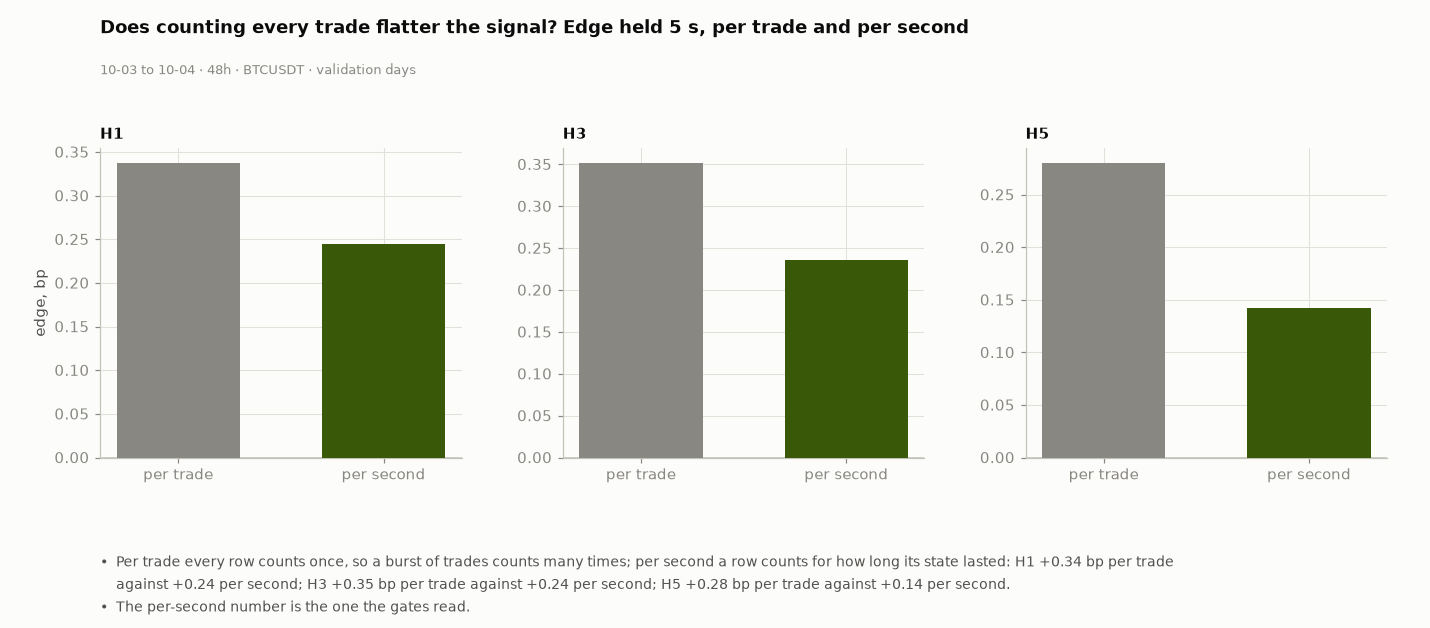

In [13]:
# ---- 4. the weighting: the same edge per trade and per second of time ----
WT = A.weighting_table(VAL, CLIP, TH)
_wt = WT.pivot(index="hyp", columns="weighting", values="edge_bp")
fig, ax = FG.frame(3.6, ["Per trade every row counts once, so a burst of trades counts many times; per second a row counts for how long its state lasted: " +
                         "; ".join(f"{h_} {_wt.loc[h_, 'per trade']:+.2f} bp per trade against {_wt.loc[h_, 'per second']:+.2f} per second" for h_ in _wt.index) + ".",
                         "The per-second number is the one the gates read."], "Does counting every trade flatter the signal? Edge held 5 s, per trade and per second", WIN_VAL, ncols=3)
for a, hy in zip(ax, ("H1", "H3", "H5")):
    d = WT[WT.hyp == hy].set_index("weighting")
    x = np.arange(2)
    a.bar(x, [d.loc["per trade", "edge_bp"], d.loc["per second", "edge_bp"]], color=[FG.N["muted"], FG.BIN], width=0.6, zorder=3)
    a.set_xticks(x)
    a.set_xticklabels(["per trade", "per second"])
    a.set_title(hy)
    FG.zero(a)
ax[0].set_ylabel("edge, bp")
figstyle.show(fig, "fig:s2-weighting", FIGURES)

In [14]:
gc.collect()
# ---- 1. the pack is the study's signal; the engine is exact (nine hand-computed cases, including a book row after the fill time that must not be read) ----
_day = ST.Day(VAL_DAYS[0], "BTCUSDT")
CHK = PK.check_against_features(_day)
_day.drop_tape()
SELF_BT = BT.selftest()
display(Markdown(f"**The pack against the feature engine** on {VAL_DAYS[0]}: {CHK['rows']:,} instants, largest difference {CHK['max_abs_diff']:.2e}, equal to float32 round-off: **{CHK['equal']}**. **Engine hand-computed cases:** {'all nine hold' if SELF_BT else 'FAILED'} (fill price and shares, fee, the Down mirror, the sale into the bids, the price band, the time-left filter, the first and last 10 s, one position at a time, a hold ends the window, the delay reads the right row)."))
assert CHK["equal"] and SELF_BT
VERIFY["passed"] += 1 + 9; VERIFY["total"] += 1 + 9           # the pack check, and the nine hand-computed engine cases
GATES.append({"id": "G3", "section": "S2", "label": "Pack is the signal", "name": "lift_pack.z_one_second equals the feature engine's z_1s at every instant of a day, and the engine's nine hand-computed cases hold",
              "reading": f"{CHK['rows']:,} instants equal (largest difference {CHK['max_abs_diff']:.1e}); engine cases 9 of 9", "verdict": "PASS", "would_change": "a pack value that differs from the feature engine, or a hand-computed case that fails"})

**The pack against the feature engine** on 2026-10-03: 210,743 instants, largest difference 3.05e-05, equal to float32 round-off: **True**. **Engine hand-computed cases:** all nine hold (fill price and shares, fee, the Down mirror, the sale into the bids, the price band, the time-left filter, the first and last 10 s, one position at a time, a hold ends the window, the delay reads the right row).

In [15]:
# ---- 2. the validation days through the registered grid: every window, every configuration (the Binance signal, the pinned ladders, the fill) ----
t0 = time.time()
VAL_ENT, VAL_WIN, VAL_LAG = [], [], []
for d in VAL_DAYS:
    e_, w_, l_ = BR.run_day(d, GRID, lag=True)
    VAL_ENT.append(e_); VAL_WIN.append(w_); VAL_LAG.append(l_)
    print(f"{d}: {len(e_):,} entries over {len(GRID)} configurations in {time.time() - t0:.0f}s")
VAL_ENT = pd.concat(VAL_ENT, ignore_index=True)
VAL_WIN = pd.concat(VAL_WIN, ignore_index=True)
N_TESTS["registered grid, Polymarket validation days (configurations)"] = N_TRIALS
COV = VAL_WIN.groupby("day").agg(windows=("slug", "size"), with_book=("status", lambda s: int((s == "ok").sum())), signals=("triggers", "sum"))
COV["share"] = COV.with_book / COV.windows
display(HTML(COV.round(3).to_html(border=0)))
_share = float(COV.with_book.sum() / COV.windows.sum())
GATES.append({"id": "G4", "section": "S2", "label": "Windows have a book", "name": "at least nine in ten validation windows have a pinned ladder",
              "reading": f"{int(COV.with_book.sum())} of {int(COV.windows.sum())} windows ({pct(_share)})", "verdict": "PASS" if _share >= 0.9 else "FAIL", "would_change": "a window whose ladder is not pinned counts here"})

2026-10-03: 7,175 entries over 24 configurations in 18s


2026-10-04: 8,991 entries over 24 configurations in 36s


,windows,with_book,signals,share
day,,,,
2026-10-03,96,96,1514,1.0
2026-10-04,96,96,2359,1.0


**After a signal, in the signal's direction (3,764 signals on 2 validation days):** at +150 ms the Binance-implied P(Up) has moved +1.59 cents and the Up mid +0.41; at +1 s +2.08 and +3.73; at +5 s +2.99 and +4.07. The book moves +3.34 cents in the signal direction between +150 ms and +1150 ms. Median spread at +150 ms: 1.0 cents.

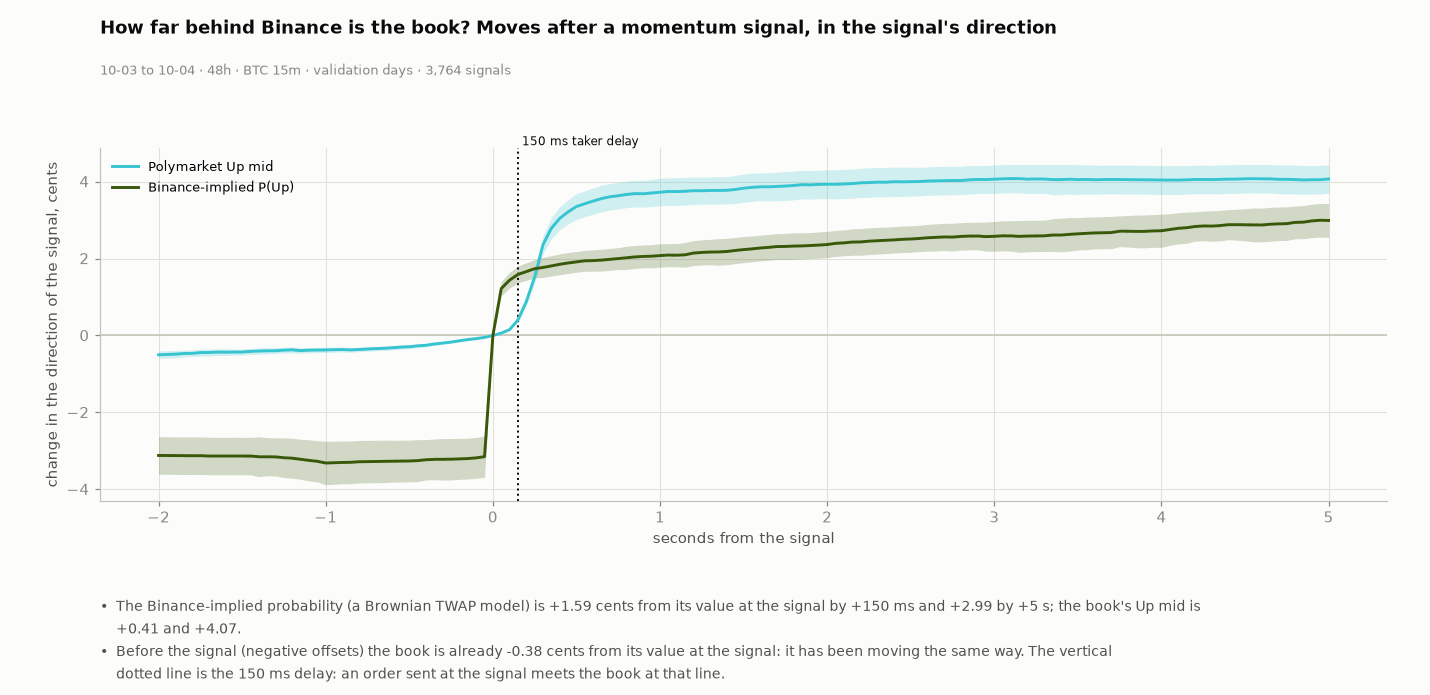

In [16]:
# ---- 3. how far behind Binance is the book? the Up mid and a Binance-implied P(Up) after a signal, in the signal's direction, cents ----
def lag_stack(lags):
    ls = [l_ for l_ in lags if l_ is not None]
    return {k_: np.concatenate([l_[k_] for l_ in ls]) for k_ in ls[0]}
LG = lag_stack(VAL_LAG)
OFF = BT.LAG_OFFSETS_MS
def lag_curve(arr, slug):
    """mean over signals by offset, with a 95% interval clustered by window (bootstrap of windows)."""
    m = np.nanmean(arr, axis=0)
    u, inv = np.unique(slug, return_inverse=True)
    S = np.zeros((len(u), arr.shape[1])); C = np.zeros((len(u), arr.shape[1]))
    ok = np.isfinite(arr)
    np.add.at(S, inv, np.where(ok, arr, 0.0)); np.add.at(C, inv, ok.astype(float))
    rng = np.random.default_rng(SEED)
    idx = rng.integers(0, len(u), size=(400, len(u)))
    boots = S[idx].sum(1) / np.maximum(C[idx].sum(1), 1)
    return m * 100, np.percentile(boots, 2.5, axis=0) * 100, np.percentile(boots, 97.5, axis=0) * 100
M_MID, M_LO, M_HI = lag_curve(LG["mid"], LG["slug"])
M_FAIR, F_LO, F_HI = lag_curve(LG["fair"], LG["slug"])
_o = lambda ms: int(np.where(OFF == ms)[0][0])
LAG_CENTS = float(np.nanmean(LG["mid"][:, _o(1150)] - LG["mid"][:, _o(150)]) * 100)           # the registered lag metric: Up-mid move in the signal direction, +150 ms to +1150 ms
display(Markdown(f"**After a signal, in the signal's direction ({len(LG['mid']):,} signals on {len(VAL_DAYS)} validation days):** at +150 ms the Binance-implied P(Up) has moved {M_FAIR[_o(150)]:+.2f} cents and the Up mid {M_MID[_o(150)]:+.2f}; at +1 s {M_FAIR[_o(1000)]:+.2f} and {M_MID[_o(1000)]:+.2f}; at +5 s {M_FAIR[_o(5000)]:+.2f} and {M_MID[_o(5000)]:+.2f}. "
                 f"The book moves {LAG_CENTS:+.2f} cents in the signal direction between +150 ms and +1150 ms. Median spread at +150 ms: {np.nanmedian(LG['spread150']) * 100:.1f} cents."))
_bul = [f"The Binance-implied probability (a Brownian TWAP model) is {M_FAIR[_o(150)]:+.2f} cents from its value at the signal by +150 ms and {M_FAIR[_o(5000)]:+.2f} by +5 s; the book's Up mid is {M_MID[_o(150)]:+.2f} and {M_MID[_o(5000)]:+.2f}.",
        f"Before the signal (negative offsets) the book is already {M_MID[_o(-1000)]:+.2f} cents from its value at the signal: it has been moving the same way. The vertical dotted line is the 150 ms delay: an order sent at the signal meets the book at that line."]
fig, ax = FG.frame(4.0, _bul, "How far behind Binance is the book? Moves after a momentum signal, in the signal's direction", WIN_PM_VAL + f" · {len(LG['mid']):,} signals")
a = ax[0]
FG.band(a, OFF / 1000, M_MID, (M_HI - M_LO) / 3.92, FG.PM, "Polymarket Up mid", marker=None)
FG.band(a, OFF / 1000, M_FAIR, (F_HI - F_LO) / 3.92, FG.BIN, "Binance-implied P(Up)", marker=None)
a.axvline(LAT_MS / 1000, color=FG.N["ink"], ls=":", lw=1.3)
a.annotate(f" {LAT_MS} ms taker delay", xy=(LAT_MS / 1000, 1.0), xycoords=("data", "axes fraction"), va="bottom", fontsize=8, color=FG.N["ink"])
FG.zero(a)
a.set_xlabel("seconds from the signal"); a.set_ylabel("change in the direction of the signal, cents")
a.legend(loc="upper left", fontsize=8.5)
figstyle.show(fig, "fig:s2-lag", FIGURES)

**Gate to S3.** Part A: the stand-in for the market's reference and the venue's candles agree with the tape, and no feature reads past its instant (G1, G2). The first test-day read is S3. Part B: the pack is the study's signal, the engine reproduces its hand-computed cases, the books are there, and the book's lag behind Binance is measured above (G3, G4).

## S3 · Core result

| question | gate to S4 |
|---|---|
| Part A: does the trade price alone predict the next move, and does it continue or reverse? | at least one pre-registered hypothesis holds on the validation days and again on the test days, in the registered direction (G5 to G10) |
| Part B: does the pack earn money on Polymarket, unlevered, on the test days, after the fee, the spread and the fill? | the chosen configuration's net PnL per entry on the test days is above zero and its window-cluster 95% interval is above zero (F5) |

### Does a big move keep going?

In [17]:
ANS1 = display(Markdown("_The answer is written here when the run reaches the delay table._"), display_id=True)

**Yes.** After a one-second move of at least one volatility the Binance price goes on the same way: H1 momentum earns +0.409 bp over the next 5 s at the 150 ms delay (t +34, test days 10-05 to 10-06 · 48h · BTCUSDT · test days), against +0.426 with no delay; 6 of the 8 registered hypotheses are confirmed on the validation days and again on the test days.

Part A. A move is big when the last second of Binance BTC moved by at least one volatility, the usual size of a one-second move. The test days stay closed until the protocol is committed (below); the exploratory scan, the curves and the six pre-registered hypotheses follow.

**The protocol is frozen; the test days are read here for the first time**

The confirmatory family, its directions, horizons, gates and decision rules are the committed file `lift_protocol.py`. The cell below refuses to go on if that file has an uncommitted change, prints the commit it is run against, and only then builds the test days.

In [18]:
# ---- the protocol is committed and unchanged; only now do the test days get built (returns, features, outcomes) ----
_st = subprocess.run(["git", "status", "--porcelain", "--", "lift_protocol.py"], capture_output=True, text=True, cwd=".").stdout.strip()
PROTO = subprocess.run(["git", "log", "-1", "--format=%h %cI", "--", "lift_protocol.py"], capture_output=True, text=True, cwd=".").stdout.strip()
assert _st == "" and PROTO, f"lift_protocol.py has an uncommitted change or no commit ({_st!r}): freeze it before the test days are read"
PROTO_FROZEN = "c63060b2"          # the commit that fixed the decision rules, before any test-day number was read; the later commit of the file changed an unused annotation only
display(Markdown(f"**Protocol:** the decision rules were committed in `{PROTO_FROZEN}`; the file's last commit is `{PROTO}` (a lint fix to an annotation, no rule), unchanged in the working tree. Test days built next: {', '.join(TEST_DAYS)}."))
t0 = time.time()
TEST = ST.load_days(TEST_DAYS, SYMBOL)
OOS = {**VAL, **TEST}
print(f"built {len(TEST)} test days in {time.time() - t0:.0f}s")
display(HTML(A.tape_summary(TEST).round(2).to_html(index=False, border=0)))
COH_ALL = ST.Cohort(OOS, ST.all_targets(), CLIP)
print("out-of-sample cohort:", len(COH_ALL.T), "rows,", COH_ALL.Y.shape[1], "targets")

**Protocol:** the decision rules were committed in `c63060b2`; the file's last commit is `759c0087 2026-10-07T19:24:57+01:00` (a lint fix to an annotation, no rule), unchanged in the working tree. Test days built next: 2026-10-05, 2026-10-06.

built 2 test days in 20s


day,aggtrades,distinct_ms,instants,dropped_edge,gaps_over_5s,longest_gap_s,price_lo,price_hi,days_read
2026-10-05,848139,1152586,431122,0,36,9.16,84972.01,86999.11,"10-04,10-05,10-06"
2026-10-06,811872,2678566,426772,0,28,8.04,85136.11,86698.99,"10-05,10-06,10-07"


out-of-sample cohort: 1363329 rows, 77 targets


**The exploratory scan: every price feature against every target**

For every price-only feature and each target (the delayed entry at every holding time, and the instant itself at 1, 5 and 10 s): the correlation on the fit days, then on the validation days with the fit-day bins. **This is exploratory.** The number of tests is printed, and the confirmation of S3 does not depend on it.

In [19]:
t0 = time.time()
SCAN, EDGES = A.run_scan(FIT, VAL, NAMES, A.scan_targets(), CLIP)
SS = A.scan_summary(SCAN)
N_TESTS["exploratory scan (features x targets)"] = SS["n_tests"]
print(f"scan done in {time.time() - t0:.0f}s: {SS['n_tests']:,} feature-target tests ({SS['n_features']} features x {SS['n_targets']} targets)")
_d = SCAN[(SCAN.L_ms == LAT_BAR_MS) & (SCAN.h_s.isin((1.0, 5.0, 30.0)))].copy()
_d["abs_t"] = _d.t.abs()
_top = _d.sort_values("abs_t", ascending=False).groupby("h_s").head(6).sort_values(["h_s", "abs_t"], ascending=[True, False])
display(Markdown(f"**Strongest features on the validation days, entered {LAT_BAR_MS} ms later** (fit-day correlation beside it; bins from the fit days)\n\n| Hold | Feature | Fit corr | Validation corr | Validation t | Days with the fit sign | Edge of the sign trade |\n|---|---|---|---|---|---|---|\n" +
                 "\n".join(f"| {r.h_s:g} s | {r.feature} | {r.rho_fit:+.3f} | {r.rho:+.3f} | {r.t:+.1f} | {r.days_same_sign} of {r.n_days} | {r.edge_bp:+.3f} bp |" for r in _top.itertuples())))
display(Markdown(f"{SS['survive']:,} of {SS['n_tests']:,} feature-target tests ({pct(SS['survive_share'])}) reach |t| of {T_BAR:g} on the validation days with the fit-day sign on every validation day; they come from {SS['survive_features']} of the {SS['n_features']} features. With this many tests, some would at |t| of {T_BAR:g} by chance alone; the point of the scan is to see which families lead, then to confirm a few of them (S3) on days that played no part."))

scan done in 284s: 1,722 feature-target tests (123 features x 14 targets)


**Strongest features on the validation days, entered 150 ms later** (fit-day correlation beside it; bins from the fit days)

| Hold | Feature | Fit corr | Validation corr | Validation t | Days with the fit sign | Edge of the sign trade |
|---|---|---|---|---|---|---|
| 1 s | agree_4 | +0.131 | +0.066 | +23.8 | 2 of 2 | +0.012 bp |
| 1 s | agree_6 | +0.117 | +0.066 | +23.6 | 2 of 2 | +0.011 bp |
| 1 s | pctrange_10s | +0.096 | +0.054 | +23.4 | 2 of 2 | +0.009 bp |
| 1 s | pctrange_5s | +0.107 | +0.051 | +23.0 | 2 of 2 | +0.010 bp |
| 1 s | newhi_5s | +0.142 | +0.078 | +20.8 | 2 of 2 | +0.045 bp |
| 1 s | pctrange_3s | +0.108 | +0.044 | +20.7 | 2 of 2 | +0.011 bp |
| 5 s | agree_6 | +0.142 | +0.105 | +22.0 | 2 of 2 | +0.050 bp |
| 5 s | pctrange_10s | +0.124 | +0.088 | +21.8 | 2 of 2 | +0.041 bp |
| 5 s | agree_4 | +0.154 | +0.098 | +21.7 | 2 of 2 | +0.048 bp |
| 5 s | pctrange_5s | +0.130 | +0.077 | +21.2 | 2 of 2 | +0.043 bp |
| 5 s | newhi_10s | +0.148 | +0.122 | +19.9 | 2 of 2 | +0.236 bp |
| 5 s | newhi_5s | +0.154 | +0.103 | +19.7 | 2 of 2 | +0.162 bp |
| 30 s | pctrange_10s | +0.079 | +0.086 | +17.9 | 2 of 2 | +0.127 bp |
| 30 s | pctrange_5s | +0.078 | +0.068 | +17.1 | 2 of 2 | +0.124 bp |
| 30 s | agree_6 | +0.089 | +0.101 | +16.7 | 2 of 2 | +0.140 bp |
| 30 s | pctrange_30s | +0.065 | +0.090 | +15.6 | 2 of 2 | +0.113 bp |
| 30 s | pctrange_3s | +0.070 | +0.052 | +15.5 | 2 of 2 | +0.119 bp |
| 30 s | agree_4 | +0.091 | +0.082 | +15.5 | 2 of 2 | +0.122 bp |

1,162 of 1,722 feature-target tests (67.5%) reach |t| of 3 on the validation days with the fit-day sign on every validation day; they come from 94 of the 123 features. With this many tests, some would at |t| of 3 by chance alone; the point of the scan is to see which families lead, then to confirm a few of them (S3) on days that played no part.

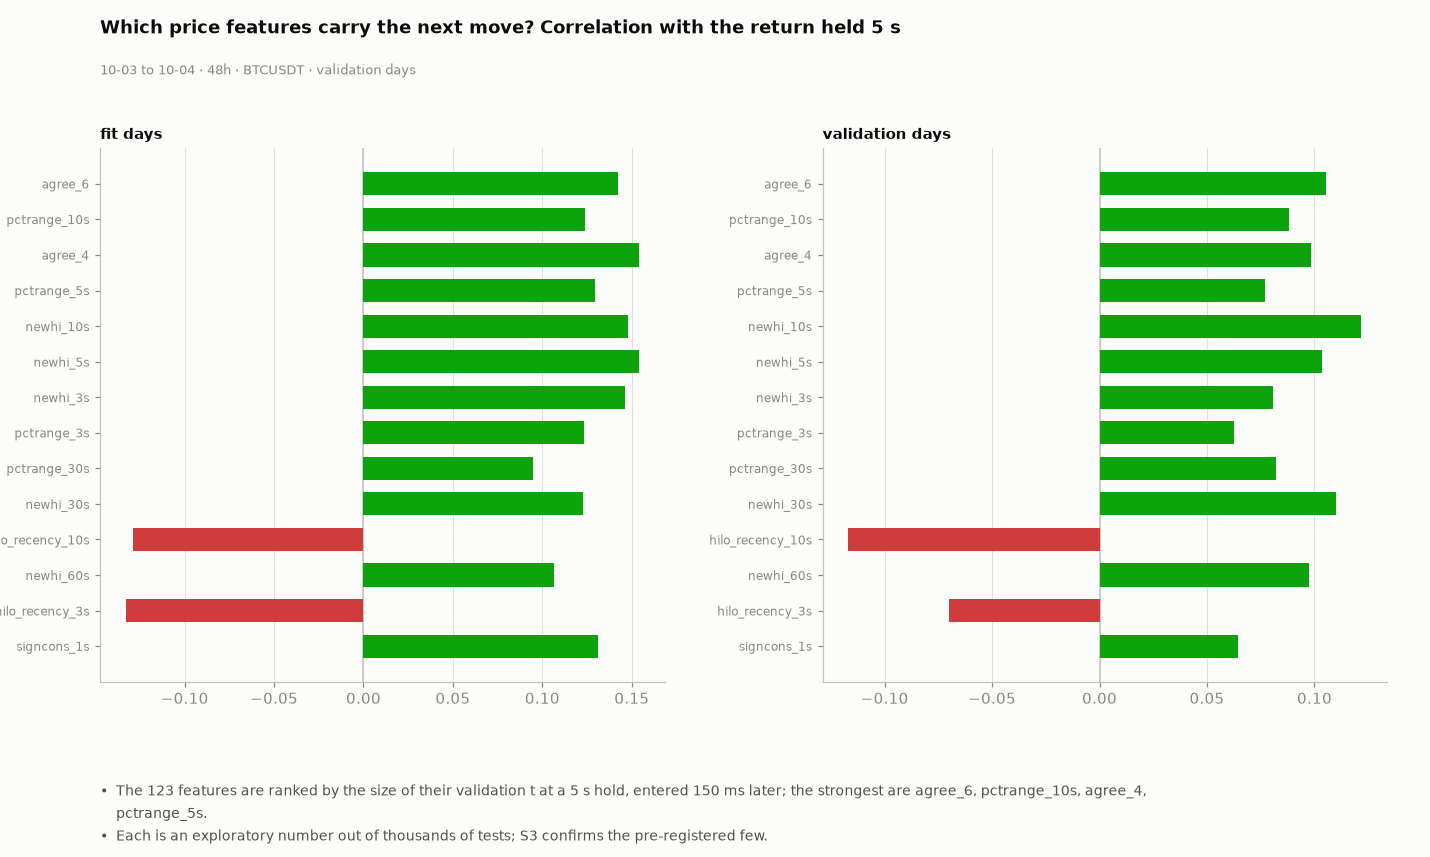

In [20]:
_bul = [f"The {len(SCAN[(SCAN.h_s == 5.0) & (SCAN.L_ms == LAT_BAR_MS)])} features are ranked by the size of their validation t at a 5 s hold, entered {LAT_BAR_MS} ms later; the strongest are " +
        ", ".join(SCAN[(SCAN.h_s == 5.0) & (SCAN.L_ms == LAT_BAR_MS)].assign(a=lambda d: d.t.abs()).sort_values("a", ascending=False).feature.head(4).tolist()) + ".",
        "Each is an exploratory number out of thousands of tests; S3 confirms the pre-registered few."]
fig = FG.top_features(SCAN, WIN_VAL, _bul)
figstyle.show(fig, "fig:s3-scan", FIGURES)

**Momentum or mean reversion: the conditional-return curves**

Every curve on the validation and test days together, with the fit-day bins and thresholds, entered 150 ms after the instant. The line is a mean return in basis points; the band is a 95% interval clustered by 10-second block.

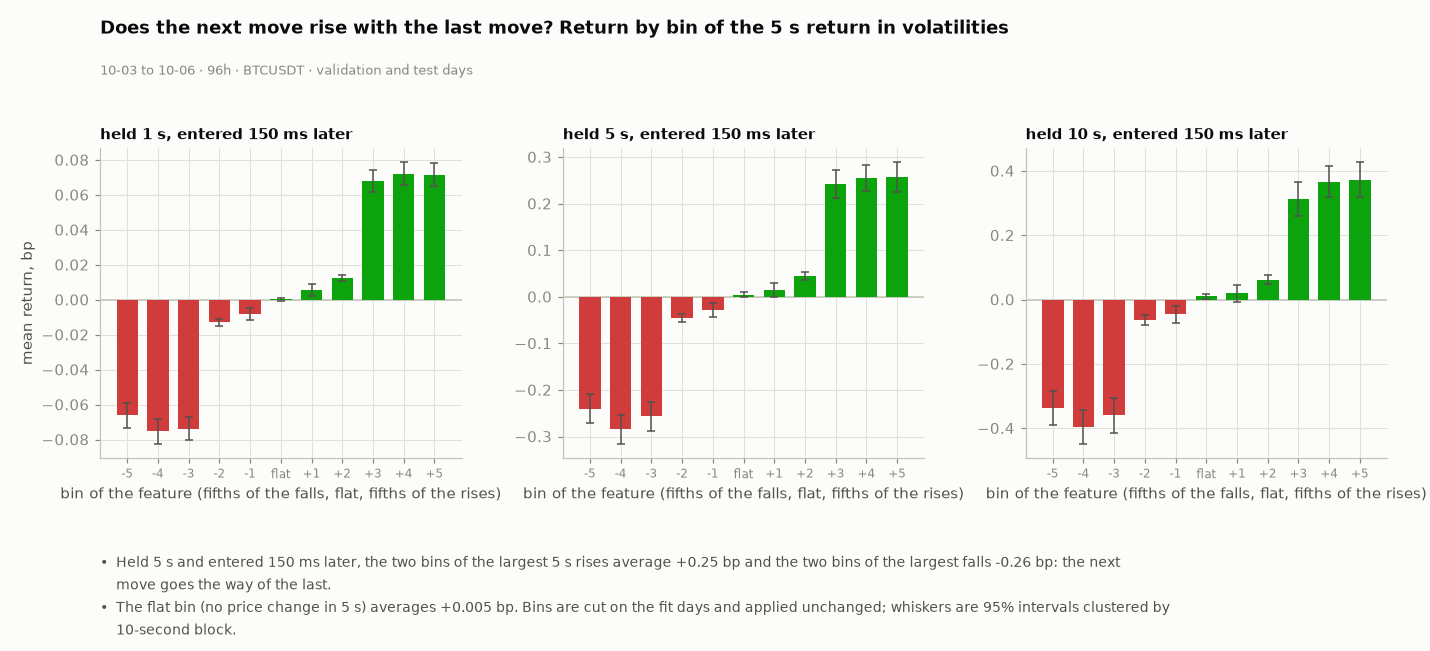

In [21]:
# ---- Test: does the next move rise with the last move? (return by bin of the 5 s return, in volatilities; bins cut on the fit days) ----
_x5f, _wf = ST.stack(FIT, "z_5s"), ST.stack(FIT, "W")
E5 = ST.signed_edges(_x5f, _wf)
DEC5 = A.decile_curve(COH_ALL, ST.stack(OOS, "z_5s"), E5)
_d = DEC5[(DEC5.h_s == 5.0) & (DEC5.L_ms == LAT_BAR_MS)].sort_values("decile")
_hi, _lo = _d[_d.decile >= 9].mean_bp.mean(), _d[_d.decile <= 3].mean_bp.mean()
_bul = [f"Held 5 s and entered {LAT_BAR_MS} ms later, the two bins of the largest 5 s rises average {sgn(_hi)} bp and the two bins of the largest falls {sgn(_lo)} bp: the next move goes the way of the last.",
        f"The flat bin (no price change in 5 s) averages {sgn(float(_d[_d.decile == 6].mean_bp.iloc[0]), 3)} bp. Bins are cut on the fit days and applied unchanged; whiskers are 95% intervals clustered by 10-second block."]
fig = FG.deciles(DEC5, "the 5 s return in volatilities", (1.0, 5.0, 10.0), WIN_OOS, _bul)
figstyle.show(fig, "fig:s3-deciles", FIGURES)

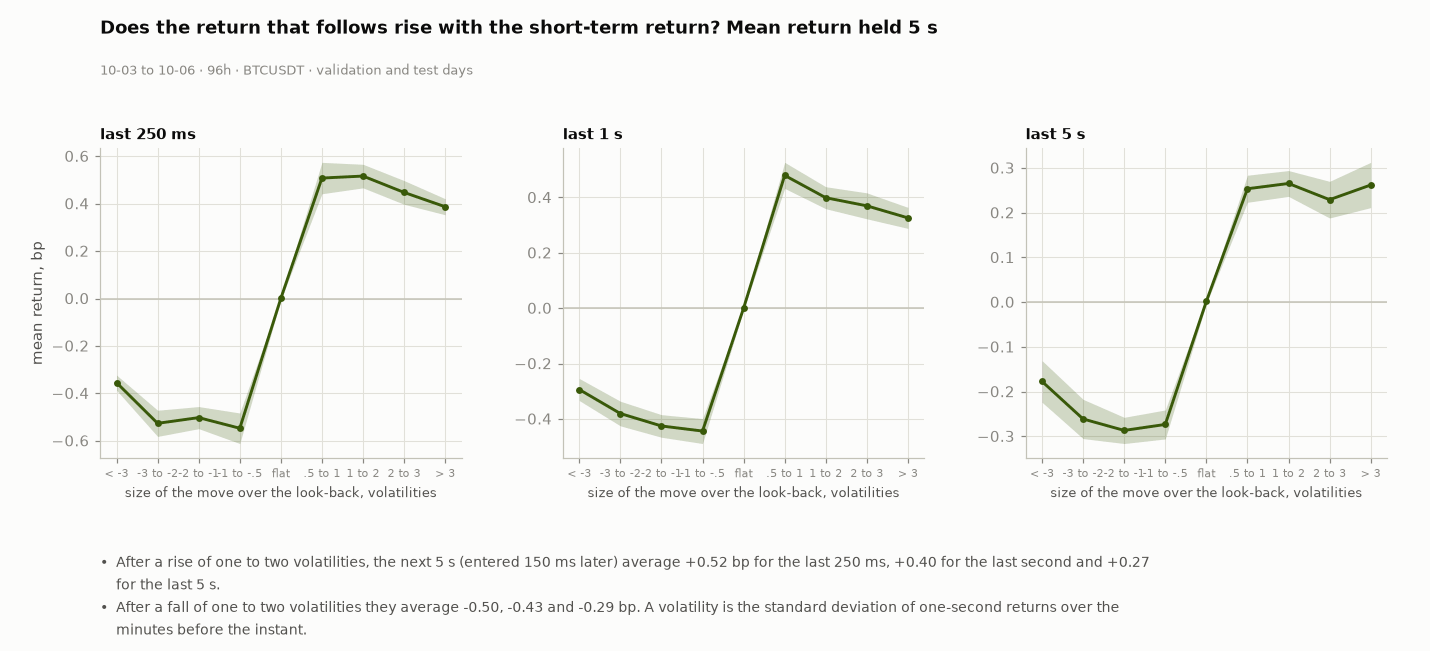

In [22]:
# ---- Test: the shortest looks: 250 ms, 1 s and 5 s returns, in volatilities, against the return held 5 s ----
SIG_EDGES = np.array([-3.0, -2.0, -1.0, -0.5, 0.5, 1.0, 2.0, 3.0])
SIG_LAB = ["< -3", "-3 to -2", "-2 to -1", "-1 to -.5", "flat", ".5 to 1", "1 to 2", "2 to 3", "> 3"]
_sig = lambda days: ST.stack(days, "sigma_slow").astype(np.float64)
_z250 = ST.stack(OOS, "ret_250ms") / (_sig(OOS) * 0.5)
_dfs = {"last 250 ms": A.decile_curve(COH_ALL, _z250, SIG_EDGES), "last 1 s": A.decile_curve(COH_ALL, ST.stack(OOS, "z_1s"), SIG_EDGES), "last 5 s": A.decile_curve(COH_ALL, ST.stack(OOS, "z_5s"), SIG_EDGES)}
_get = lambda n, k: float(_dfs[n][(_dfs[n].h_s == 5.0) & (_dfs[n].L_ms == LAT_BAR_MS) & (_dfs[n].decile == k)].mean_bp.iloc[0])
_bul = [f"After a rise of one to two volatilities, the next 5 s (entered {LAT_BAR_MS} ms later) average {sgn(_get('last 250 ms', 7))} bp for the last 250 ms, {sgn(_get('last 1 s', 7))} for the last second and {sgn(_get('last 5 s', 7))} for the last 5 s.",
        f"After a fall of one to two volatilities they average {sgn(_get('last 250 ms', 3))}, {sgn(_get('last 1 s', 3))} and {sgn(_get('last 5 s', 3))} bp. A volatility is the standard deviation of one-second returns over the minutes before the instant."]
fig = FG.bins_panels(_dfs, SIG_LAB, WIN_OOS, _bul, "Does the return that follows rise with the short-term return? Mean return held 5 s", "size of the move over the look-back, volatilities")
figstyle.show(fig, "fig:s3-shortret", FIGURES)

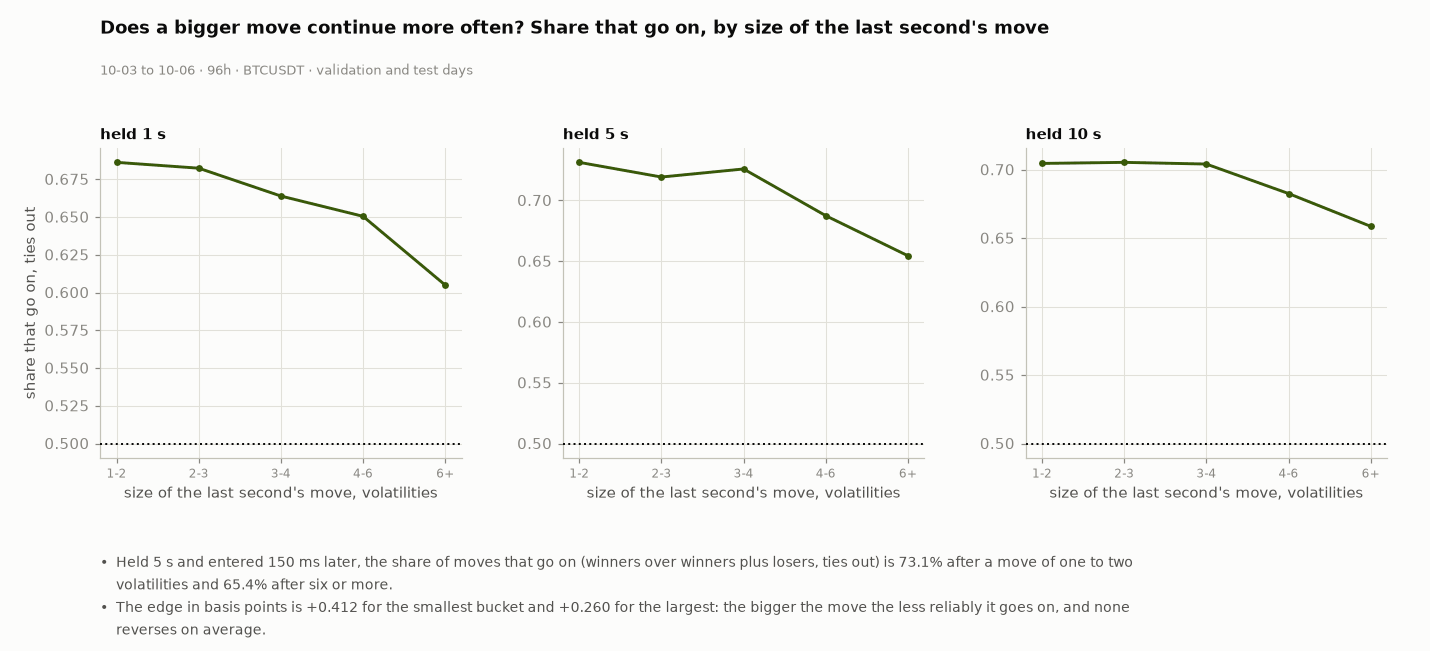

In [23]:
# ---- Test: does a bigger move continue more often? (continuation share by size of the last second's move) ----
Z1 = ST.stack(OOS, "z_1s").astype(np.float64)
CUR = A.z_curve(COH_ALL, Z1)
CUR_LAB = ["1-2", "2-3", "3-4", "4-6", "6+"]
_c = CUR[(CUR.L_ms == LAT_BAR_MS) & (CUR.h_s == 5.0)]
_bul = [f"Held 5 s and entered {LAT_BAR_MS} ms later, the share of moves that go on (winners over winners plus losers, ties out) is {pct(float(_c.win_share.iloc[0]))} after a move of one to two volatilities and {pct(float(_c.win_share.iloc[-1]))} after six or more.",
        f"The edge in basis points is {sgn(float(_c.edge_bp.iloc[0]), 3)} for the smallest bucket and {sgn(float(_c.edge_bp.iloc[-1]), 3)} for the largest: the bigger the move the less reliably it goes on, and none reverses on average."]
fig = FG.buckets_line(CUR[CUR.L_ms == LAT_BAR_MS], "bucket", "win_share", None, CONFIRM_H, WIN_OOS, _bul, "Does a bigger move continue more often? Share that go on, by size of the last second's move",
                      "size of the last second's move, volatilities", "share that go on, ties out", ref=0.5, labels=CUR_LAB)
figstyle.show(fig, "fig:s3-continuation", FIGURES)

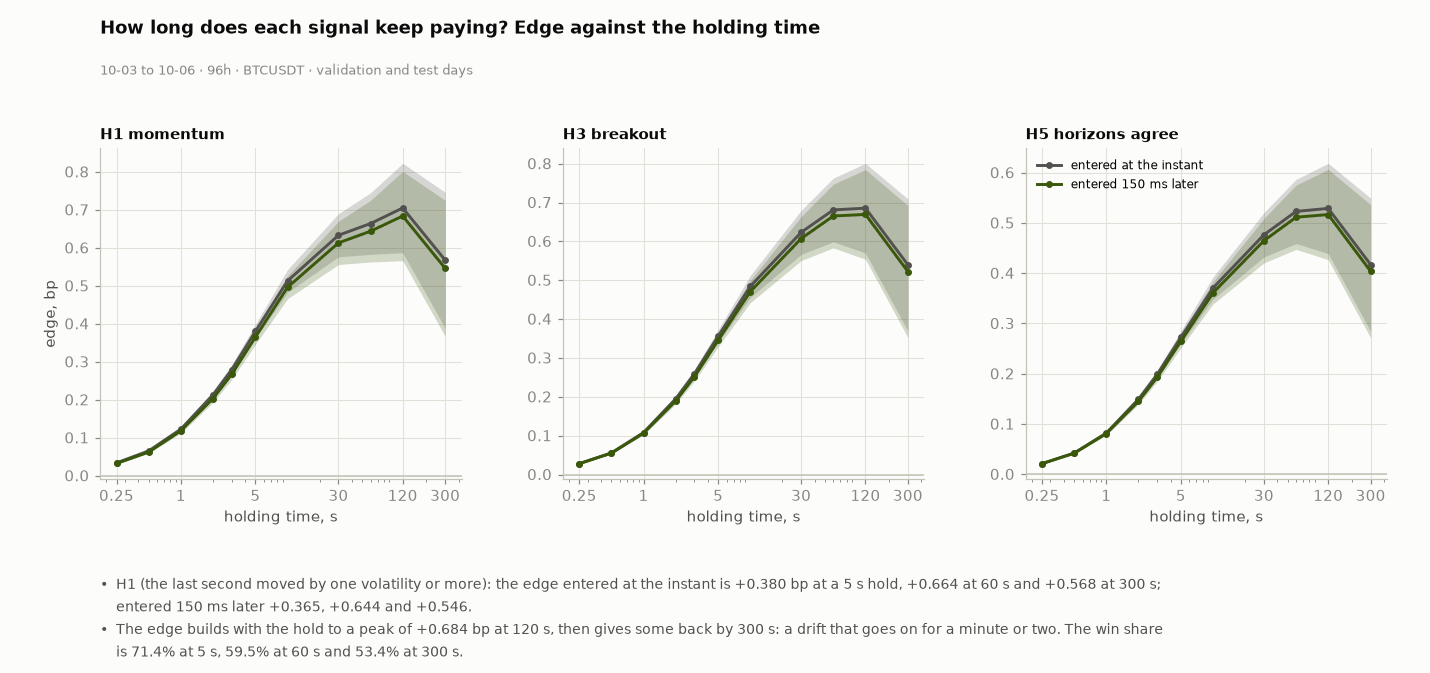

In [24]:
# ---- Test: how long does it keep paying? (edge against the hold for H1, H3, H5; entered at the instant and 150 ms later) ----
M_OOS = P.masks(OOS, TH)
LAT_TAB = {nm: ST.lat_table(COH_ALL, *M_OOS[h]) for nm, h in (("H1 momentum", "H1"), ("H3 breakout", "H3"), ("H5 horizons agree", "H5"))}
_t1 = LAT_TAB["H1 momentum"]
_at = lambda L, h: _t1[(_t1.L_ms == L) & (_t1.h_s == h)].iloc[0]
_bul = [f"H1 (the last second moved by one volatility or more): the edge entered at the instant is {sgn(_at(0, 5.0).edge_bp, 3)} bp at a 5 s hold, {sgn(_at(0, 60.0).edge_bp, 3)} at 60 s and {sgn(_at(0, 300.0).edge_bp, 3)} at 300 s; entered {LAT_BAR_MS} ms later {sgn(_at(LAT_BAR_MS, 5.0).edge_bp, 3)}, {sgn(_at(LAT_BAR_MS, 60.0).edge_bp, 3)} and {sgn(_at(LAT_BAR_MS, 300.0).edge_bp, 3)}.",
        f"The edge builds with the hold to a peak of {sgn(float(_t1[_t1.L_ms == LAT_BAR_MS].set_index(chr(104) + chr(95) + chr(115)).edge_bp.max()), 3)} bp at {float(_t1[_t1.L_ms == LAT_BAR_MS].set_index(chr(104) + chr(95) + chr(115)).edge_bp.idxmax()):g} s, then gives some back by 300 s: a drift that goes on for a minute or two. The win share is {pct(_at(LAT_BAR_MS, 5.0).win_share)} at 5 s, {pct(_at(LAT_BAR_MS, 60.0).win_share)} at 60 s and {pct(_at(LAT_BAR_MS, 300.0).win_share)} at 300 s."]
fig = FG.horizon_curves(LAT_TAB, ST.LF.HORIZONS_S, WIN_OOS, _bul)
figstyle.show(fig, "fig:s3-horizon", FIGURES)

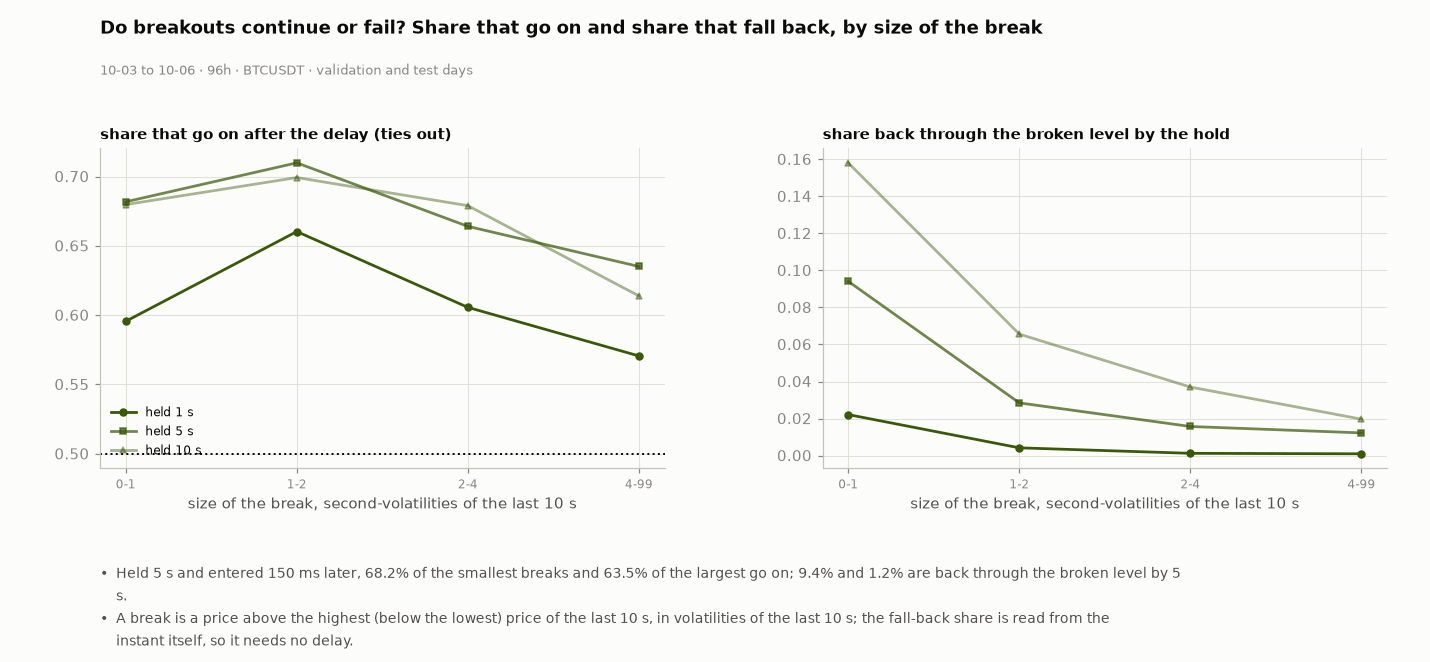

In [25]:
# ---- Test: do breakouts continue or fail? (share that go on, and share that fall back through the broken level) ----
_Y = ST.stack(OOS, "Y")
Y0 = np.stack([_Y[:, 0, ST.H_IDX[h]] for h in CONFIRM_H], axis=1)
BRK = A.breakout_curve(COH_ALL, ST.stack(OOS, "breakout_z_10s").astype(np.float64), ST.stack(OOS, "breakout_10s").astype(np.float64), Y0, hs=CONFIRM_H)
_b5 = BRK[BRK.h_s == 5.0]
_bul = [f"Held 5 s and entered {LAT_BAR_MS} ms later, {pct(float(_b5.win_share.iloc[0]))} of the smallest breaks and {pct(float(_b5.win_share.iloc[-1]))} of the largest go on; {pct(float(_b5.fall_back.iloc[0]))} and {pct(float(_b5.fall_back.iloc[-1]))} are back through the broken level by 5 s.",
        "A break is a price above the highest (below the lowest) price of the last 10 s, in volatilities of the last 10 s; the fall-back share is read from the instant itself, so it needs no delay."]
fig = FG.breakout_fig(BRK, CONFIRM_H, WIN_OOS, _bul)
figstyle.show(fig, "fig:s3-breakout", FIGURES)

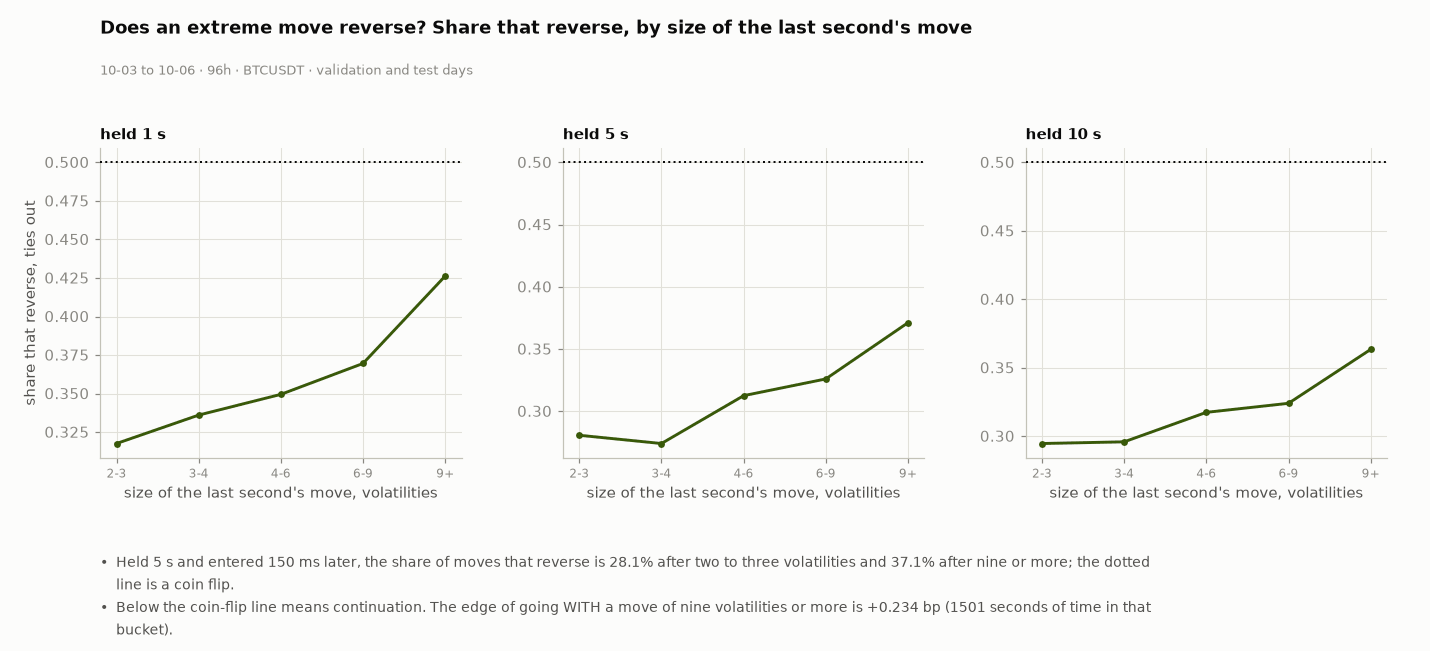

In [26]:
# ---- Test: does an extreme move reverse? (share that reverse after a move of two to nine and more volatilities in a second) ----
REV = A.z_curve(COH_ALL, Z1, edges=((2, 3), (3, 4), (4, 6), (6, 9), (9, 99)))
REV["rev_share"] = 1.0 - REV.win_share
REV_LAB = ["2-3", "3-4", "4-6", "6-9", "9+"]
_r = REV[(REV.L_ms == LAT_BAR_MS) & (REV.h_s == 5.0)]
_bul = [f"Held 5 s and entered {LAT_BAR_MS} ms later, the share of moves that reverse is {pct(float(_r.rev_share.iloc[0]))} after two to three volatilities and {pct(float(_r.rev_share.iloc[-1]))} after nine or more; the dotted line is a coin flip.",
        f"Below the coin-flip line means continuation. The edge of going WITH a move of nine volatilities or more is {sgn(float(_r.edge_bp.iloc[-1]), 3)} bp ({int(round(float(_r.seconds.iloc[-1])))} seconds of time in that bucket)."]
fig = FG.buckets_line(REV[REV.L_ms == LAT_BAR_MS], "bucket", "rev_share", None, CONFIRM_H, WIN_OOS, _bul, "Does an extreme move reverse? Share that reverse, by size of the last second's move",
                      "size of the last second's move, volatilities", "share that reverse, ties out", ref=0.5, labels=REV_LAB)
figstyle.show(fig, "fig:s3-reversal", FIGURES)

**The confirmation: the six pre-registered hypotheses, validation days then test days**

Each hypothesis has a fixed signal, gate, direction (trade with the move, or against it) and the horizons of 1, 5 and 10 s at the 150 ms delay. One holds only if the cluster t is at least the bar at every horizon, on the validation days and again on the test days, and the edge is positive on every day that had rows. The bar is the parameter T_BAR; the family is one test per hypothesis and horizon (H6 counts its three terciles).

In [27]:
FAM_VAL = P.family_table(VAL, CLIP, TH)
FAM_TEST = P.family_table(TEST, CLIP, TH)
DEC = P.decide(FAM_VAL, FAM_TEST)
PACK = P.choose_pack(FAM_VAL)
N_TESTS["confirmatory family (hypotheses x horizons)"] = int(len(FAM_VAL))
def fam_md(tab, title):
    rows = []
    for r in tab.itertuples():
        pdays = " / ".join("n/a" if (isinstance(p, float) and math.isnan(p)) else f"{p:+.2f}" for p in r.per_day)
        rows.append(f"| {r.hyp} | {r.h_s:g} s | {r.edge_bp:+.3f} | {r.se:.3f} | {r.t:+.1f} | {pct(r.win_share)} | {r.seconds / 60:,.0f} | {pdays} |")
    return f"**{title}**\n\n| Hypothesis | Hold | Edge, bp | Std error | t | Win share | Minutes on | Edge by day, bp |\n|---|---|---|---|---|---|---|---|\n" + "\n".join(rows)
display(Markdown(fam_md(FAM_VAL, f"Validation days ({', '.join(VAL_DAYS)})")))
display(Markdown(fam_md(FAM_TEST, f"Test days ({', '.join(TEST_DAYS)}), read once")))
display(Markdown("**Decision by the registered rules:** " + "; ".join(f"{h_} {v_}" for h_, v_ in DEC.items()) + f". **Strongest simple signal (largest validation edge at {LAT_BAR_MS} ms and 5 s among the confirmed H1, H2, H3, H5): {PACK}.**"))
assert PACK is not None, "no candidate holds on the validation days: the study ends here with NO SIGNAL"
_lab = {"H1": ("Momentum continues", "H1 short-term momentum"), "H2": ("Acceleration adds", "H2 momentum acceleration"), "H3": ("Breakouts continue", "H3 breakout continuation"),
        "H4": ("Extremes reverse", "H4 extreme-move reversal"), "H5": ("Horizons agree", "H5 multi-horizon confirmation")}
def reading(h):
    v, t = FAM_VAL[FAM_VAL.hyp == h].sort_values("h_s"), FAM_TEST[FAM_TEST.hyp == h].sort_values("h_s")
    return (f"test edge {' / '.join(f'{e:+.2f}' for e in t.edge_bp)} bp at {' / '.join(f'{x:g}' for x in t.h_s)} s, t {' / '.join(f'{x:+.0f}' for x in t.t)}; validation t {' / '.join(f'{x:+.0f}' for x in v.t)}")
for i_, h_ in enumerate(("H1", "H2", "H3", "H4", "H5"), start=5):
    GATES.append({"id": f"G{i_}", "section": "S3", "label": _lab[h_][0], "name": _lab[h_][1] + ": " + P.FAMILY[h_]["text"], "reading": reading(h_),
                  "verdict": "PASS" if DEC[h_] == "CONFIRMED" else "FAIL", "would_change": "a day of the family with the other sign, or a t under the bar at one horizon"})
_h6 = [DEC[k] for k in DEC if k.startswith("H6")]
GATES.append({"id": "G10", "section": "S3", "label": "Momentum in every vol", "name": "H6 volatility-conditioned momentum: H1 holds in each volatility tercile",
              "reading": "; ".join(f"{k} {DEC[k].lower()}" for k in DEC if k.startswith("H6")), "verdict": "PASS" if all(v == "CONFIRMED" for v in _h6) else "FAIL",
              "would_change": "a tercile where the edge is not above the bar on both sets of days"})
display(Markdown(f"Reversal (H4) was registered as a hypothesis and is **{DEC['H4']}**: the edge of trading against a move of four volatilities or more is {FAM_TEST[(FAM_TEST.hyp == 'H4') & (FAM_TEST.h_s == 5.0)].edge_bp.iloc[0]:+.3f} bp at 5 s on the test days."))

**Validation days (2026-10-03, 2026-10-04)**

| Hypothesis | Hold | Edge, bp | Std error | t | Win share | Minutes on | Edge by day, bp |
|---|---|---|---|---|---|---|---|
| H1 | 1 s | +0.073 | 0.005 | +16.1 | 63.1% | 118 | +0.04 / +0.09 |
| H1 | 5 s | +0.245 | 0.015 | +16.2 | 70.2% | 118 | +0.17 / +0.29 |
| H1 | 10 s | +0.365 | 0.021 | +17.0 | 71.8% | 118 | +0.28 / +0.41 |
| H2 | 1 s | +0.058 | 0.015 | +3.9 | 56.5% | 36 | -0.00 / +0.07 |
| H2 | 5 s | +0.174 | 0.052 | +3.3 | 58.8% | 36 | -0.05 / +0.23 |
| H2 | 10 s | +0.340 | 0.084 | +4.1 | 59.1% | 36 | +0.02 / +0.43 |
| H3 | 1 s | +0.063 | 0.003 | +20.7 | 54.2% | 204 | +0.04 / +0.08 |
| H3 | 5 s | +0.236 | 0.012 | +19.8 | 65.1% | 204 | +0.17 / +0.28 |
| H3 | 10 s | +0.350 | 0.021 | +16.9 | 68.2% | 204 | +0.26 / +0.41 |
| H4 | 1 s | -0.048 | 0.007 | -6.7 | 42.0% | 48 | -0.03 / -0.06 |
| H4 | 5 s | -0.163 | 0.019 | -8.4 | 34.9% | 48 | -0.13 / -0.20 |
| H4 | 10 s | -0.260 | 0.028 | -9.4 | 32.8% | 48 | -0.21 / -0.30 |
| H5 | 1 s | +0.039 | 0.002 | +20.0 | 34.7% | 352 | +0.02 / +0.05 |
| H5 | 5 s | +0.142 | 0.008 | +18.8 | 46.5% | 352 | +0.09 / +0.18 |
| H5 | 10 s | +0.210 | 0.013 | +16.0 | 51.2% | 352 | +0.14 / +0.26 |
| H6 low vol | 1 s | +0.054 | 0.003 | +16.1 | 60.8% | 92 | +0.04 / +0.06 |
| H6 low vol | 5 s | +0.217 | 0.011 | +20.4 | 71.5% | 92 | +0.18 / +0.25 |
| H6 low vol | 10 s | +0.328 | 0.018 | +18.6 | 73.7% | 92 | +0.29 / +0.37 |
| H6 mid vol | 1 s | +0.100 | 0.013 | +7.6 | 69.6% | 16 | +0.02 / +0.10 |
| H6 mid vol | 5 s | +0.219 | 0.061 | +3.6 | 67.1% | 16 | +0.06 / +0.23 |
| H6 mid vol | 10 s | +0.353 | 0.084 | +4.2 | 66.1% | 16 | +0.16 / +0.37 |
| H6 high vol | 1 s | +0.212 | 0.038 | +5.6 | 70.0% | 9 | n/a / +0.21 |
| H6 high vol | 5 s | +0.565 | 0.116 | +4.9 | 66.1% | 9 | n/a / +0.56 |
| H6 high vol | 10 s | +0.749 | 0.146 | +5.1 | 65.8% | 9 | n/a / +0.75 |

**Test days (2026-10-05, 2026-10-06), read once**

| Hypothesis | Hold | Edge, bp | Std error | t | Win share | Minutes on | Edge by day, bp |
|---|---|---|---|---|---|---|---|
| H1 | 1 s | +0.135 | 0.004 | +36.6 | 68.0% | 326 | +0.13 / +0.14 |
| H1 | 5 s | +0.409 | 0.012 | +34.5 | 71.7% | 326 | +0.41 / +0.40 |
| H1 | 10 s | +0.544 | 0.019 | +28.1 | 69.0% | 326 | +0.56 / +0.52 |
| H2 | 1 s | +0.101 | 0.007 | +14.3 | 60.1% | 168 | +0.09 / +0.11 |
| H2 | 5 s | +0.286 | 0.029 | +9.8 | 60.3% | 168 | +0.26 / +0.33 |
| H2 | 10 s | +0.356 | 0.049 | +7.3 | 58.1% | 168 | +0.35 / +0.36 |
| H3 | 1 s | +0.123 | 0.003 | +46.2 | 62.3% | 531 | +0.12 / +0.12 |
| H3 | 5 s | +0.388 | 0.011 | +36.8 | 69.5% | 531 | +0.40 / +0.37 |
| H3 | 10 s | +0.517 | 0.018 | +28.0 | 68.1% | 531 | +0.54 / +0.49 |
| H4 | 1 s | -0.130 | 0.009 | -15.0 | 34.2% | 63 | -0.14 / -0.12 |
| H4 | 5 s | -0.369 | 0.023 | -16.0 | 31.6% | 63 | -0.38 / -0.36 |
| H4 | 10 s | -0.500 | 0.038 | -13.1 | 32.9% | 63 | -0.52 / -0.48 |
| H5 | 1 s | +0.104 | 0.002 | +45.7 | 54.7% | 663 | +0.11 / +0.10 |
| H5 | 5 s | +0.330 | 0.009 | +36.5 | 63.6% | 663 | +0.35 / +0.31 |
| H5 | 10 s | +0.441 | 0.016 | +27.9 | 63.7% | 663 | +0.47 / +0.40 |
| H6 low vol | 1 s | +0.113 | 0.004 | +28.9 | 68.6% | 171 | +0.11 / +0.11 |
| H6 low vol | 5 s | +0.375 | 0.012 | +30.0 | 76.0% | 171 | +0.38 / +0.37 |
| H6 low vol | 10 s | +0.544 | 0.022 | +25.3 | 74.3% | 171 | +0.59 / +0.51 |
| H6 mid vol | 1 s | +0.139 | 0.007 | +20.0 | 68.0% | 100 | +0.13 / +0.15 |
| H6 mid vol | 5 s | +0.407 | 0.020 | +20.0 | 69.4% | 100 | +0.40 / +0.42 |
| H6 mid vol | 10 s | +0.509 | 0.033 | +15.5 | 66.0% | 100 | +0.48 / +0.56 |
| H6 high vol | 1 s | +0.191 | 0.013 | +15.2 | 66.7% | 56 | +0.18 / +0.21 |
| H6 high vol | 5 s | +0.514 | 0.045 | +11.5 | 64.4% | 56 | +0.50 / +0.54 |
| H6 high vol | 10 s | +0.606 | 0.071 | +8.6 | 59.7% | 56 | +0.66 / +0.50 |

**Decision by the registered rules:** H1 CONFIRMED; H2 NOT CONFIRMED; H3 CONFIRMED; H4 REJECTED, MOVES THE OTHER WAY; H5 CONFIRMED; H6 low vol CONFIRMED; H6 mid vol CONFIRMED; H6 high vol CONFIRMED. **Strongest simple signal (largest validation edge at 150 ms and 5 s among the confirmed H1, H2, H3, H5): H1.**

Reversal (H4) was registered as a hypothesis and is **REJECTED, MOVES THE OTHER WAY**: the edge of trading against a move of four volatilities or more is -0.369 bp at 5 s on the test days.

**Where it lives: volatility regime and time left in the window**

H1 (the last second moved by at least one volatility), on the validation and test days, with the fit-day volatility terciles and the clock position of the instant in its 15-minute window.

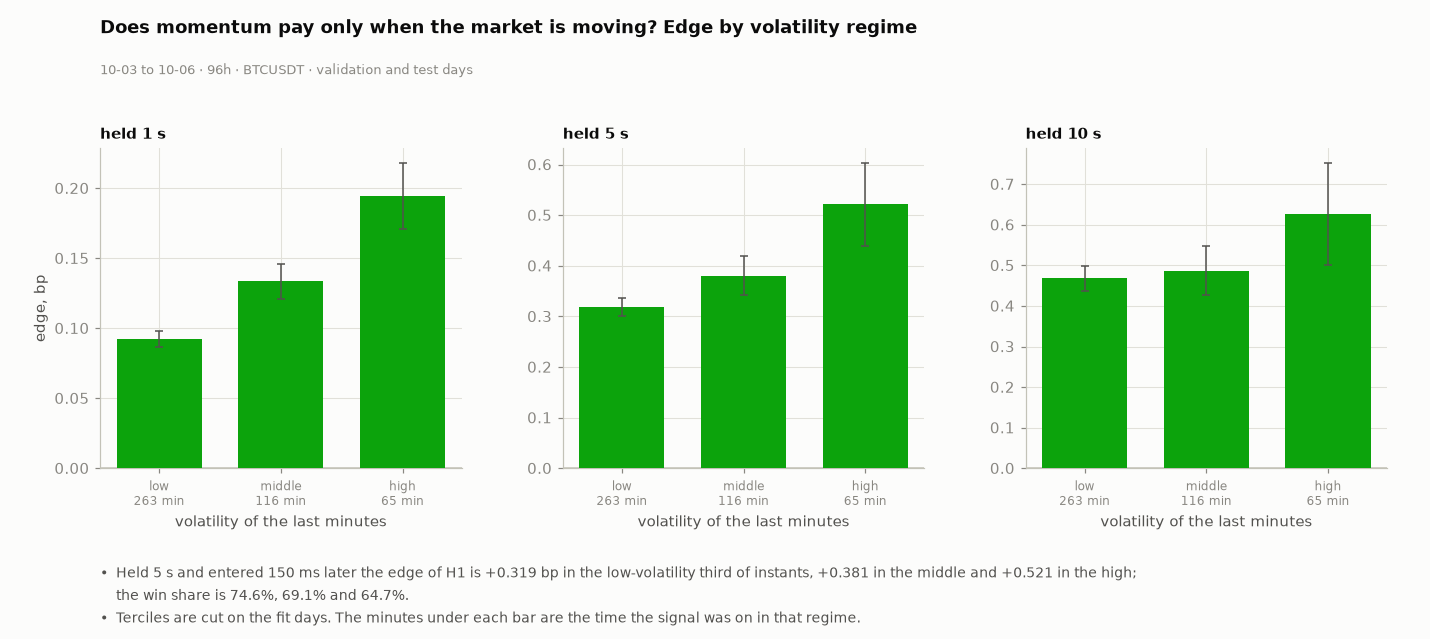

In [28]:
_x1, _m1 = M_OOS["H1"]
_sig = ST.stack(OOS, "sigma_slow").astype(np.float64)
_e = TH["vol_edges"]
VOLM = {"low": _sig < _e[0], "middle": (_sig >= _e[0]) & (_sig < _e[1]), "high": _sig >= _e[1]}
VOLT = A.by_mask(COH_ALL, _x1, {k: v & _m1 for k, v in VOLM.items()})
_v5 = VOLT[(VOLT.L_ms == LAT_BAR_MS) & (VOLT.h_s == 5.0)].set_index("group")
_bul = [f"Held 5 s and entered {LAT_BAR_MS} ms later the edge of H1 is {sgn(_v5.loc['low', 'edge_bp'], 3)} bp in the low-volatility third of instants, {sgn(_v5.loc['middle', 'edge_bp'], 3)} in the middle and {sgn(_v5.loc['high', 'edge_bp'], 3)} in the high; the win share is {pct(_v5.loc['low', 'win_share'])}, {pct(_v5.loc['middle', 'win_share'])} and {pct(_v5.loc['high', 'win_share'])}.",
        "Terciles are cut on the fit days. The minutes under each bar are the time the signal was on in that regime."]
fig = FG.by_group(VOLT, ["low", "middle", "high"], CONFIRM_H, WIN_OOS, _bul, "Does momentum pay only when the market is moving? Edge by volatility regime", "volatility of the last minutes")
figstyle.show(fig, "fig:s3-volregime", FIGURES)

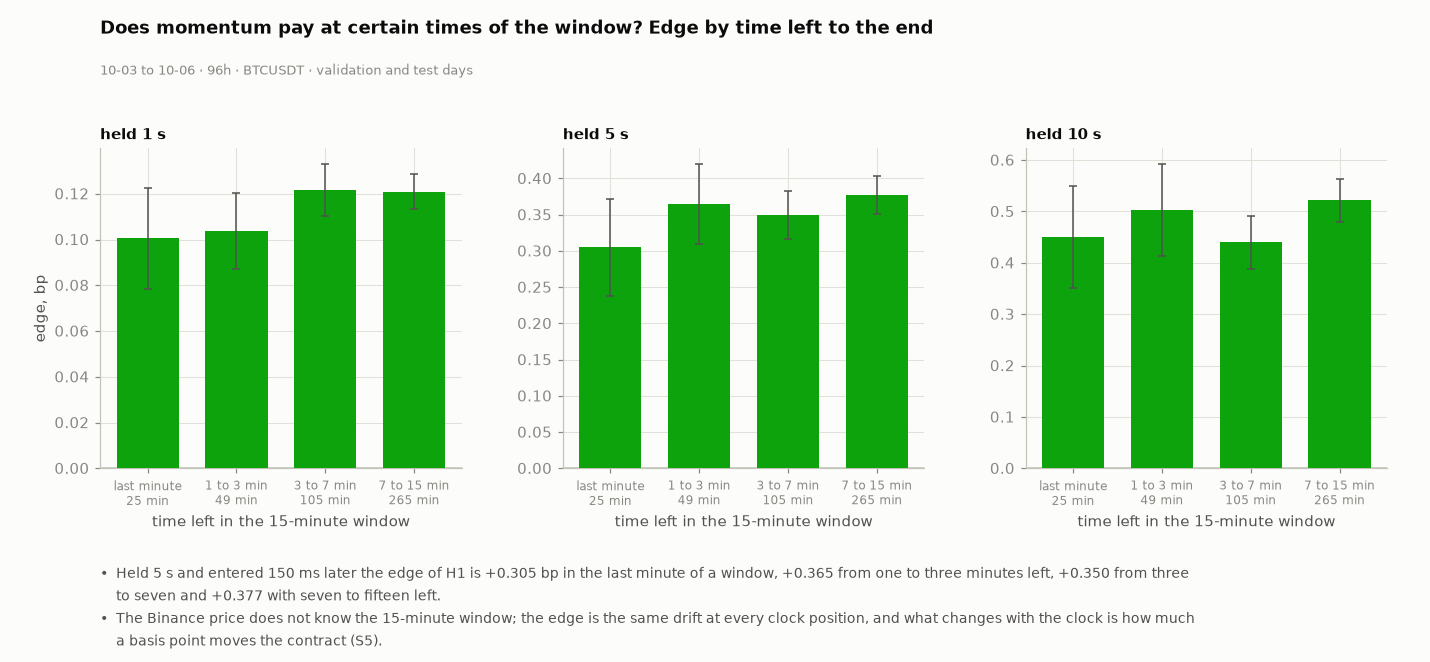

In [29]:
_left = ST.stack(OOS, "sec_left").astype(np.float64)
LEFT_BINS = [("last minute", 0, 60), ("1 to 3 min", 60, 180), ("3 to 7 min", 180, 420), ("7 to 15 min", 420, 901)]
LEFTM = {n_: (_left >= lo) & (_left < hi) for n_, lo, hi in LEFT_BINS}
LEFTT = A.by_mask(COH_ALL, _x1, {k: v & _m1 for k, v in LEFTM.items()})
_l5 = LEFTT[(LEFTT.L_ms == LAT_BAR_MS) & (LEFTT.h_s == 5.0)].set_index("group")
_bul = [f"Held 5 s and entered {LAT_BAR_MS} ms later the edge of H1 is {sgn(_l5.loc['last minute', 'edge_bp'], 3)} bp in the last minute of a window, {sgn(_l5.loc['1 to 3 min', 'edge_bp'], 3)} from one to three minutes left, {sgn(_l5.loc['3 to 7 min', 'edge_bp'], 3)} from three to seven and {sgn(_l5.loc['7 to 15 min', 'edge_bp'], 3)} with seven to fifteen left.",
        "The Binance price does not know the 15-minute window; the edge is the same drift at every clock position, and what changes with the clock is how much a basis point moves the contract (S5)."]
fig = FG.by_group(LEFTT, [n_ for n_, _, _ in LEFT_BINS], CONFIRM_H, WIN_OOS, _bul, "Does momentum pay at certain times of the window? Edge by time left to the end", "time left in the 15-minute window")
figstyle.show(fig, "fig:s3-secleft", FIGURES)

### What does one trade look like?

In [30]:
ANS2 = display(Markdown("_The answer is written here when the run reaches the test entries._"), display_id=True)

**An entry buys the token on the side of the move at 47.2 cents a share on average, with a spread of 1.8 cents, and 55.7% of the 88 test entries made money** (10-05 to 10-06 · 48h · BTC 15m · test days).

Part B. The trade is one entry per burst: an order of USD 20 is sent at once, meets the book after the taker delay, buys the token on the side of the move on the exact ladder, and is held to the outcome or sold back after 10 or 60 s. The registered grid of 24 configurations is scored on the validation days; the one chosen is read once on the test days.

**Polymarket: the registered grid on the validation days, and the one choice**

All 24 configurations on the two validation days, every one kept. The rule written before the run: the highest net PnL per entry among those with at least the minimum entries. The test days are not read before this cell has chosen.

In [31]:
SUMV = VAL_ENT.groupby("cfg").apply(lambda d: pd.Series(BT.summarize(d)), include_groups=False)
SUMV["cfg"] = SUMV.index
ELIG = SUMV[SUMV.n >= MIN_ENTRIES]
assert len(ELIG), "no configuration has the minimum entries on the validation days: the study ends here (EMPTY, not failed)"
CHOSEN_NAME = str(ELIG.per_entry.idxmax())
CHOSEN = next(c for c in GRID if c.name == CHOSEN_NAME)
_t = SUMV.sort_values("per_entry", ascending=False)
display(Markdown(f"**Validation days, all {len(SUMV)} configurations** (net PnL per entry in USD on a USD {CLIP_USD:g} clip; win = net above zero; fees in USD)\n\n| Configuration | Entries | Win | Net per entry | Before fee per entry | Fees | Avg price | Eligible |\n|---|---|---|---|---|---|---|---|\n" +
                 "\n".join(f"| {r.cfg} | {int(r.n)} | {pct(r.win)} | {r.per_entry:+.2f} | {r.gross_per_entry:+.2f} | {r.fees:.1f} | {r.px:.3f} | {'yes' if r.n >= MIN_ENTRIES else 'no'} |" for r in _t.itertuples())))
display(Markdown(f"**Chosen by the registered rule:** `{CHOSEN_NAME}` ({int(SUMV.loc[CHOSEN_NAME, 'n'])} entries, net {SUMV.loc[CHOSEN_NAME, 'per_entry']:+.2f} per entry on the validation days). It is one of {N_TRIALS} trials on two days of one regime: its validation number is the best of {len(ELIG)} eligible and is flattered by that choice."))
print("CHOSEN:", CHOSEN)

**Validation days, all 24 configurations** (net PnL per entry in USD on a USD 20 clip; win = net above zero; fees in USD)

| Configuration | Entries | Win | Net per entry | Before fee per entry | Fees | Avg price | Eligible |
|---|---|---|---|---|---|---|---|
| z1|hold|0.15-0.85|le180|L150 | 50 | 56.0% | +6.78 | +7.51 | 36.5 | 0.478 | no |
| z2|hold|0.15-0.85|le180|L150 | 49 | 55.1% | +6.50 | +7.23 | 35.8 | 0.478 | no |
| z2|scalp60|0.15-0.85|le180|L150 | 66 | 63.6% | +6.46 | +7.66 | 79.2 | 0.482 | yes |
| z1|scalp60|0.15-0.85|le180|L150 | 67 | 61.2% | +5.36 | +6.55 | 79.8 | 0.474 | yes |
| z2|scalp10|0.15-0.85|le180|L150 | 107 | 57.9% | +4.13 | +5.43 | 139.2 | 0.522 | yes |
| z2|hold|all|le180|L150 | 147 | 49.0% | +3.82 | +4.54 | 106.6 | 0.479 | yes |
| z1|scalp10|0.15-0.85|le180|L150 | 117 | 56.4% | +3.59 | +4.93 | 156.4 | 0.508 | yes |
| z2|hold|0.15-0.85|any|L150 | 189 | 66.1% | +3.18 | +3.79 | 116.6 | 0.559 | yes |
| z2|hold|all|any|L150 | 190 | 66.3% | +3.17 | +3.79 | 116.8 | 0.561 | yes |
| z1|hold|all|le180|L150 | 151 | 50.3% | +3.03 | +3.73 | 105.2 | 0.499 | yes |
| z1|hold|0.15-0.85|any|L150 | 189 | 64.6% | +2.65 | +3.27 | 117.7 | 0.555 | yes |
| z1|hold|all|any|L150 | 190 | 64.7% | +2.64 | +3.26 | 117.8 | 0.557 | yes |
| z2|scalp60|all|any|L150 | 1260 | 52.1% | +1.78 | +2.93 | 1443.2 | 0.544 | yes |
| z1|scalp60|all|any|L150 | 1363 | 50.9% | +1.52 | +2.68 | 1582.0 | 0.537 | yes |
| z2|scalp60|0.15-0.85|any|L150 | 884 | 56.8% | +1.35 | +2.60 | 1108.0 | 0.531 | yes |
| z1|scalp60|0.15-0.85|any|L150 | 945 | 55.0% | +1.10 | +2.37 | 1197.4 | 0.526 | yes |
| z2|scalp10|0.15-0.85|any|L150 | 1647 | 44.9% | +0.54 | +1.80 | 2063.9 | 0.551 | yes |
| z1|scalp10|0.15-0.85|any|L150 | 1915 | 43.6% | +0.42 | +1.69 | 2426.1 | 0.547 | yes |
| z2|scalp10|all|any|L150 | 2450 | 37.8% | +0.21 | +1.39 | 2885.9 | 0.554 | yes |
| z1|scalp10|all|any|L150 | 2892 | 36.2% | -0.15 | +1.04 | 3443.6 | 0.546 | yes |
| z2|scalp10|all|le180|L150 | 382 | 29.8% | -0.41 | +0.81 | 465.5 | 0.426 | yes |
| z1|scalp10|all|le180|L150 | 451 | 29.9% | -0.94 | +0.26 | 539.1 | 0.432 | yes |
| z2|scalp60|all|le180|L150 | 223 | 39.9% | -1.79 | -0.66 | 251.9 | 0.401 | yes |
| z1|scalp60|all|le180|L150 | 242 | 39.7% | -1.81 | -0.72 | 264.2 | 0.414 | yes |

**Chosen by the registered rule:** `z2|scalp60|0.15-0.85|le180|L150` (66 entries, net +6.46 per entry on the validation days). It is one of 24 trials on two days of one regime: its validation number is the best of 22 eligible and is flattered by that choice.

CHOSEN: Cfg(z0=2.0, exit='scalp', hold_s=60.0, lo=0.15, hi=0.85, left_max_s=180.0, lat_ms=150)


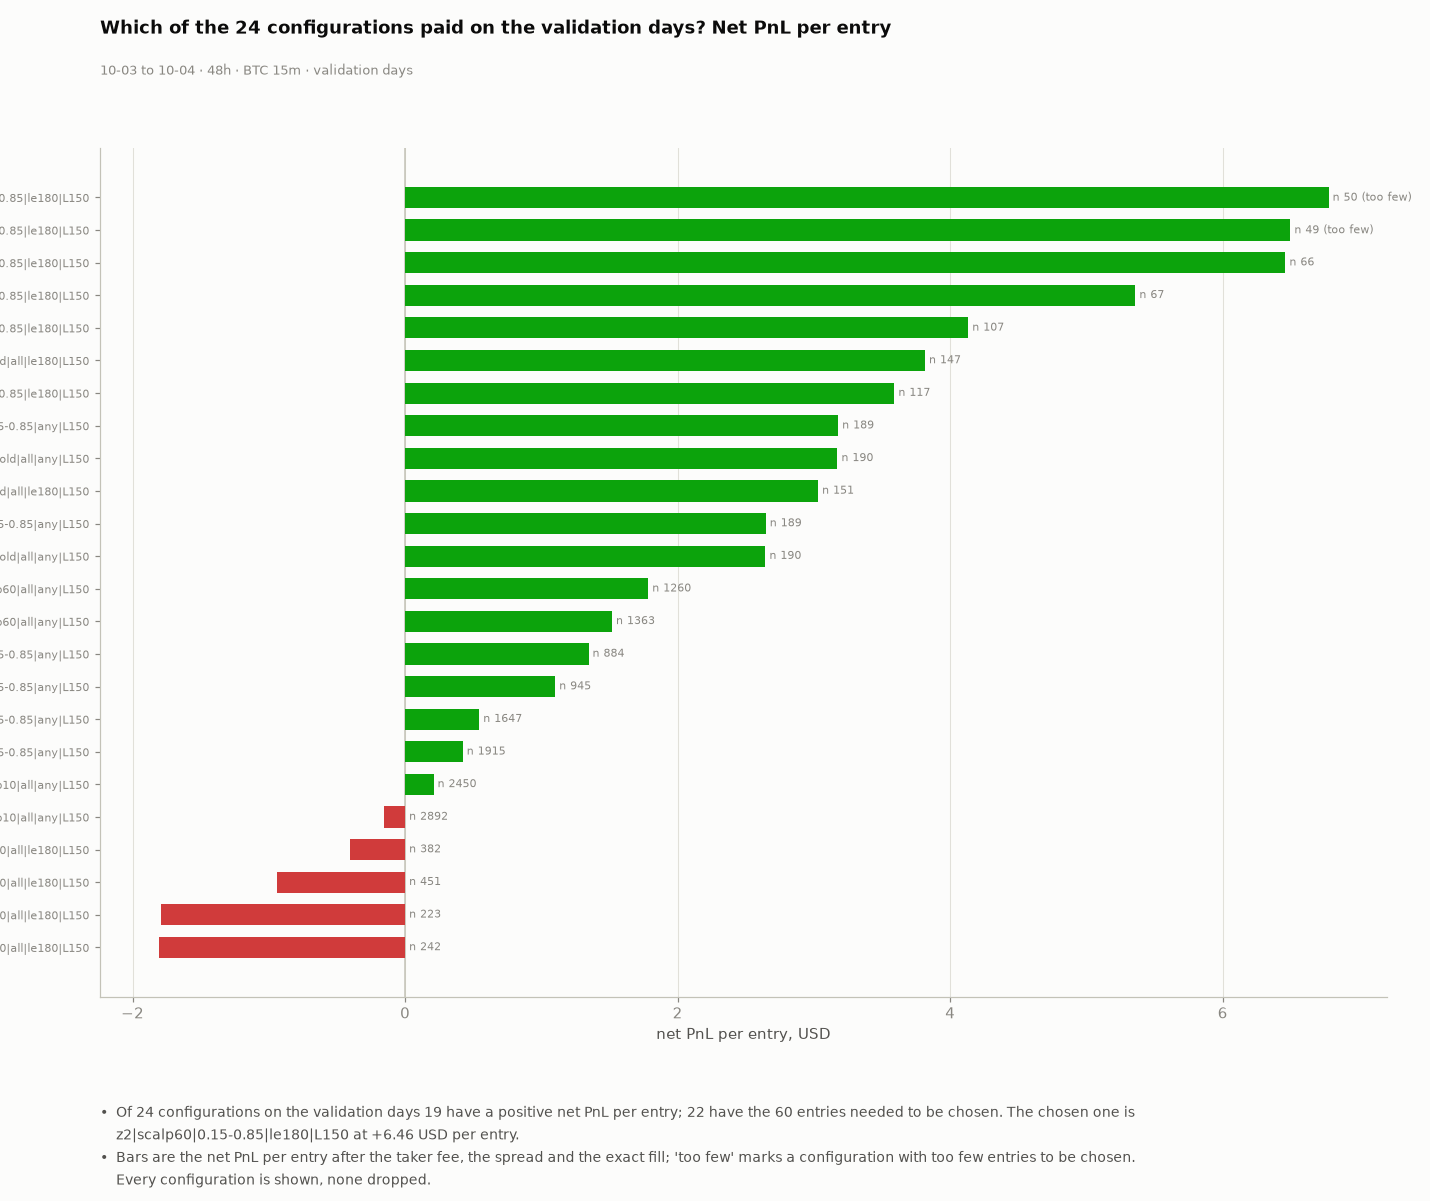

In [32]:
_d = _t.iloc[::-1]
_bul = [f"Of {N_TRIALS} configurations on the validation days {int((SUMV.per_entry > 0).sum())} have a positive net PnL per entry; {len(ELIG)} have the {MIN_ENTRIES} entries needed to be chosen. The chosen one is {CHOSEN_NAME} at {SUMV.loc[CHOSEN_NAME, 'per_entry']:+.2f} USD per entry.",
        "Bars are the net PnL per entry after the taker fee, the spread and the exact fill; 'too few' marks a configuration with too few entries to be chosen. Every configuration is shown, none dropped."]
fig, ax = FG.frame(0.3 * len(_d) + 1.4, _bul, "Which of the 24 configurations paid on the validation days? Net PnL per entry", WIN_PM_VAL)
fig.subplots_adjust(left=0.2)
a = ax[0]
y = np.arange(len(_d))
a.barh(y, _d.per_entry, color=[FG.GOOD if v >= 0 else FG.BAD for v in _d.per_entry], height=0.65, zorder=3)
a.axvline(0, color=FG.N["axis"], lw=1.0)
a.set_yticks(y); a.set_yticklabels(_d.cfg, fontsize=7.5)
for k, (_, r) in enumerate(_d.iterrows()):
    a.annotate(f" n {int(r.n)}" + ("" if r.n >= MIN_ENTRIES else " (too few)"), xy=(max(r.per_entry, 0), k), va="center", fontsize=7, color=FG.N["muted"])
a.set_xlabel("net PnL per entry, USD"); a.grid(axis="y", visible=False)
figstyle.show(fig, "fig:s3-grid", FIGURES)

**Polymarket: the test days, read once**

The chosen configuration on the two test days, with the benchmarks and planted variants that S4 reads (the same triggers with random sides, the side reversed, a planted peek, a stale signal) and the delay sweep, all built in the one pass over each test day.

In [33]:
t0 = time.time()
VARIANTS = {"fade": BR.v_fade, f"peek{PEEK_S:g}": BR.make_peek(PEEK_S), f"stale{STALE_S:g}": BR.make_stale(STALE_S)}
VARIANTS.update({f"rand{k:03d}": BR.make_random_side(SEED + 1000 * k) for k in range(N_RANDOM)})
LAT_CFGS = [dataclasses.replace(CHOSEN, lat_ms=L) for L in LATENCIES]
TEST_ENT, TEST_WIN, TEST_LAG, LAT_ENT = [], [], [], []
for d in TEST_DAYS:
    e_, w_, l_ = BR.run_day(d, [CHOSEN], variants=VARIANTS, lag=True)
    TEST_ENT.append(e_); TEST_WIN.append(w_); TEST_LAG.append(l_)
    e2, _, _ = BR.run_day(d, LAT_CFGS, lag=False)
    LAT_ENT.append(e2)
    print(f"{d}: {len(e_):,} entries (chosen, benchmarks and planted variants), {len(e2):,} entries over {len(LAT_CFGS)} delays, {time.time() - t0:.0f}s")
TEST_ENT = pd.concat(TEST_ENT, ignore_index=True); TEST_WIN = pd.concat(TEST_WIN, ignore_index=True); LAT_ENT = pd.concat(LAT_ENT, ignore_index=True)
TE = TEST_ENT[TEST_ENT.variant == "pack"].copy()
TS = BT.summarize(TE)
MEAN_, CI_LO, CI_HI = BT.cluster_ci(TE)
_won = TE.won.mean() if len(TE) else np.nan
BE = float((TE.cost + TE.fee_in).sum() / TE.shares.sum()) if len(TE) else np.nan
display(Markdown(f"**Test days, `{CHOSEN_NAME}`:** {TS['n']} entries in {TE.slug.nunique()} windows, win (net above zero) {pct(TS['win'])}, **net {sgn(TS['net'], 0)} USD, {sgn(TS['per_entry'], 2)} per entry (95% by window {sgn(CI_LO, 2)} to {sgn(CI_HI, 2)})**; before the fee {sgn(TS['gross'], 0)} USD, fees {usd(TS['fees'])}, average price {TS['px']:.3f}, average spread {TS['spread'] * 100:.1f} cents, {TS['partial']} fills short of the clip."))
display(HTML(TE.groupby("day").apply(lambda d: pd.Series(BT.summarize(d)), include_groups=False)[["n", "win", "per_entry", "gross_per_entry", "net", "fees"]].round(3).to_html(border=0)))

2026-10-05: 8,470 entries (chosen, benchmarks and planted variants), 306 entries over 7 delays, 64s


2026-10-06: 9,405 entries (chosen, benchmarks and planted variants), 315 entries over 7 delays, 125s


**Test days, `z2|scalp60|0.15-0.85|le180|L150`:** 88 entries in 67 windows, win (net above zero) 55.7%, **net +80 USD, +0.91 per entry (95% by window -2.24 to +4.05)**; before the fee +173 USD, fees USD 93, average price 0.472, average spread 1.8 cents, 0 fills short of the clip.

,n,win,per_entry,gross_per_entry,net,fees
day,,,,,,
2026-10-05,42.0,0.548,-0.022,1.074,-0.923,46.044
2026-10-06,46.0,0.565,1.763,2.787,81.088,47.102


In [34]:
# ---- one real entry: the middle entry of the test days by net, from the signal to the settlement ----
_te = TE.sort_values("net", kind="stable").reset_index(drop=True)
_r = _te.iloc[len(_te) // 2]
_tok = "Up" if int(_r["side"]) > 0 else "Down"
_t_sig = dt.datetime.fromtimestamp(int(_r["t_ms"]) / 1000, dt.timezone.utc)
_how = ("held to the outcome: the token paid " + ("1 USD a share" if bool(_r["won"]) else "nothing")) if _r["exit"] == "expiry" else f"sold back {CHOSEN.hold_s:g} s after the fill for USD {_r['proceeds']:.2f}"
display(Markdown(f"**The middle entry of the {TS['n']} on the test days, by net** ({WIN_PM_TEST})\n\n| Step | What happened |\n|---|---|\n"
                 f"| The signal | at {_t_sig:%Y-%m-%d %H:%M:%S} UTC, {_r['left_s']:.0f} s before the window ended, Binance BTC moved {float(_r['z']):.1f} volatilities in a second |\n"
                 f"| The order | USD {CLIP_USD:g} sent at once, meeting the book {CHOSEN.lat_ms} ms later: the {_tok} token, best ask {_r['ask']:.3f}, best bid {_r['bid']:.3f} |\n"
                 f"| The fill | {_r['shares']:.0f} shares at {_r['vwap']:.3f} on average, USD {_r['cost']:.2f}, fee USD {_r['fee_in']:.2f} |\n"
                 f"| The exit | {_how} |\n"
                 f"| The result | net {sgn(_r['net'], 2)} USD |"))
ANS2.update(Markdown(f"**An entry buys the token on the side of the move at {TS['px'] * 100:.1f} cents a share on average, with a spread of {TS['spread'] * 100:.1f} cents, and {pct(TS['win'])} of the {TS['n']} test entries made money** ({WIN_PM_TEST})."))

**The middle entry of the 88 on the test days, by net** (10-05 to 10-06 · 48h · BTC 15m · test days)

| Step | What happened |
|---|---|
| The signal | at 2026-10-06 13:27:30 UTC, 150 s before the window ended, Binance BTC moved -2.0 volatilities in a second |
| The order | USD 20 sent at once, meeting the book 150 ms later: the Down token, best ask 0.840, best bid 0.830 |
| The fill | 24 shares at 0.848 on average, USD 20.00, fee USD 0.21 |
| The exit | sold back 60 s after the fill for USD 23.35 |
| The result | net +3.12 USD |

### Does the edge survive the time it takes to fill?

In [35]:
ANS3 = display(Markdown("_The answer is written here when the run reaches the delay table._"), display_id=True)

**Yes: on Binance the edge keeps 96% of its no-delay size at 150 ms, and on Polymarket the chosen trade nets +4.48 USD an entry with no delay, +0.91 at 150 ms and -2.17 at 400 ms** (10-05 to 10-06 · 48h · BTC 15m · test days).

**Latency survival: the edge when the trade comes later than the signal**

The strongest simple signal named in S3, on the test days, seen at the instant and traded after 0, 50, 100, 150, 250, 500 and 1000 ms. The 150 ms line is the bar: Polymarket makes a taker wait that long.

**H1 momentum, test days: edge in bp (cluster t) by delay and hold**

| Delay | 1 s | 5 s | 10 s | 30 s | 60 s |
|---|---|---|---|---|---|
| 0 ms | +0.139 (+41) | +0.426 (+36) | +0.563 (+29) | +0.678 (+19) | +0.697 (+13) |
| 50 ms | +0.139 (+39) | +0.421 (+36) | +0.558 (+29) | +0.672 (+18) | +0.691 (+13) |
| 100 ms | +0.137 (+38) | +0.415 (+35) | +0.551 (+29) | +0.664 (+18) | +0.682 (+13) |
| 150 ms | +0.135 (+37) | +0.409 (+34) | +0.544 (+28) | +0.656 (+18) | +0.674 (+13) |
| 250 ms | +0.130 (+35) | +0.396 (+33) | +0.529 (+27) | +0.642 (+18) | +0.659 (+12) |
| 500 ms | +0.118 (+31) | +0.369 (+31) | +0.498 (+26) | +0.607 (+17) | +0.622 (+12) |
| 1000 ms | +0.099 (+26) | +0.321 (+27) | +0.442 (+23) | +0.545 (+15) | +0.556 (+11) |

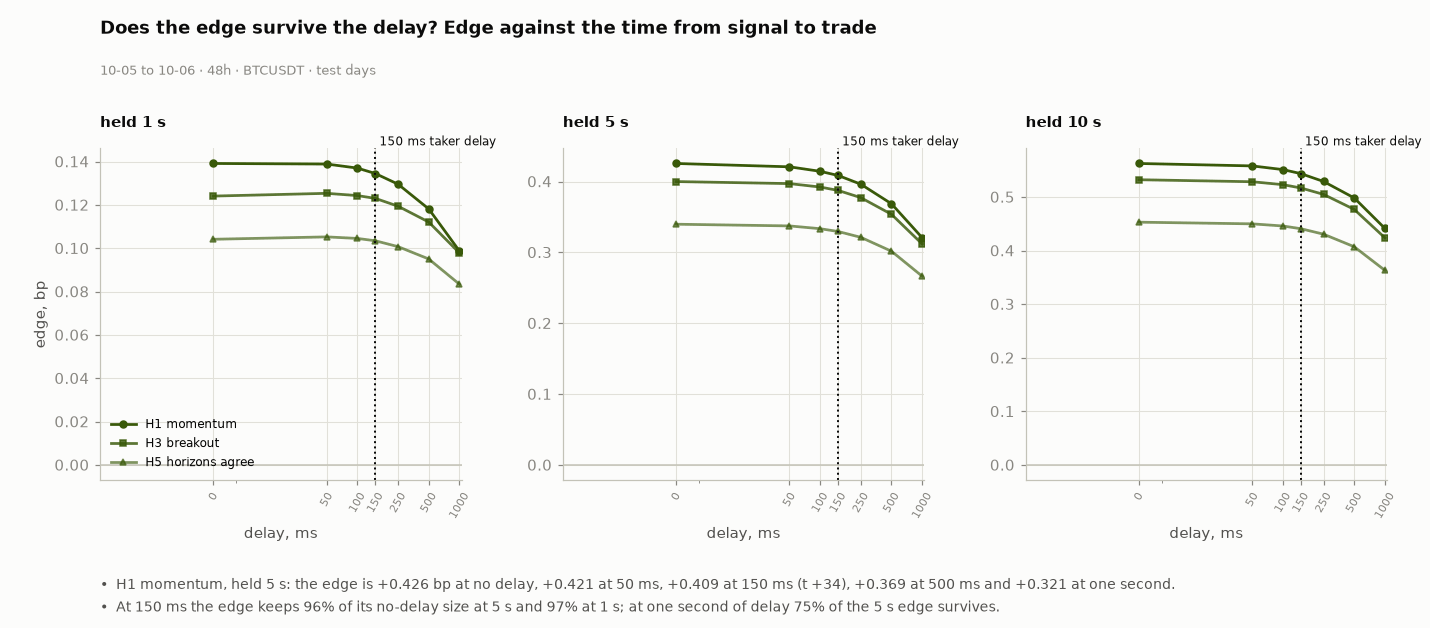

In [36]:
_MT = P.masks(TEST, TH)
X_PACK = {h_: _MT[h_] for h_ in ("H1", "H2", "H3", "H5")}
COH_TEST = ST.Cohort(TEST, ST.all_targets(), CLIP)
LAT_TEST = {nm: ST.lat_table(COH_TEST, *X_PACK[h_]) for nm, h_ in (("H1 momentum", "H1"), ("H3 breakout", "H3"), ("H5 horizons agree", "H5"))}
PACK_NAME = {"H1": "H1 momentum", "H2": "H2 acceleration", "H3": "H3 breakout", "H5": "H5 horizons agree"}[PACK]
if PACK_NAME not in LAT_TEST:
    LAT_TEST[PACK_NAME] = ST.lat_table(COH_TEST, *X_PACK[PACK])
LT = LAT_TEST[PACK_NAME]
def lt(L, h):
    return LT[(LT.L_ms == L) & (LT.h_s == h)].iloc[0]
_rows = []
for L in LF.LATENCIES_MS:
    _rows.append("| " + f"{L} ms | " + " | ".join(f"{lt(L, h).edge_bp:+.3f} ({lt(L, h).t:+.0f})" for h in (1.0, 5.0, 10.0, 30.0, 60.0)) + " |")
display(Markdown(f"**{PACK_NAME}, test days: edge in bp (cluster t) by delay and hold**\n\n| Delay | 1 s | 5 s | 10 s | 30 s | 60 s |\n|---|---|---|---|---|---|\n" + "\n".join(_rows)))
_bul = [f"{PACK_NAME}, held 5 s: the edge is {sgn(lt(0, 5.0).edge_bp, 3)} bp at no delay, {sgn(lt(50, 5.0).edge_bp, 3)} at 50 ms, {sgn(lt(150, 5.0).edge_bp, 3)} at 150 ms (t {lt(150, 5.0).t:+.0f}), {sgn(lt(500, 5.0).edge_bp, 3)} at 500 ms and {sgn(lt(1000, 5.0).edge_bp, 3)} at one second.",
        f"At 150 ms the edge keeps {pct(lt(150, 5.0).edge_bp / lt(0, 5.0).edge_bp, 0)} of its no-delay size at 5 s and {pct(lt(150, 1.0).edge_bp / lt(0, 1.0).edge_bp, 0)} at 1 s; at one second of delay {pct(lt(1000, 5.0).edge_bp / lt(0, 5.0).edge_bp, 0)} of the 5 s edge survives."]
fig = FG.latency_curves(LAT_TEST, CONFIRM_H, WIN_TEST, _bul, bar=LAT_BAR_MS)
figstyle.show(fig, "fig:s3-latency", FIGURES)

In [37]:
_ok_t = all(lt(LAT_BAR_MS, h).t >= T_BAR for h in CONFIRM_H)
_keep = {h: lt(LAT_BAR_MS, h).edge_bp / lt(0, h).edge_bp for h in CONFIRM_H}
_ok_k = all(v >= 0.5 for v in _keep.values())
GATES.append({"id": "G12", "section": "S4", "label": "Survives 150 ms", "name": f"{PACK_NAME}: at the 150 ms delay the test-day edge has t at or above the bar and keeps half its no-delay size, at 1, 5 and 10 s",
              "reading": f"t {' / '.join(f'{lt(LAT_BAR_MS, h).t:+.0f}' for h in CONFIRM_H)}; share of the no-delay edge kept {' / '.join(pct(_keep[h], 0) for h in CONFIRM_H)}",
              "verdict": "PASS" if (_ok_t and _ok_k) else "FAIL", "would_change": "a t under the bar at 150 ms, or less than half the no-delay edge kept, at any of the three holds"})
print("survives 150 ms:", _ok_t, _ok_k, {h: round(v, 3) for h, v in _keep.items()})

survives 150 ms: True True {1.0: np.float64(0.967), 5.0: np.float64(0.96), 10.0: np.float64(0.966)}


**Polymarket: the delay: the same rule from 0 to 1000 ms, and at twice the fee**

Everything in S3 is at 150 ms. Here the same orders meet the book at other delays, with the exit shifted the same way.

**The chosen configuration at each delay, test days**

| Delay | Entries | Win | Net per entry | Before fee per entry | Average price |
|---|---|---|---|---|---|
| 0 ms | 85 | 64.7% | +4.48 | +5.60 | 0.461 |
| 50 ms | 84 | 63.1% | +3.99 | +5.10 | 0.465 |
| 100 ms | 88 | 58.0% | +2.41 | +3.50 | 0.459 |
| 150 ms | 88 | 55.7% | +0.91 | +1.97 | 0.472 |
| 250 ms | 90 | 50.0% | -1.78 | -0.70 | 0.461 |
| 400 ms | 92 | 47.8% | -2.17 | -1.07 | 0.443 |
| 1000 ms | 94 | 48.9% | -1.97 | -0.88 | 0.442 |

**At each multiple of the fee, test days, 150 ms:** 0x the fee +1.97 USD per entry; 1x the fee +0.91 USD per entry; 2x the fee -0.15 USD per entry

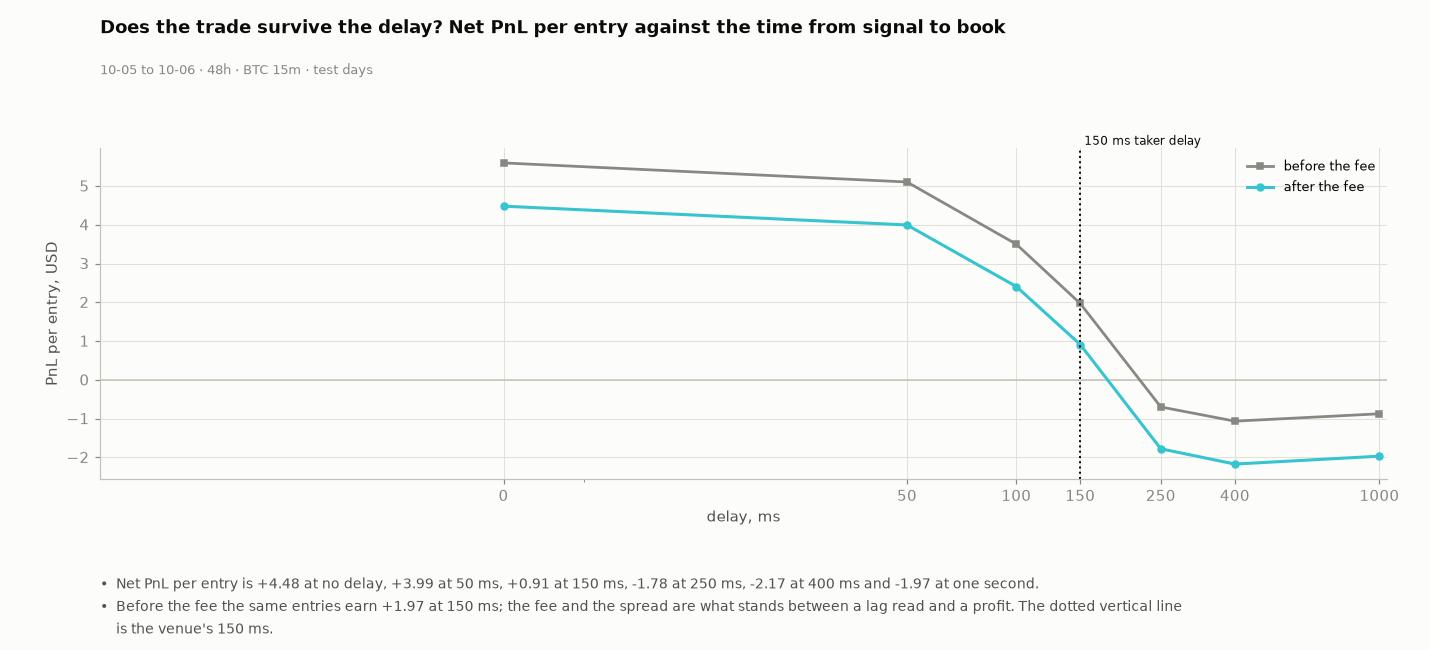

In [38]:
LATS = LAT_ENT.groupby("cfg").apply(lambda d: pd.Series(BT.summarize(d)), include_groups=False)
LATS["L"] = [int(c.split("|L")[-1]) for c in LATS.index]
LATS = LATS.sort_values("L")
display(Markdown("**The chosen configuration at each delay, test days**\n\n| Delay | Entries | Win | Net per entry | Before fee per entry | Average price |\n|---|---|---|---|---|---|\n" +
                 "\n".join(f"| {int(r.L)} ms | {int(r.n)} | {pct(r.win)} | {r.per_entry:+.2f} | {r.gross_per_entry:+.2f} | {r.px:.3f} |" for r in LATS.itertuples())))
_fee = [(k_, (TS["gross"] - k_ * TS["fees"]) / TS["n"]) for k_ in (0.0, 1.0, 2.0)]
display(Markdown("**At each multiple of the fee, test days, 150 ms:** " + "; ".join(f"{k_:g}x the fee {v_:+.2f} USD per entry" for k_, v_ in _fee)))
N_TESTS["delay sweep, Polymarket test days (delays)"] = len(LATENCIES)
_l = LATS.set_index("L")
_bul = [f"Net PnL per entry is {_l.loc[0, 'per_entry']:+.2f} at no delay, {_l.loc[50, 'per_entry']:+.2f} at 50 ms, {_l.loc[150, 'per_entry']:+.2f} at 150 ms, {_l.loc[250, 'per_entry']:+.2f} at 250 ms, {_l.loc[400, 'per_entry']:+.2f} at 400 ms and {_l.loc[1000, 'per_entry']:+.2f} at one second.",
        f"Before the fee the same entries earn {_l.loc[150, 'gross_per_entry']:+.2f} at 150 ms; the fee and the spread are what stands between a lag read and a profit. The dotted vertical line is the venue's 150 ms."]
fig, ax = FG.frame(3.8, _bul, "Does the trade survive the delay? Net PnL per entry against the time from signal to book", WIN_PM_TEST)
a = ax[0]
a.plot(_l.index, _l.gross_per_entry, color=FG.N["muted"], marker="s", ms=4.5, lw=1.8, label="before the fee")
a.plot(_l.index, _l.per_entry, color=FG.PM, marker="o", ms=4.5, lw=2.0, label="after the fee")
a.axvline(LAT_MS, color=FG.N["ink"], ls=":", lw=1.3)
a.annotate(f" {LAT_MS} ms taker delay", xy=(LAT_MS, 1.0), xycoords=("data", "axes fraction"), va="bottom", fontsize=8, color=FG.N["ink"])
FG.zero(a)
a.set_xscale("symlog", linthresh=50); a.set_xticks(list(LATENCIES)); a.set_xticklabels([str(v) for v in LATENCIES])
a.set_xlabel("delay, ms"); a.set_ylabel("PnL per entry, USD"); a.legend(loc="upper right", fontsize=8.5)
figstyle.show(fig, "fig:s3-pm-latency", FIGURES)
_ok150 = _l.loc[150, "per_entry"] > 0 and _l.loc[150, "per_entry"] >= _l.loc[400, "per_entry"]
GATES.append({"id": "G20", "section": "S4", "label": "Pays at 150 ms", "name": "net PnL per entry at the 150 ms delay is above zero and not below what the same rule earns at 400 ms",
              "reading": f"{_l.loc[150, 'per_entry']:+.2f} at 150 ms, {_l.loc[400, 'per_entry']:+.2f} at 400 ms, {_l.loc[0, 'per_entry']:+.2f} at no delay", "verdict": "PASS" if _ok150 else "FAIL", "would_change": "a net at 150 ms at or below zero"})

In [39]:
_conf1 = [h_ for h_, v_ in DEC.items() if v_ == "CONFIRMED"]
ANS1.update(Markdown(f"**{'Yes' if _conf1 else 'No'}.** After a one-second move of at least one volatility the Binance price goes on the same way: {PACK_NAME} earns {sgn(lt(LAT_BAR_MS, 5.0).edge_bp, 3)} bp over the next 5 s at the {LAT_BAR_MS} ms delay (t {lt(LAT_BAR_MS, 5.0).t:+.0f}, test days {WIN_TEST}), "
                     f"against {sgn(lt(0, 5.0).edge_bp, 3)} with no delay; {len(_conf1)} of the {len(DEC)} registered hypotheses are confirmed on the validation days and again on the test days."))
_keep5 = lt(LAT_BAR_MS, 5.0).edge_bp / lt(0, 5.0).edge_bp
ANS3.update(Markdown(f"**{'Yes' if _ok150 else 'No'}: on Binance the edge keeps {pct(_keep5, 0)} of its no-delay size at {LAT_BAR_MS} ms, and on Polymarket the chosen trade nets {sgn(_l.loc[0, 'per_entry'], 2)} USD an entry with no delay, {sgn(_l.loc[150, 'per_entry'], 2)} at 150 ms and {sgn(_l.loc[400, 'per_entry'], 2)} at 400 ms** ({WIN_PM_TEST})."))

### How much money do we make?

In [40]:
ANS4 = display(Markdown("_The answer is written here when the run reaches the test days._"), display_id=True)

**We make 80 USD** on 88 entries of USD 20 (10-05 to 10-06 · 48h · BTC 15m · test days): +0.91 USD each, 95% by window -2.24 to +4.05, which includes zero, so it cannot yet be told from luck. The deepest drawdown is USD 102 on the USD 1,000 book.

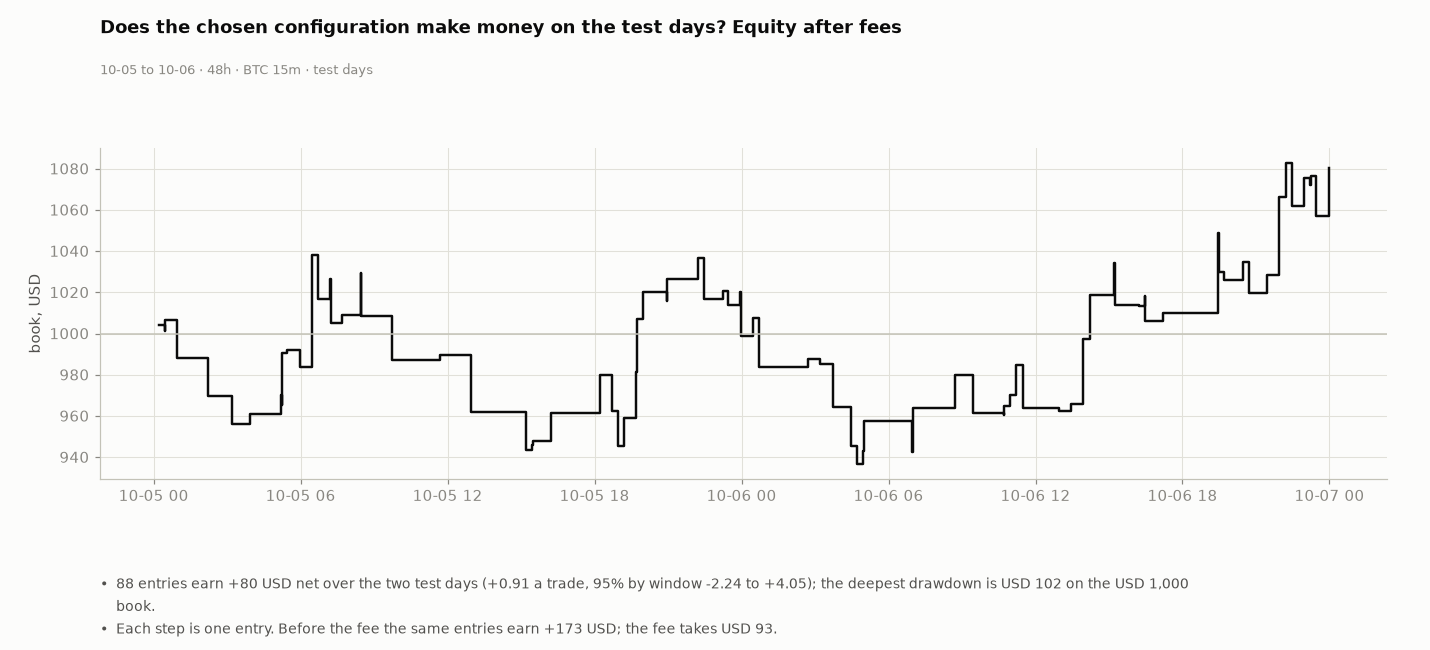

In [41]:
# ---- the equity curve of the chosen configuration on the test days (cumulative net PnL, USD, on the USD 1,000 book) ----
_e = TE.sort_values("t_ms")
_t = [dt.datetime.fromtimestamp(x / 1000, dt.timezone.utc) for x in _e.t_ms]
_eq = BOOK_USD + _e.net.cumsum().to_numpy()
_dd = float((np.maximum.accumulate(_eq) - _eq).max()) if len(_eq) else 0.0
_bul = [f"{TS['n']} entries earn {sgn(TS['net'], 0)} USD net over the two test days ({sgn(TS['per_entry'], 2)} a trade, 95% by window {sgn(CI_LO, 2)} to {sgn(CI_HI, 2)}); the deepest drawdown is {usd(_dd)} on the USD {BOOK_USD:,.0f} book.",
        f"Each step is one entry. Before the fee the same entries earn {sgn(TS['gross'], 0)} USD; the fee takes {usd(TS['fees'])}."]
fig, ax = FG.frame(3.8, _bul, "Does the chosen configuration make money on the test days? Equity after fees", WIN_PM_TEST)
a = ax[0]
if len(_eq):
    a.step(_t, _eq, where="post", color=FG.N["ink"], lw=1.6)
a.axhline(BOOK_USD, color=FG.N["axis"], lw=1.0)
a.set_ylabel("book, USD")
figstyle.show(fig, "fig:s3-equity", FIGURES)
GATES.append({"id": "G11", "section": "S3", "label": "Net per entry above 0", "name": f"{CHOSEN_NAME}: net PnL per entry on the test days above zero, window-cluster 95% interval above zero",
              "reading": f"{sgn(TS['per_entry'], 2)} USD per entry on {TS['n']} entries, 95% {sgn(CI_LO, 2)} to {sgn(CI_HI, 2)}", "verdict": "PASS" if (TS["n"] > 0 and CI_LO > 0) else "FAIL",
              "would_change": "an interval that includes zero"})

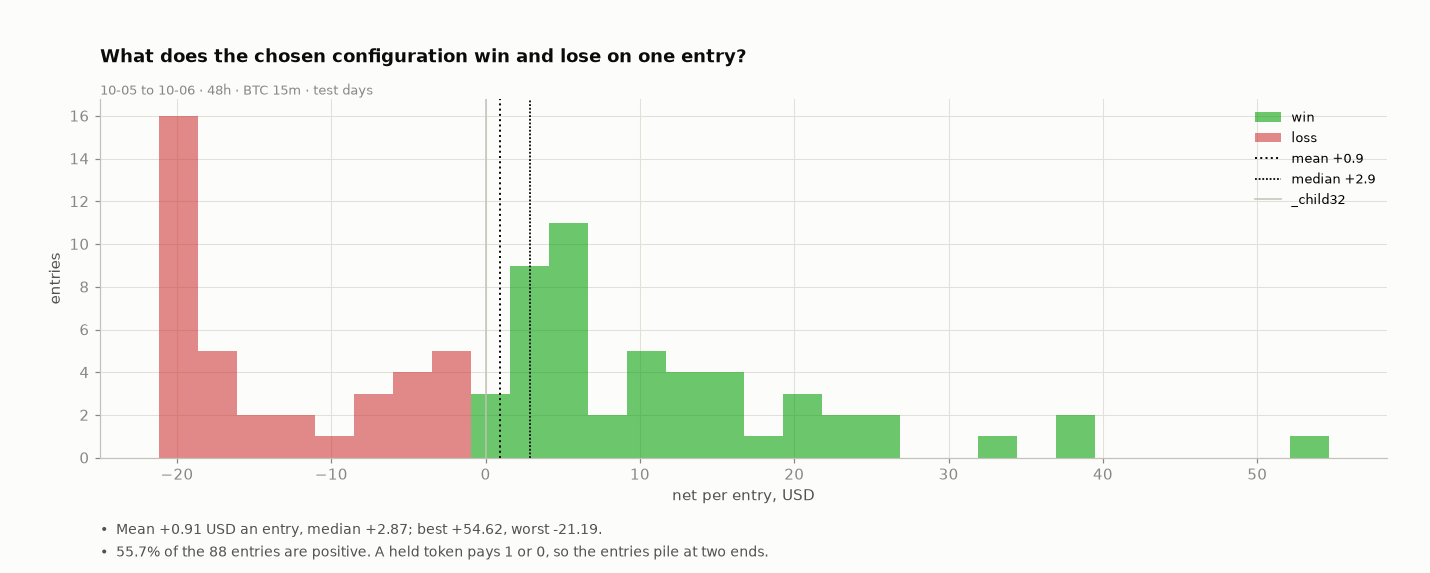

In [42]:
# ---- each entry in time order: the win and loss spread, the rolling mean net and the rolling win rate (the chart bank's recipes) ----
import mom15_figs as MF
_tt = TE.sort_values("t_ms", kind="stable")
_net_t = _tt.net.to_numpy(float)
_roll = max(5, min(30, len(_net_t) // 6))
_cs = np.concatenate([[0], np.cumsum(_net_t)])
_rm = (_cs[_roll:] - _cs[:-_roll]) / _roll
def _run(v):
    best = cur = 0
    for x_ in v:
        cur = cur + 1 if x_ else 0
        best = max(best, cur)
    return best
_hours = 24 * len(TEST_DAYS)
_bul = [f"Mean {sgn(float(_net_t.mean()), 2)} USD an entry, median {sgn(float(np.median(_net_t)), 2)}; best {sgn(float(_net_t.max()), 2)}, worst {sgn(float(_net_t.min()), 2)}.",
        f"{pct(float((_net_t > 0).mean()))} of the {len(_net_t)} entries are positive. A held token pays 1 or 0, so the entries pile at two ends."]
figstyle.show(MF.win_loss_fig(_net_t, WIN_PM_TEST, _bul, "What does the chosen configuration win and lose on one entry?"), "fig:s3-pm-trades", FIGURES)

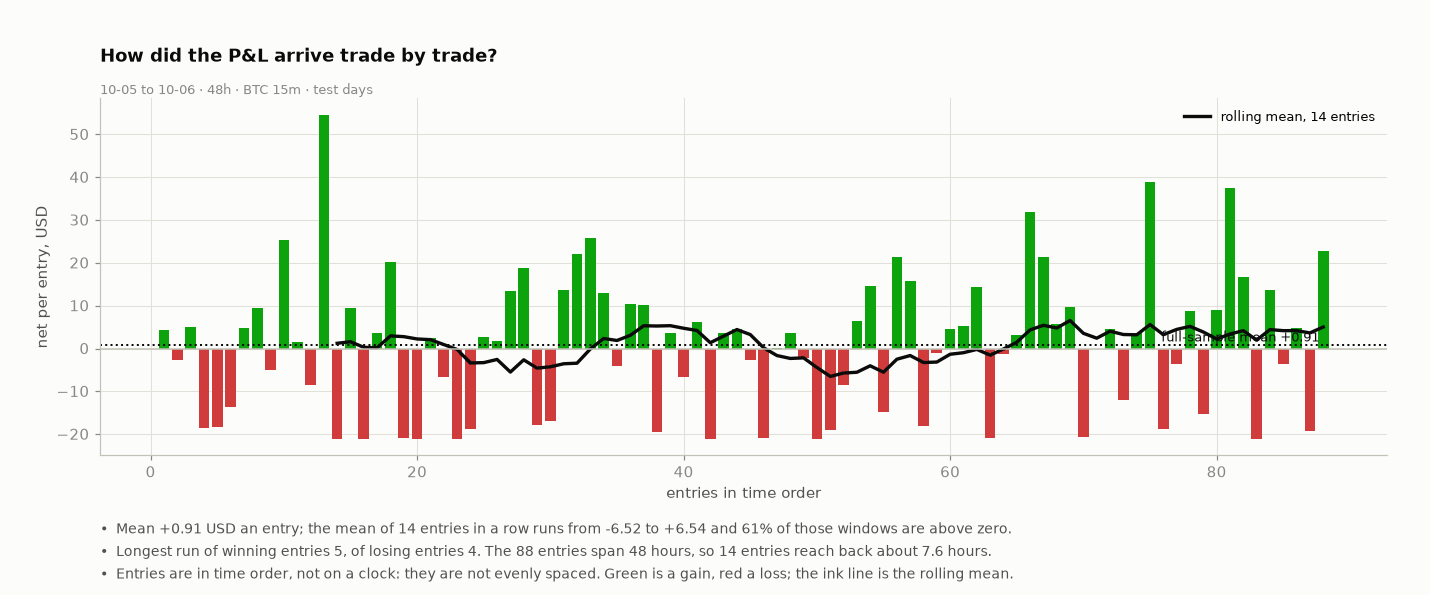

In [43]:
_bul = [f"Mean {sgn(float(_net_t.mean()), 2)} USD an entry; the mean of {_roll} entries in a row runs from {sgn(float(_rm.min()), 2)} to {sgn(float(_rm.max()), 2)} and {pct(float((_rm > 0).mean()), 0)} of those windows are above zero.",
        f"Longest run of winning entries {_run(_net_t > 0)}, of losing entries {_run(_net_t <= 0)}. The {len(_net_t)} entries span {_hours} hours, so {_roll} entries reach back about {_hours * _roll / len(_net_t):.1f} hours.",
        "Entries are in time order, not on a clock: they are not evenly spaced. Green is a gain, red a loss; the ink line is the rolling mean."]
figstyle.show(MF.per_trade_fig(_net_t, _roll, float(_net_t.mean()), WIN_PM_TEST, _bul), "fig:s3-pm-pertrade", FIGURES)

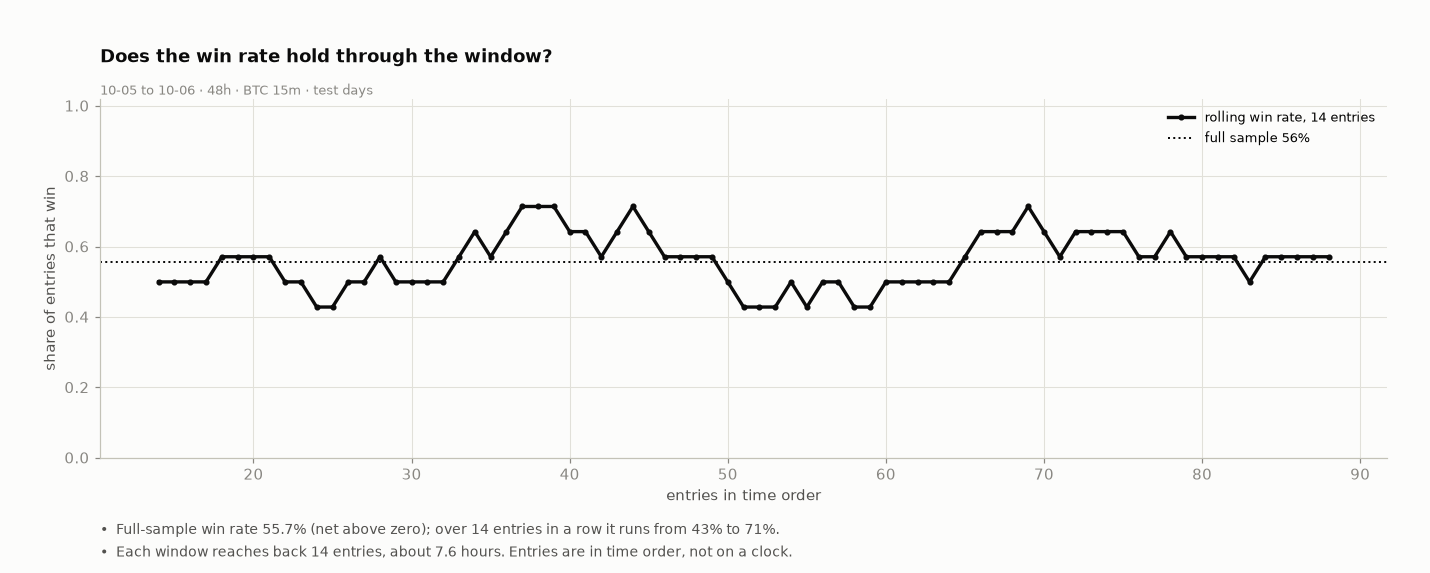

In [44]:
_won_t = (_net_t > 0).astype(float)
_cw = np.concatenate([[0], np.cumsum(_won_t)])
_rw = (_cw[_roll:] - _cw[:-_roll]) / _roll
_bul = [f"Full-sample win rate {pct(float(_won_t.mean()))} (net above zero); over {_roll} entries in a row it runs from {pct(float(_rw.min()), 0)} to {pct(float(_rw.max()), 0)}.",
        f"Each window reaches back {_roll} entries, about {_hours * _roll / len(_net_t):.1f} hours. Entries are in time order, not on a clock."]
figstyle.show(MF.rolling_win_fig(_won_t, _roll, float(_won_t.mean()), WIN_PM_TEST, _bul), "fig:s3-pm-rollwin", FIGURES)
ANS4.update(Markdown(f"**{'We make' if TS['net'] > 0 else 'We lose'} {abs(TS['net']):,.0f} USD** on {TS['n']} entries of USD {CLIP_USD:g} ({WIN_PM_TEST}): {sgn(TS['per_entry'], 2)} USD each, 95% by window {sgn(CI_LO, 2)} to {sgn(CI_HI, 2)}"
                     + (", which includes zero, so it cannot yet be told from luck" if CI_LO <= 0 <= CI_HI else "") + f". The deepest drawdown is {usd(_dd)} on the USD {BOOK_USD:,.0f} book."))

### Which windows did we enter?

In [45]:
ANS5 = display(Markdown("_The answer is written here when the run reaches the test days._"), display_id=True)

**We entered 67 of 192 windows with a book (34.9%); 37 made money and 30 lost it** (10-05 to 10-06 · 48h · BTC 15m · test days).

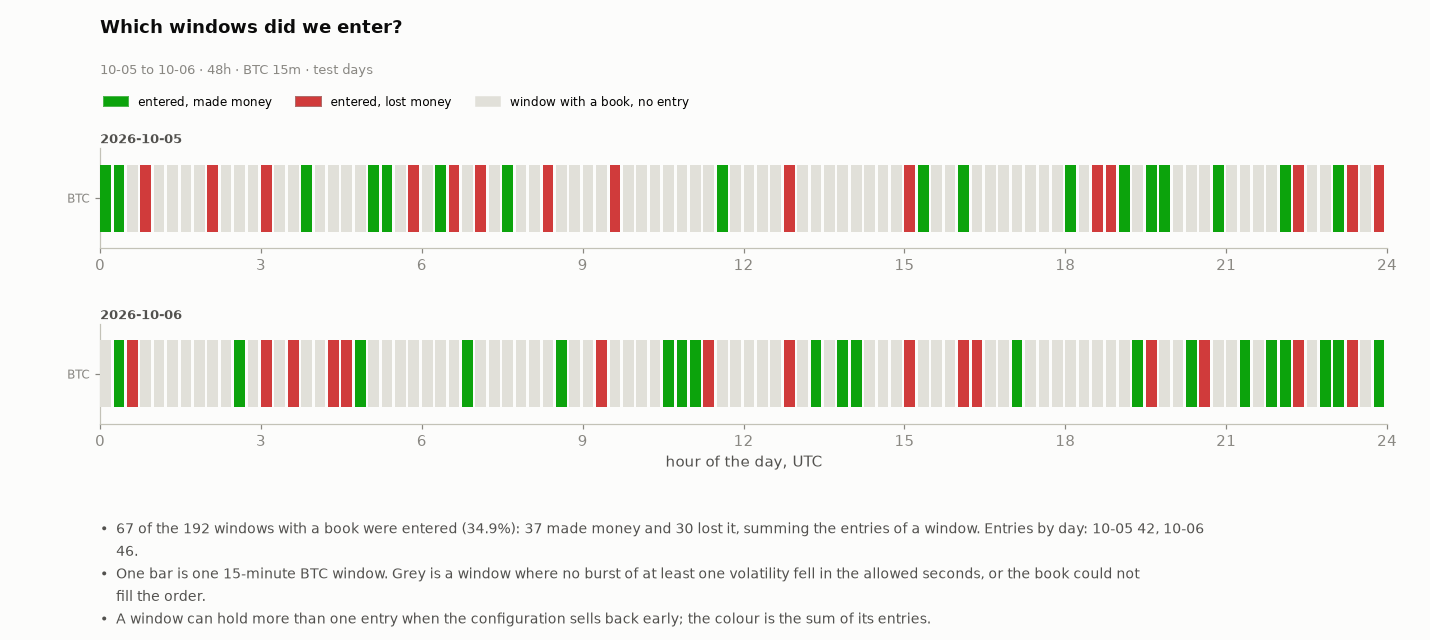

In [46]:
_wk = TEST_WIN[TEST_WIN.status == "ok"].reset_index(drop=True)
_start = np.array([int(s_.rsplit("-", 1)[1]) * 1000 for s_ in _wk.slug], np.int64)
_net_w = TE.groupby("slug").net.sum()
_status = [0 if s_ not in _net_w.index else (1 if _net_w[s_] > 0 else -1) for s_ in _wk.slug]
_dix = np.array([list(TEST_DAYS).index(d_) for d_ in _wk.day])
_n_in, _n_win = int(sum(1 for v_ in _status if v_ != 0)), len(_wk)
_bul = [f"{_n_in} of the {_n_win} windows with a book were entered ({pct(_n_in / _n_win)}): {int(sum(1 for v_ in _status if v_ > 0))} made money and {int(sum(1 for v_ in _status if v_ < 0))} lost it, summing the entries of a window. Entries by day: " + ", ".join(f"{d_[5:]} {int((TE.day == d_).sum())}" for d_ in TEST_DAYS) + ".",
        "One bar is one 15-minute BTC window. Grey is a window where no burst of at least one volatility fell in the allowed seconds, or the book could not fill the order.",
        "A window can hold more than one entry when the configuration sells back early; the colour is the sum of its entries."]
figstyle.show(MF.windows_strip(list(TEST_DAYS), (_start % 86_400_000) / 3_600_000.0, _dix, np.zeros(len(_wk), int), ["BTC"], _status, WIN_PM_TEST, _bul), "fig:s3-windows", FIGURES)
ANS5.update(Markdown(f"**We entered {_n_in} of {_n_win} windows with a book ({pct(_n_in / _n_win)}); {int(sum(1 for v_ in _status if v_ > 0))} made money and {int(sum(1 for v_ in _status if v_ < 0))} lost it** ({WIN_PM_TEST})."))

**Gate to S4.** Part A: at least one pre-registered hypothesis holds on the validation days and again on the test days (G5 to G10); the strongest simple signal for the rest of the study is the one named above. If none had held the study would stop here with NO SIGNAL. Part B: the chosen configuration's net PnL per entry on the test days is read in S3 (G11); a fail does not stop the notebook, it prints the rung as information only (S6).

## S4 · Robustness

| question | gate to S5 |
|---|---|
| Part A: is it real: does it survive the delay, hold on every day, beat the models and a placebo, add anything to the 15-minute question beyond where the window stands, and appear in the other coins? | the strongest simple signal keeps at least half its edge at 150 ms with a t above the bar on the test days, is positive on every day, beats a placebo, and no planted fault goes unseen |
| Part B: is it real: does the chosen configuration beat the same triggers with random sides and with the side reversed, is a planted peek flagged and a stale signal worse, does it pay at the 150 ms delay and not only without one, and what does twice the fee do? | it beats the placebo draws and the reversed side, a planted peek pays more and a stale signal less, and it pays above zero at 150 ms and no less than at 400 ms |

**Day by day: all seven days**

The edge at a 5 s hold and the 150 ms delay of the three simple signals on each day. The day's role is under its date; the test days were read once.

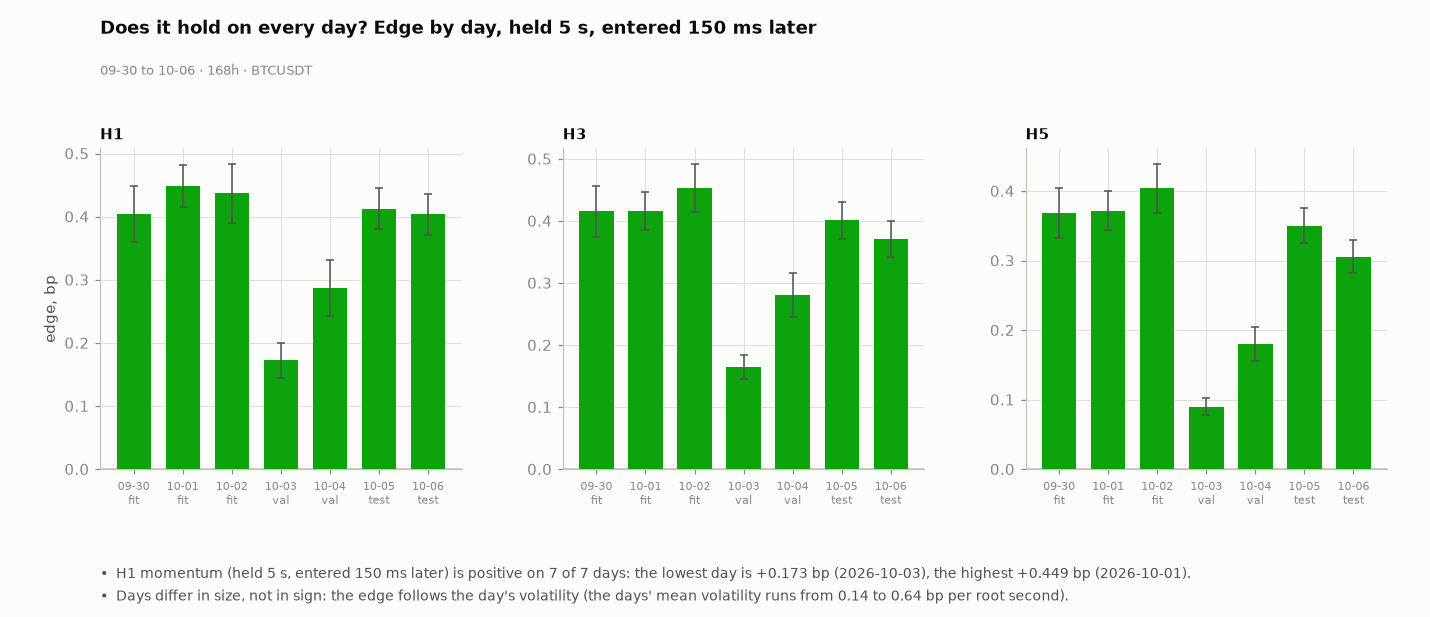

In [47]:
ALLD = {**FIT, **VAL, **TEST}
DAILY = A.daily_edges(ALLD, CLIP, TH, hyps=("H1", "H3", "H5"), h=5.0, roles=ROLE)
_pk = DAILY[DAILY.hyp == PACK]
_pos = int((_pk.edge_bp > 0).sum())
_bul = [f"{PACK_NAME} (held 5 s, entered {LAT_BAR_MS} ms later) is positive on {_pos} of {len(_pk)} days: the lowest day is {sgn(float(_pk.edge_bp.min()), 3)} bp ({_pk.loc[_pk.edge_bp.idxmin(), 'day']}), the highest {sgn(float(_pk.edge_bp.max()), 3)} bp ({_pk.loc[_pk.edge_bp.idxmax(), 'day']}).",
        f"Days differ in size, not in sign: the edge follows the day's volatility (the days' mean volatility runs from {min(float(np.mean(d.F['sigma_slow'])) for d in ALLD.values()):.2f} to {max(float(np.mean(d.F['sigma_slow'])) for d in ALLD.values()):.2f} bp per root second)."]
fig = FG.daily(DAILY, ROLE, ("H1", "H3", "H5"), WIN_ALL, _bul, "Does it hold on every day? Edge by day, held 5 s, entered 150 ms later")
figstyle.show(fig, "fig:s4-daily", FIGURES)
GATES.append({"id": "G13", "section": "S4", "label": "Positive every day", "name": f"{PACK_NAME}: the edge at 150 ms and 5 s is above zero on each of the seven days",
              "reading": f"{_pos} of {len(_pk)} days positive; the weakest day {sgn(float(_pk.edge_bp.min()), 3)} bp, t {float(_pk.t.min()):+.1f}", "verdict": "PASS" if _pos == len(_pk) else "FAIL",
              "would_change": "a day with an edge at or below zero"})

**A simple signal against models**

Ridge regression, logistic regression (on the direction of the move) and a small gradient-boosted tree ensemble, all on the price-only features, fitted on the fit days. The setting of each (ridge penalty, tree depth, logistic penalty) is chosen on the validation days by correlation; the test days are read once. Targets are the return from 150 ms after the instant held 1, 5, 10 and 30 s. The simple signal is compared at equal time in the market: the models' top and bottom slices are cut to the time the simple signal is on.

In [48]:
t0 = time.time()
MODELS, TRIALS = A.run_models(FIT, VAL, NAMES, CLIP, MODEL_H, log=lambda s_: print(s_, flush=True))
N_TESTS["models fitted (settings x targets)"] = int(len(TRIALS))
print(f"models fitted in {time.time() - t0:.0f}s: {len(TRIALS)} fits")
display(HTML(TRIALS.round(4).to_html(index=False, border=0)))

  h=1s gbm depth 2: validation rho 0.1305


  h=1s gbm depth 3: validation rho 0.1337


  h=5s gbm depth 2: validation rho 0.1715


  h=5s gbm depth 3: validation rho 0.1752


  h=10s gbm depth 2: validation rho 0.1652


  h=10s gbm depth 3: validation rho 0.1678


  h=30s gbm depth 2: validation rho 0.1196


  h=30s gbm depth 3: validation rho 0.1214


models fitted in 536s: 28 fits

model,setting,h_s,val_rho
ridge,lambda 0.0001,1.0,0.1001
ridge,lambda 0.01,1.0,0.1005
ridge,lambda 1,1.0,0.0927
logistic,l2 1,1.0,0.0100
logistic,l2 100,1.0,0.0098
gbm,depth 2,1.0,0.1305
gbm,depth 3,1.0,0.1337
ridge,lambda 0.0001,5.0,0.1312
ridge,lambda 0.01,5.0,0.1322
ridge,lambda 1,5.0,0.1264


In [49]:
# ---- the test-day read of every chosen model, against the simple signal at equal time in the market ----
_Wt = ST.stack(TEST, "W").astype(np.float64)
_xt, _mt = X_PACK[PACK]
_on_pos = float((_Wt * ((np.sign(_xt) > 0) & _mt)).sum()); _on_neg = float((_Wt * ((np.sign(_xt) < 0) & _mt)).sum())
_wall = float(_Wt.sum())
def slice_eval(score, coh, j, share_pos, share_neg):
    """Mean target in the top `share_pos` and bottom `share_neg` of the TIME of the score, and their difference with a block-clustered standard error."""
    y, w = coh.Y[:, j], coh.W
    o = np.argsort(score, kind="stable")
    cw = np.cumsum(w[o]) / w.sum()
    bot = np.zeros(len(y), bool); top = np.zeros(len(y), bool)
    bot[o[cw <= share_neg]] = True
    top[o[cw >= 1 - share_pos]] = True
    wt, wb = w * top, w * bot
    mt, mb = (wt * y).sum() / wt.sum(), (wb * y).sum() / wb.sum()
    S = np.add.reduceat(wt * (y - mt) / wt.sum() - wb * (y - mb) / wb.sum(), coh.starts)
    se = float(np.sqrt((S * S).sum()))
    return dict(top_bp=float(mt), bottom_bp=float(mb), spread_bp=float(mt - mb), spread_se=se, spread_t=float((mt - mb) / se) if se else np.nan)
_rows = []
for h in MODEL_H:
    j = [i for i, (li, hj) in enumerate(COH_TEST.cols) if LF.LATENCIES_MS[li] == LAT_BAR_MS and LF.HORIZONS_S[hj] == h][0]
    ge = lambda sc: slice_eval(sc, COH_TEST, j, _on_pos / _wall, _on_neg / _wall)
    pack_score = np.where(_mt, np.sign(_xt) * np.abs(_xt), 0.0) + 1e-9 * np.arange(len(_xt)) / len(_xt)    # ties broken by time so equal-time slices exist
    r = dict(name="simple signal", h_s=h, rho=A.wrho(np.where(_mt, _xt, 0.0), COH_TEST.Y[:, j], COH_TEST.W), **ge(pack_score))
    _rows.append(r)
    for kind in ("ridge", "logistic", "gbm"):
        pr = A.predict(MODELS, TEST, h, kind)
        _rows.append(dict(name=kind, h_s=h, rho=A.wrho(pr, COH_TEST.Y[:, j], COH_TEST.W), **ge(pr + 1e-12 * np.arange(len(pr)) / len(pr))))
MODEL_TAB = pd.DataFrame(_rows)
N_TESTS["model reads on the test days"] = int(len(MODEL_TAB))
display(Markdown(f"**Test days, entered {LAT_BAR_MS} ms later; top and bottom slices at the time the simple signal ({PACK}) is on ({pct(_on_pos / _wall, 2)} of the time long, {pct(_on_neg / _wall, 2)} short)**\n\n| Hold | Model | Correlation | Top slice, bp | Bottom slice, bp | Spread, bp | Spread t |\n|---|---|---|---|---|---|---|\n" +
                 "\n".join(f"| {r.h_s:g} s | {r.name} | {r.rho:+.3f} | {r.top_bp:+.3f} | {r.bottom_bp:+.3f} | {r.spread_bp:+.3f} | {r.spread_t:+.0f} |" for r in MODEL_TAB.itertuples())))

**Test days, entered 150 ms later; top and bottom slices at the time the simple signal (H1) is on (6.16% of the time long, 6.17% short)**

| Hold | Model | Correlation | Top slice, bp | Bottom slice, bp | Spread, bp | Spread t |
|---|---|---|---|---|---|---|
| 1 s | simple signal | +0.098 | +0.138 | -0.131 | +0.269 | +37 |
| 1 s | ridge | +0.172 | +0.158 | -0.157 | +0.315 | +42 |
| 1 s | logistic | +0.037 | +0.013 | -0.005 | +0.018 | +5 |
| 1 s | gbm | +0.195 | +0.172 | -0.177 | +0.348 | +45 |
| 5 s | simple signal | +0.102 | +0.420 | -0.398 | +0.817 | +34 |
| 5 s | ridge | +0.192 | +0.444 | -0.429 | +0.873 | +32 |
| 5 s | logistic | +0.113 | +0.321 | -0.182 | +0.503 | +27 |
| 5 s | gbm | +0.214 | +0.475 | -0.478 | +0.953 | +36 |
| 10 s | simple signal | +0.089 | +0.553 | -0.535 | +1.088 | +28 |
| 10 s | ridge | +0.171 | +0.588 | -0.559 | +1.146 | +24 |
| 10 s | logistic | +0.136 | +0.511 | -0.451 | +0.963 | +28 |
| 10 s | gbm | +0.185 | +0.590 | -0.611 | +1.201 | +25 |
| 30 s | simple signal | +0.058 | +0.650 | -0.662 | +1.312 | +18 |
| 30 s | ridge | +0.116 | +0.660 | -0.637 | +1.296 | +13 |
| 30 s | logistic | +0.119 | +0.704 | -0.656 | +1.360 | +19 |
| 30 s | gbm | +0.122 | +0.705 | -0.700 | +1.406 | +13 |

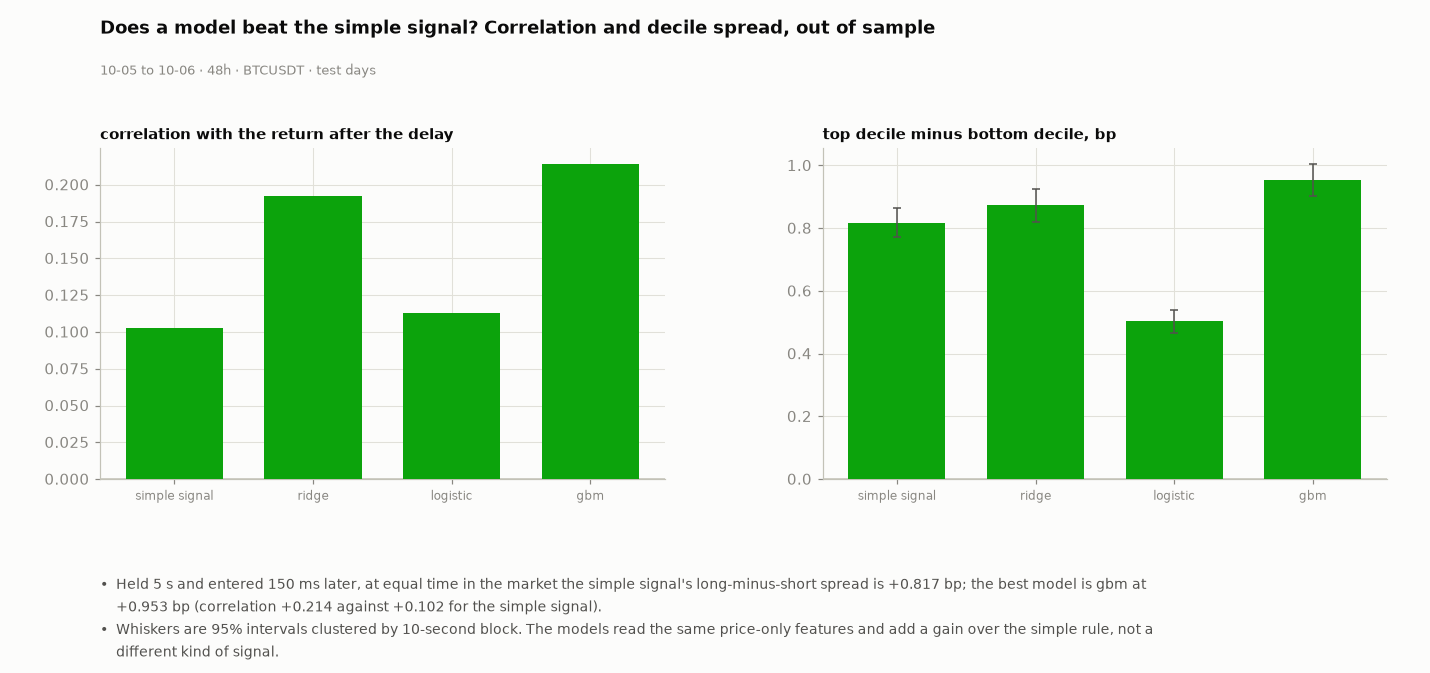

In [50]:
_m5 = MODEL_TAB[MODEL_TAB.h_s == 5.0].reset_index(drop=True)
_best = _m5.loc[_m5.name != "simple signal"].sort_values("spread_bp", ascending=False).iloc[0]
_sim = _m5[_m5.name == "simple signal"].iloc[0]
_bul = [f"Held 5 s and entered {LAT_BAR_MS} ms later, at equal time in the market the simple signal's long-minus-short spread is {sgn(_sim.spread_bp, 3)} bp; the best model is {_best['name']} at {sgn(_best.spread_bp, 3)} bp (correlation {_best.rho:+.3f} against {_sim.rho:+.3f} for the simple signal).",
        "Whiskers are 95% intervals clustered by 10-second block. The models read the same price-only features and add a gain over the simple rule, not a different kind of signal."]
fig = FG.model_bars(_m5, WIN_TEST, _bul)
figstyle.show(fig, "fig:s4-models", FIGURES)
_ratio = float(_best.spread_bp / _sim.spread_bp)
GATES.append({"id": "G14", "section": "S4", "label": "Models vs the rule", "name": "the best model against the simple signal at equal time in the market, held 5 s, test days",
              "reading": f"{_best['name']} spread {sgn(_best.spread_bp, 3)} bp (t {_best.spread_t:+.0f}) against {sgn(_sim.spread_bp, 3)} bp (t {_sim.spread_t:+.0f}) for {PACK}; {_ratio:.2f} times", "verdict": "INFO",
              "would_change": "a model that doubles the simple signal's spread at equal time would be worth building into the pack"})

**State against signal: does it say anything about the 15-minute outcome beyond where the window already stands?**

The old fair-value model said "BTC is up a little, so Up". That is **state**. Here the state is the expected end-of-window average given the path so far (the market pays on a 60 s TWAP at both ends, so the known part of the final minute is in it), and the question is whether a model's predicted next move adds anything to it. The chain runs in date order: the models are fitted on the fit days, the state-plus-signal logistic on the validation days (the models' predictions there are out of sample), and everything is scored on the test days. Rows are every instant from the second minute to ten seconds before the end; the interval resamples whole windows.

In [51]:
H_DRIFT = 30.0                                                # the longest model target: the drift the window can still collect
_pred = lambda days, kind: A.predict(MODELS, days, H_DRIFT, kind)
STATE = {}
for kind in ("gbm", "ridge"):
    fv = A.state_frame(VAL, _pred(VAL, kind), A.window_rows(VAL))
    ft = A.state_frame(TEST, _pred(TEST, kind), A.window_rows(TEST))
    m0, m1 = A.fit_state_models(fv)
    ev, p0, p1 = A.state_eval(ft, m0, m1)
    STATE[kind] = dict(frame=ft, ev=ev, p0=p0, p1=p1, coefs=(m0[2].tolist(), m1[2].tolist()), rm=A.remaining_move(ft, ft.z_drift.to_numpy() * ft.sig_den.to_numpy()))
N_TESTS["state against signal (models x time-left bins)"] = int(sum(len(v["ev"]) for v in STATE.values()))
for kind, v in STATE.items():
    display(Markdown(f"**{kind} drift ({H_DRIFT:g} s model), test days: the state alone against the state plus the predicted drift** (log loss; gain above zero means the signal helped; interval from 500 resamples of whole windows)\n\n| Time left | Windows | Log loss, state | Log loss, plus signal | Gain | 95% interval | Mean absolute change in P(Up) |\n|---|---|---|---|---|---|---|\n" +
                     "\n".join(f"| {r.rows} | {r.windows} | {r.logloss_state:.4f} | {r.logloss_plus:.4f} | {r.gain:+.5f} | {r.lo:+.5f} to {r.hi:+.5f} | {r.mean_abs_lift * 100:.2f} points |" for r in v["ev"].itertuples())))
    display(Markdown(f"**{kind}: the realised move from now to the window end beyond what the average already holds, against the predicted drift** (slope: realised bp per predicted bp)\n\n| Time left | Correlation | Slope | Mean predicted size, bp | Spread of the realised move, bp |\n|---|---|---|---|---|\n" +
                     "\n".join(f"| {r.left} | {r.rho:+.3f} | {r.slope:+.2f} | {r.mean_pred_bp:.3f} | {r.sd_to_end_bp:.2f} |" for r in v["rm"].itertuples())))

**gbm drift (30 s model), test days: the state alone against the state plus the predicted drift** (log loss; gain above zero means the signal helped; interval from 500 resamples of whole windows)

| Time left | Windows | Log loss, state | Log loss, plus signal | Gain | 95% interval | Mean absolute change in P(Up) |
|---|---|---|---|---|---|---|
| all | 192 | 0.4629 | 0.4630 | -0.00000 | -0.00006 to +0.00005 | 0.04 points |
| 10-30 s left | 192 | 0.0203 | 0.0204 | -0.00007 | -0.00040 to +0.00015 | 0.03 points |
| 30-120 s left | 192 | 0.1587 | 0.1588 | -0.00014 | -0.00030 to -0.00002 | 0.04 points |
| 120-300 s left | 192 | 0.3750 | 0.3751 | -0.00003 | -0.00012 to +0.00005 | 0.04 points |
| 300-600 s left | 192 | 0.5147 | 0.5147 | +0.00003 | -0.00004 to +0.00010 | 0.04 points |
| 600-900 s left | 192 | 0.6124 | 0.6124 | +0.00003 | -0.00003 to +0.00009 | 0.04 points |

**gbm: the realised move from now to the window end beyond what the average already holds, against the predicted drift** (slope: realised bp per predicted bp)

| Time left | Correlation | Slope | Mean predicted size, bp | Spread of the realised move, bp |
|---|---|---|---|---|
| 10-30 s | +0.186 | +0.20 | 0.255 | 0.37 |
| 30-120 s | +0.087 | +0.66 | 0.272 | 2.74 |
| 120-300 s | +0.050 | +0.93 | 0.272 | 6.71 |
| 300-600 s | +0.014 | +0.36 | 0.292 | 9.90 |
| 600-900 s | +0.051 | +1.63 | 0.313 | 13.27 |

**ridge drift (30 s model), test days: the state alone against the state plus the predicted drift** (log loss; gain above zero means the signal helped; interval from 500 resamples of whole windows)

| Time left | Windows | Log loss, state | Log loss, plus signal | Gain | 95% interval | Mean absolute change in P(Up) |
|---|---|---|---|---|---|---|
| all | 192 | 0.4629 | 0.4630 | -0.00002 | -0.00005 to +0.00002 | 0.02 points |
| 10-30 s left | 192 | 0.0203 | 0.0203 | +0.00002 | -0.00007 to +0.00016 | 0.01 points |
| 30-120 s left | 192 | 0.1587 | 0.1586 | +0.00004 | +0.00000 to +0.00010 | 0.01 points |
| 120-300 s left | 192 | 0.3750 | 0.3750 | -0.00001 | -0.00004 to +0.00003 | 0.01 points |
| 300-600 s left | 192 | 0.5147 | 0.5147 | -0.00003 | -0.00007 to +0.00001 | 0.02 points |
| 600-900 s left | 192 | 0.6124 | 0.6125 | -0.00003 | -0.00007 to +0.00001 | 0.02 points |

**ridge: the realised move from now to the window end beyond what the average already holds, against the predicted drift** (slope: realised bp per predicted bp)

| Time left | Correlation | Slope | Mean predicted size, bp | Spread of the realised move, bp |
|---|---|---|---|---|
| 10-30 s | +0.171 | +0.20 | 0.248 | 0.37 |
| 30-120 s | +0.093 | +0.76 | 0.262 | 2.74 |
| 120-300 s | +0.061 | +1.22 | 0.263 | 6.71 |
| 300-600 s | +0.012 | +0.35 | 0.275 | 9.90 |
| 600-900 s | +0.030 | +1.11 | 0.285 | 13.27 |

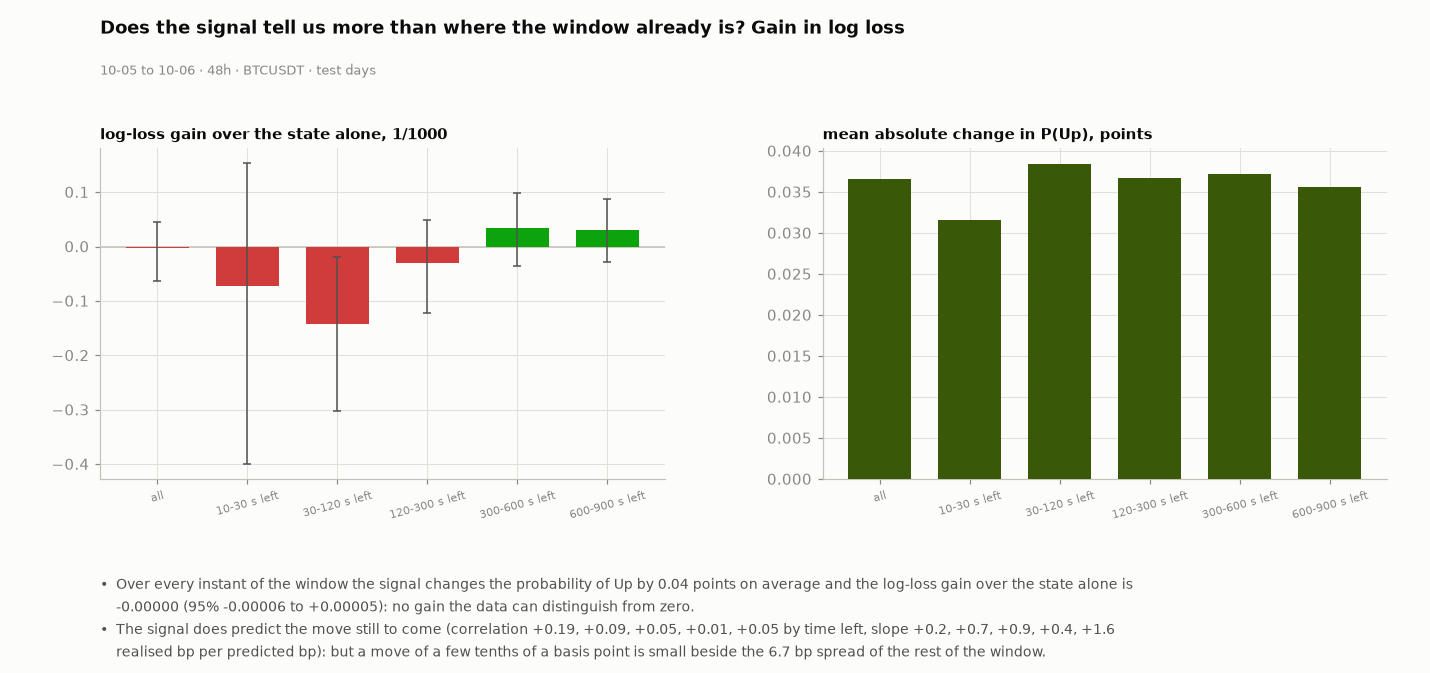

In [52]:
_ev = STATE["gbm"]["ev"]
_all = _ev[_ev.rows == "all"].iloc[0]
_rm = STATE["gbm"]["rm"]
_bul = [f"Over every instant of the window the signal changes the probability of Up by {_all.mean_abs_lift * 100:.2f} points on average and the log-loss gain over the state alone is {_all.gain:+.5f} (95% {_all.lo:+.5f} to {_all.hi:+.5f}): " + ("a measurable gain." if _all.lo > 0 else "no gain the data can distinguish from zero."),
        f"The signal does predict the move still to come (correlation {', '.join(f'{x:+.2f}' for x in _rm.rho)} by time left, slope {', '.join(f'{x:+.1f}' for x in _rm.slope)} realised bp per predicted bp): but a move of a few tenths of a basis point is small beside the {float(_rm.sd_to_end_bp.iloc[2]):.1f} bp spread of the rest of the window."]
fig = FG.state_gain(_ev, WIN_TEST, _bul)
figstyle.show(fig, "fig:s4-state", FIGURES)
GATES.append({"id": "G15", "section": "S4", "label": "Adds to the window", "name": "the signal adds to the state in the probability the window ends Up: log-loss gain of state plus signal over state alone, whole-window interval, test days",
              "reading": f"gain {_all.gain:+.5f}, 95% {_all.lo:+.5f} to {_all.hi:+.5f}; mean absolute change {_all.mean_abs_lift * 100:.2f} points", "verdict": "PASS" if _all.lo > 0 else "FAIL",
              "would_change": "an interval above zero over all instants, or in the last minutes"})

**Planted tests and a placebo**

Three checks that must be able to fail. A planted lookahead: the features read k rows stale or ahead, and the edge must not grow when stale and must grow with k ahead. A placebo: the outcome series rolled by a random lag of 10% to 90% of the sample, which destroys every alignment with the signal and keeps every path. A planted leak: a feature that IS the future return must be flagged by the harness and an honest feature must not.

**Planted lookahead (H1, one validation day, held 5 s):** stale 100 rows: +0.021 bp, stale 12 rows: +0.169 bp, as built rows: +0.287 bp, ahead 6 rows: +1.075 bp, ahead 18 rows: +1.016 bp

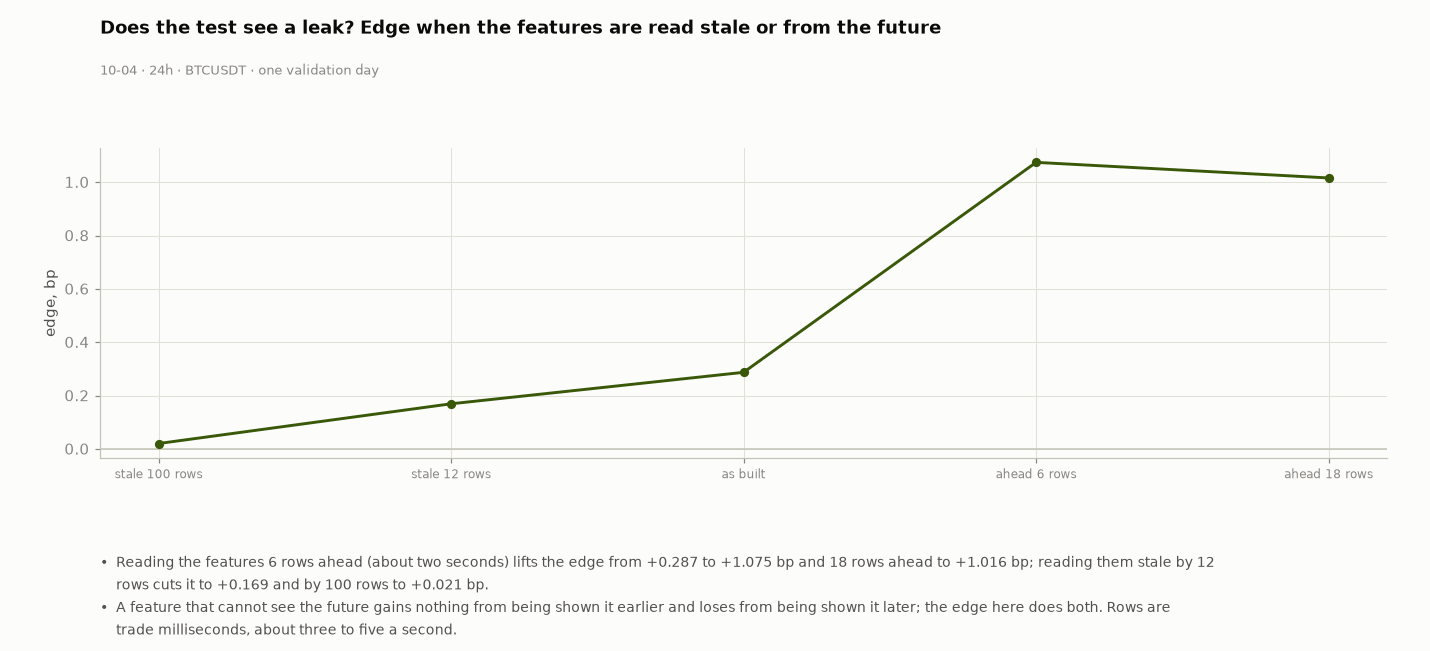

In [53]:
DAY_DOSE = ST.Day(VAL_DAYS[1], SYMBOL)
_pf = P.FAMILY["H1"]
DOSE = pd.DataFrame(V.shift_dose(DAY_DOSE, "z_1s", lambda F: np.abs(F["z_1s"]) >= 1.0, ks=(100, 12, 0, -6, -18), L=LAT_BAR_MS, h=5.0, clip=CLIP[ST.L_IDX[LAT_BAR_MS], ST.H_IDX[5.0]]))
DAY_DOSE.drop_tape()
_d = DOSE.set_index("k").edge_bp
display(Markdown("**Planted lookahead (H1, one validation day, held 5 s):** " + ", ".join(f"{('stale ' + str(k) if k > 0 else ('ahead ' + str(-k) if k < 0 else 'as built'))} rows: {v:+.3f} bp" for k, v in _d.sort_index(ascending=False).items())))
_dose_ok = bool(_d.loc[100] < _d.loc[12] < _d.loc[0] < _d.loc[-6] and _d.loc[-18] > 2 * _d.loc[0])
_bul = [f"Reading the features 6 rows ahead (about two seconds) lifts the edge from {sgn(float(_d.loc[0]), 3)} to {sgn(float(_d.loc[-6]), 3)} bp and 18 rows ahead to {sgn(float(_d.loc[-18]), 3)} bp; reading them stale by 12 rows cuts it to {sgn(float(_d.loc[12]), 3)} and by 100 rows to {sgn(float(_d.loc[100]), 3)} bp.",
        "A feature that cannot see the future gains nothing from being shown it earlier and loses from being shown it later; the edge here does both. Rows are trade milliseconds, about three to five a second."]
fig = FG.dose(DOSE, f"{VAL_DAYS[1][5:]} · 24h · BTCUSDT · one validation day", _bul)
figstyle.show(fig, "fig:s4-dose", FIGURES)
VERIFY["passed"] += int(_dose_ok); VERIFY["total"] += 1

In [54]:
_xt, _mt = X_PACK[PACK]
_j = [i for i, (li, hj) in enumerate(COH_TEST.cols) if LF.LATENCIES_MS[li] == LAT_BAR_MS and LF.HORIZONS_S[hj] == 5.0][0]
SHUF = V.shuffle_test(_xt, _mt, COH_TEST.Y[:, _j], COH_TEST.W, reps=300, seed=SEED)
P_SHUF = SHUF["p"]
_y = COH_TEST.Y[:, _j]
_flag_leak, _rho_leak = V.leak_flag(_y, _y, COH_TEST.W)
_flag_ok, _rho_ok = V.leak_flag(ST.stack(TEST, "z_1s").astype(float), _y, COH_TEST.W)
display(Markdown(f"**Placebo (300 random rolls of the outcome, {PACK}, test days, held 5 s):** real edge {SHUF['real']:+.3f} bp against a placebo mean {SHUF['null_mean']:+.4f} bp and spread {SHUF['null_sd']:.4f} bp: {SHUF['z']:+.1f} placebo standard deviations. "
                 f"**Planted leak:** a feature equal to the future return is flagged ({_flag_leak}, correlation {_rho_leak:+.2f}); the honest z_1s is not ({_flag_ok}, correlation {_rho_ok:+.3f})."))
assert _flag_leak and not _flag_ok
VERIFY["passed"] += 2 + int(SHUF["z"] > 3); VERIFY["total"] += 3
GATES.append({"id": "G16", "section": "S4", "label": "Beats the placebo", "name": f"{PACK_NAME}: the test-day edge at 150 ms and 5 s against 300 rolls of the outcome; a planted lookahead raises it with the shift, a planted leak is flagged",
              "reading": f"{SHUF['z']:+.1f} placebo standard deviations; planted lookahead dose response {'ordered' if _dose_ok else 'NOT ordered'}; planted leak flagged",
              "verdict": "PASS" if (SHUF["z"] > 3 and _dose_ok and _flag_leak) else "FAIL", "would_change": "a placebo spread as wide as the edge, a dose response out of order, or a leak not flagged"})

**Placebo (300 random rolls of the outcome, H1, test days, held 5 s):** real edge +0.409 bp against a placebo mean -0.0008 bp and spread 0.0147 bp: +27.8 placebo standard deviations. **Planted leak:** a feature equal to the future return is flagged (True, correlation +1.00); the honest z_1s is not (False, correlation +0.114).

**The other coins: a different instrument, the same days**

H1, H3 and H5 on ETHUSDT, SOLUSDT and XRPUSDT with their own fit-day thresholds, over the validation and test days. This is the same mechanic on other carriers, not an independent replication: the four coins move together in the same regime.

ETHUSDT: built and read in 29s


SOLUSDT: built and read in 17s


XRPUSDT: built and read in 15s


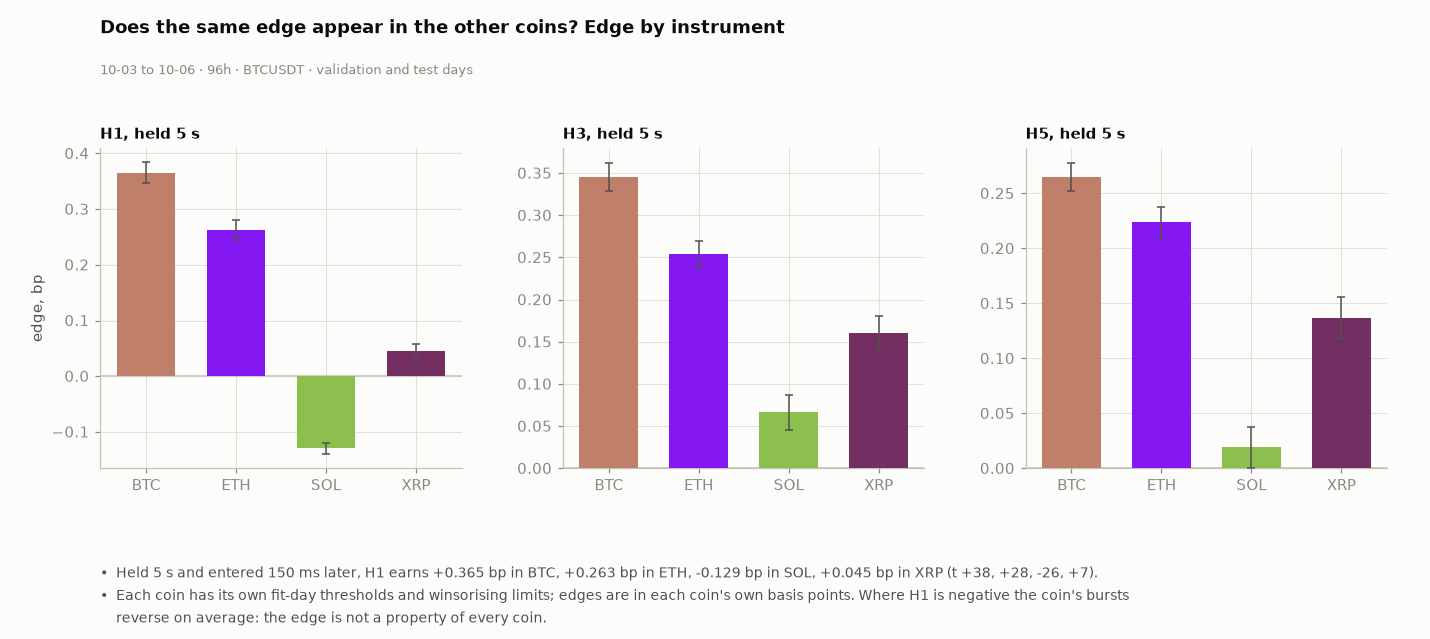

In [55]:
_rows = []
for sym in ("BTCUSDT", "ETHUSDT", "SOLUSDT", "XRPUSDT"):
    if sym == SYMBOL:
        clip_, th_ = CLIP, TH
        ft_ = P.family_table(OOS, clip_, th_)
        ft_ = ft_[ft_.hyp.isin(("H1", "H3", "H5"))].copy()
        ft_["asset"] = "btc"
    else:
        t0 = time.time()
        ft_ = A.asset_family(sym, FIT_DAYS, VAL_DAYS + TEST_DAYS)
        print(f"{sym}: built and read in {time.time() - t0:.0f}s")
    _rows.append(ft_)
ASSET = pd.concat(_rows, ignore_index=True)
N_TESTS["other coins (3 coins x hypotheses x horizons)"] = int(len(ASSET[ASSET.asset != "btc"]))
_a5 = ASSET[ASSET.h_s == 5.0]
_h1 = "H1"
_bul = [f"Held 5 s and entered {LAT_BAR_MS} ms later, H1 earns " + ", ".join(f"{sgn(float(_a5[(_a5.asset == a_) & (_a5.hyp == _h1)].edge_bp.iloc[0]), 3)} bp in {a_.upper()}" for a_ in ("btc", "eth", "sol", "xrp")) + f" (t {', '.join(f'{float(_a5[(_a5.asset == a_) & (_a5.hyp == _h1)].t.iloc[0]):+.0f}' for a_ in ('btc', 'eth', 'sol', 'xrp'))}).",
        "Each coin has its own fit-day thresholds and winsorising limits; edges are in each coin's own basis points. " + ("Where H1 is negative the coin's bursts reverse on average: the edge is not a property of every coin." if (_a5[_a5.hyp == _h1].edge_bp < 0).any() else "H1 is positive in every coin.")]
fig = FG.assets(ASSET, WIN_OOS, _bul, ("H1", "H3", "H5"))
figstyle.show(fig, "fig:s4-assets", FIGURES)
_n_ok = int(sum(1 for a_ in ("eth", "sol", "xrp") for h_ in ("H1", "H3", "H5") if (ASSET[(ASSET.asset == a_) & (ASSET.hyp == h_)].t >= T_BAR).all()))
GATES.append({"id": "G17", "section": "S4", "label": "Other coins agree", "name": "H1, H3 and H5 on ETH, SOL and XRP over the validation and test days: t at the bar at every hold",
              "reading": f"{_n_ok} of 9 coin-hypothesis pairs hold at every hold", "verdict": "PASS" if _n_ok == 9 else ("FLAG" if _n_ok > 0 else "FAIL"), "would_change": "a coin where momentum does not appear"})

**Polymarket: the same triggers with other sides, and the planted variants**

Every variant sends the same orders at the same moments as the chosen configuration and changes only the side (random, reversed) or the information the side uses (a peek at the next seconds, which no trader has; a signal read late). The placebo is a distribution of draws, not one coin flip.

In [56]:
def per_entry(df):
    return float(df.net.mean()) if len(df) else np.nan
_V = TEST_ENT.groupby("variant")
VAR = pd.DataFrame({k_: BT.summarize(g_) for k_, g_ in _V}).T
RAND = VAR[VAR.index.str.startswith("rand")]
RAND_PE = RAND.per_entry.astype(float)
REAL_PE = TS["per_entry"]
P_RAND = float((1 + (RAND_PE >= REAL_PE).sum()) / (1 + len(RAND_PE)))
FADE, PEEK, STALE = VAR.loc["fade"], VAR.loc[f"peek{PEEK_S:g}"], VAR.loc[f"stale{STALE_S:g}"]
display(Markdown(f"**Test days, net PnL per entry in USD** (same orders, same moments)\n\n| Variant | Entries | Win | Net per entry | Before fee per entry |\n|---|---|---|---|---|\n"
                 f"| the pack, as registered | {TS['n']} | {pct(TS['win'])} | {TS['per_entry']:+.2f} | {TS['gross_per_entry']:+.2f} |\n"
                 f"| side reversed | {int(FADE.n)} | {pct(FADE.win)} | {FADE.per_entry:+.2f} | {FADE.gross_per_entry:+.2f} |\n"
                 f"| random sides, mean of {len(RAND_PE)} draws | {RAND.n.astype(float).mean():.0f} | {pct(float(RAND.win.astype(float).mean()))} | {RAND_PE.mean():+.2f} | {float(RAND.gross_per_entry.astype(float).mean()):+.2f} |\n"
                 f"| signal read {STALE_S:g} s late | {int(STALE.n)} | {pct(STALE.win)} | {STALE.per_entry:+.2f} | {STALE.gross_per_entry:+.2f} |\n"
                 f"| PLANTED: side from the next {PEEK_S:g} s | {int(PEEK.n)} | {pct(PEEK.win)} | {PEEK.per_entry:+.2f} | {PEEK.gross_per_entry:+.2f} |"))
display(Markdown(f"Random sides: 5th to 95th percentile of the net PnL per entry {np.percentile(RAND_PE, 5):+.2f} to {np.percentile(RAND_PE, 95):+.2f}; {int((RAND_PE >= REAL_PE).sum())} of {len(RAND_PE)} draws are at or above the pack's {REAL_PE:+.2f} (p = {P_RAND:.3f})."))

**Test days, net PnL per entry in USD** (same orders, same moments)

| Variant | Entries | Win | Net per entry | Before fee per entry |
|---|---|---|---|---|
| the pack, as registered | 88 | 55.7% | +0.91 | +1.97 |
| side reversed | 87 | 27.6% | -8.39 | -7.49 |
| random sides, mean of 200 draws | 88 | 42.6% | -3.45 | -2.46 |
| signal read 5 s late | 89 | 49.4% | -0.82 | +0.27 |
| PLANTED: side from the next 3 s | 83 | 66.3% | +3.89 | +4.92 |

Random sides: 5th to 95th percentile of the net PnL per entry -5.96 to -0.83; 0 of 200 draws are at or above the pack's +0.91 (p = 0.005).

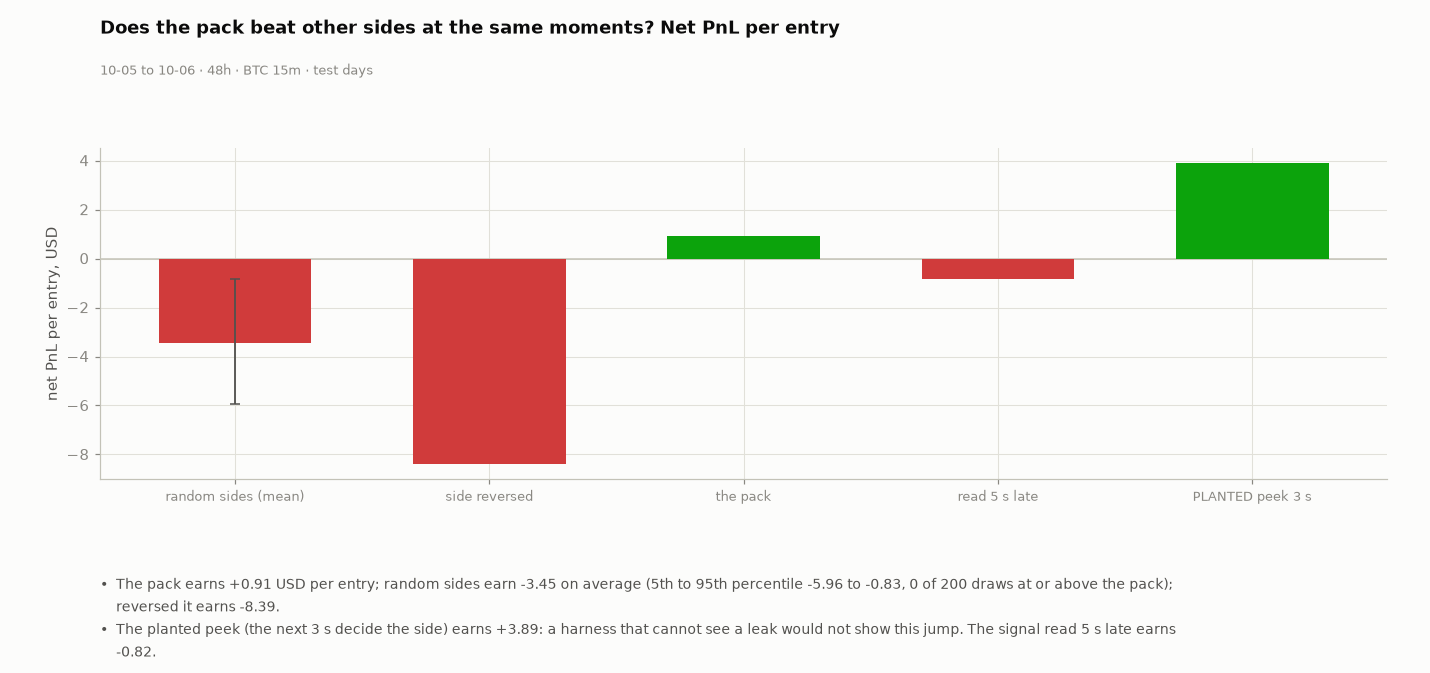

In [57]:
_lab = ["random sides (mean)", "side reversed", "the pack", f"read {STALE_S:g} s late", f"PLANTED peek {PEEK_S:g} s"]
_val = [RAND_PE.mean(), FADE.per_entry, REAL_PE, STALE.per_entry, PEEK.per_entry]
_bul = [f"The pack earns {REAL_PE:+.2f} USD per entry; random sides earn {RAND_PE.mean():+.2f} on average (5th to 95th percentile {np.percentile(RAND_PE, 5):+.2f} to {np.percentile(RAND_PE, 95):+.2f}, {int((RAND_PE >= REAL_PE).sum())} of {len(RAND_PE)} draws at or above the pack); reversed it earns {FADE.per_entry:+.2f}.",
        f"The planted peek (the next {PEEK_S:g} s decide the side) earns {PEEK.per_entry:+.2f}: a harness that cannot see a leak would not show this jump. The signal read {STALE_S:g} s late earns {STALE.per_entry:+.2f}."]
fig, ax = FG.frame(3.8, _bul, "Does the pack beat other sides at the same moments? Net PnL per entry", WIN_PM_TEST)
a = ax[0]
x = np.arange(len(_lab))
a.bar(x, _val, color=[FG.GOOD if v >= 0 else FG.BAD for v in _val], width=0.6, zorder=3)
a.errorbar([0], [RAND_PE.mean()], yerr=[[RAND_PE.mean() - np.percentile(RAND_PE, 5)], [np.percentile(RAND_PE, 95) - RAND_PE.mean()]], fmt="none", color=FG.N["ink2"], ecolor=FG.N["ink2"], capsize=3, elinewidth=1.2, zorder=4)
FG.zero(a)
a.set_xticks(x); a.set_xticklabels(_lab, fontsize=8.5); a.set_ylabel("net PnL per entry, USD")
figstyle.show(fig, "fig:s4-benchmarks", FIGURES)
_beats = REAL_PE > FADE.per_entry and P_RAND < 0.05
GATES.append({"id": "G18", "section": "S4", "label": "Beats other sides", "name": "the chosen configuration against the same orders with random sides (200 draws) and with the side reversed, net PnL per entry, test days",
              "reading": f"pack {REAL_PE:+.2f}, reversed {FADE.per_entry:+.2f}, random mean {RAND_PE.mean():+.2f} ({int((RAND_PE >= REAL_PE).sum())} of {len(RAND_PE)} draws at or above, p {P_RAND:.3f})", "verdict": "PASS" if _beats else "FAIL",
              "would_change": "a random-side draw as good as the pack more than one time in twenty, or a reversed side that pays as much"})
_peek_ok, _stale_ok = PEEK.per_entry > REAL_PE, STALE.per_entry < REAL_PE
GATES.append({"id": "G19", "section": "S4", "label": "Planted peek is seen", "name": "a side taken from the next 3 s pays more than the pack, and a signal read 5 s late pays less",
              "reading": f"peek {PEEK.per_entry:+.2f}, pack {REAL_PE:+.2f}, stale {STALE.per_entry:+.2f} USD per entry", "verdict": "PASS" if (_peek_ok and _stale_ok) else ("FLAG" if _peek_ok else "FAIL"),
              "would_change": "a peek that does not pay more, or a stale signal that pays as much"})
VERIFY["passed"] += int(_peek_ok) + int(_stale_ok) + int(P_RAND < 0.05); VERIFY["total"] += 3

**Polymarket: day by day, the lag on all four days, and what was tried**

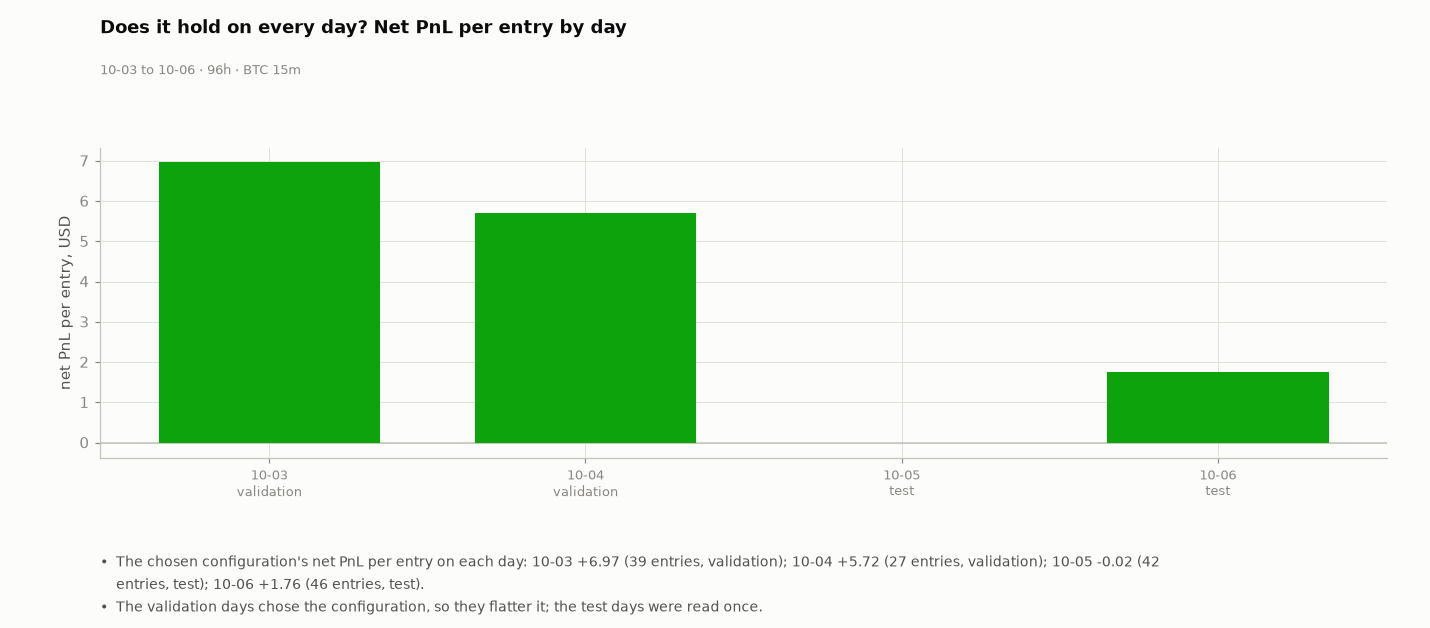

**The lag on all four days (10,519 signals):** between +150 ms and +1150 ms the Up mid moves +2.63 cents in the signal's direction and the Binance-implied P(Up) +0.54. The mid has covered 52% of the Binance-implied move by +150 ms.

family,trials
"registered grid, validation days",24
"benchmarks and planted variants, test days",203
"delay sweep, test days",7


24 configurations were tried to choose one, on two days of one regime: the chosen validation number is the best of 22 eligible and a deflation of it would be a large one; the test days carry the verdict, and they are two days.

In [58]:
_dy = TE.groupby("day").apply(lambda d: pd.Series(BT.summarize(d)), include_groups=False)
_vd = VAL_ENT[VAL_ENT.cfg == CHOSEN_NAME].groupby("day").apply(lambda d: pd.Series(BT.summarize(d)), include_groups=False)
_bt_days = pd.concat([_vd.assign(role="validation"), _dy.assign(role="test")])
_bul = [f"The chosen configuration's net PnL per entry on each day: " + "; ".join(f"{d_[5:]} {r_.per_entry:+.2f} ({int(r_.n)} entries, {r_.role})" for d_, r_ in _bt_days.iterrows()) + ".",
        "The validation days chose the configuration, so they flatter it; the test days were read once."]
fig, ax = FG.frame(3.6, _bul, "Does it hold on every day? Net PnL per entry by day", WIN_PM_ALL)
a = ax[0]
x = np.arange(len(_bt_days))
FG.signbar(a, x, _bt_days.per_entry, None)
FG.zero(a)
a.set_xticks(x); a.set_xticklabels([f"{d_[5:]}\n{r_.role}" for d_, r_ in _bt_days.iterrows()], fontsize=8.5); a.set_ylabel("net PnL per entry, USD")
figstyle.show(fig, "fig:s4-pm-daily", FIGURES)
LG_ALL = lag_stack(VAL_LAG + TEST_LAG)
LAG_CENTS_ALL = float(np.nanmean(LG_ALL["mid"][:, _o(1150)] - LG_ALL["mid"][:, _o(150)]) * 100)
FAIR_CENTS_ALL = float(np.nanmean(LG_ALL["fair"][:, _o(1150)] - LG_ALL["fair"][:, _o(150)]) * 100)
display(Markdown(f"**The lag on all four days ({len(LG_ALL['mid']):,} signals):** between +150 ms and +1150 ms the Up mid moves {LAG_CENTS_ALL:+.2f} cents in the signal's direction and the Binance-implied P(Up) {FAIR_CENTS_ALL:+.2f}. The mid has covered {pct(float(np.nanmean(LG_ALL['mid'][:, _o(150)]) / np.nanmean(LG_ALL['fair'][:, _o(150)])), 0)} of the Binance-implied move by +150 ms."))
_trials = pd.DataFrame([{"family": "registered grid, validation days", "trials": N_TRIALS}, {"family": "benchmarks and planted variants, test days", "trials": len(VARIANTS)}, {"family": "delay sweep, test days", "trials": len(LATENCIES)}])
display(HTML(_trials.to_html(index=False, border=0)))
display(Markdown(f"{N_TRIALS} configurations were tried to choose one, on two days of one regime: the chosen validation number is the best of {len(ELIG)} eligible and a deflation of it would be a large one; the test days carry the verdict, and they are two days."))

**How many things were tried, and what is exploratory**

Every family of tests the study ran, so the reader can discount.

In [59]:
_NT = pd.DataFrame([{"family": k_, "tests": v_, "status": ("exploratory" if ("scan" in k_) else ("confirmatory, pre-registered" if "confirmatory" in k_ else ("pre-registered selection" if "registered grid" in k_ else "robustness")))} for k_, v_ in N_TESTS.items()])
display(HTML(_NT.to_html(index=False, border=0)))
N_TOTAL = int(_NT.tests.sum())
display(Markdown(f"**{N_TOTAL:,} tests in all**, of which {int(_NT[_NT.status == 'exploratory'].tests.sum()):,} are the exploratory scan and {int(_NT[_NT.status.str.startswith('confirmatory')].tests.sum())} the pre-registered family; only the family and the registered grid carry a bar. The scan ranks features, the robustness cells report what each family did; neither is a confirmation."))

family,tests,status
"registered grid, Polymarket validation days (configurations)",24,pre-registered selection
exploratory scan (features x targets),1722,exploratory
confirmatory family (hypotheses x horizons),24,"confirmatory, pre-registered"
"delay sweep, Polymarket test days (delays)",7,robustness
models fitted (settings x targets),28,robustness
model reads on the test days,16,robustness
state against signal (models x time-left bins),12,robustness
other coins (3 coins x hypotheses x horizons),27,robustness


**1,860 tests in all**, of which 1,722 are the exploratory scan and 24 the pre-registered family; only the family and the registered grid carry a bar. The scan ranks features, the robustness cells report what each family did; neither is a confirmation.

**Gate to S5.** Part A: the strongest simple signal passes the delay, the days and the placebo (G12, G13, G16), no planted fault goes unseen, and whether it adds to the 15-minute outcome beyond the state is reported as measured (G15). Part B: the chosen configuration is read against other sides, a planted peek and the delay (G18, G19, G20).

## S5 · Risk and diagnostics - Why do we lose?

| question | answer form |
|---|---|
| Part A: can the edge be earned, trade by trade: how often does the signal fire as a separate episode, what does an episode earn, is it spread over the day or in a few bursts, and what is a basis point worth to a 15-minute contract? | episodes a day, edge per episode, share of the edge in the best minutes, and the arithmetic of cents per basis point |
| Part B: where does the PnL come from and where does it leak: by price paid, by time left, by exit, and what are the spread, the depth and the fee per share? | tables by bucket, a bar chart by price paid, the cost of each fill in cents a share |

**Binance: what a trade of the signal earns, and how concentrated it is**

In [60]:
ANS6 = display(Markdown("_The answer is written here when the run reaches the test entries._"), display_id=True)

**We do not lose on the point estimate: before the fee an entry makes +1.97 USD, the fee takes 1.06 and the spread is 1.8 cents a share, so the net is +0.91 USD an entry** (10-05 to 10-06 · 48h · BTC 15m · test days); the gain has a 95% range of -2.24 to +4.05 by window, which is why it is not yet a gain we can bank.

In [61]:
# ---- episodes: a trader acts once when a burst starts; later rows of the same burst know more of it ----
_tg = [(LAT_BAR_MS, h) for h in (1.0, 5.0, 10.0, 30.0, 60.0)]
CU = ST.Cohort(TEST, _tg, CLIP, weighted=False)
_xt, _mt = X_PACK[PACK]
EP, FIRST = A.episode_table(TEST, CU, _xt, _mt)
_hrs_cov = float(ST.stack(TEST, "W").sum() / 3600.0)
display(Markdown(f"**{PACK_NAME}, test days: one trade per episode** (rows of one sign closer than {EPISODE_GAP_MS / 1000:g} s are one episode; entered {LAT_BAR_MS} ms after its first row)\n\n| Hold | Episodes | Per hour | Edge per episode, bp | t | Win share | Edge by day, bp |\n|---|---|---|---|---|---|---|\n" +
                 "\n".join(f"| {r.h_s:g} s | {r.episodes:,} | {r.per_hour:.0f} | {r.edge_bp:+.3f} | {r.t:+.1f} | {pct(r.win_share)} | {' / '.join(f'{x:+.2f}' for x in r.per_day)} |" for r in EP.itertuples())))
_rows = []
for h_ in ("H1", "H3", "H5"):
    x_, m_ = X_PACK[h_]
    f_ = A.episodes(COH_TEST.T, x_, m_)
    on = float((COH_TEST.W * ((x_ != 0) & m_)).sum())
    _rows.append(f"| {h_} {P.FAMILY[h_]['label']} | {pct(on / float(COH_TEST.W.sum()), 2)} | {f_.sum() / (len(TEST) * 24):.0f} | {on / max(int(f_.sum()), 1):.1f} s |")
display(Markdown("**How often each signal is on** (test days)\n\n| Signal | Share of the time on | Episodes an hour | Time on per episode |\n|---|---|---|---|\n" + "\n".join(_rows)))
_e5 = EP[EP.h_s == 5.0].iloc[0]
GATES.append({"id": "G21", "section": "S5", "label": "Earned per episode", "name": f"{PACK_NAME}: one trade per episode, 150 ms after its first row, held 5 s, test days: edge above zero with t at the bar",
              "reading": f"{int(_e5.episodes):,} episodes, edge {_e5.edge_bp:+.3f} bp per episode, t {_e5.t:+.1f}, win share {pct(_e5.win_share)}", "verdict": "PASS" if (_e5.edge_bp > 0 and _e5.t >= T_BAR) else "FAIL",
              "would_change": "an edge per episode at or below zero, or a t under the bar"})

**H1 momentum, test days: one trade per episode** (rows of one sign closer than 5 s are one episode; entered 150 ms after its first row)

| Hold | Episodes | Per hour | Edge per episode, bp | t | Win share | Edge by day, bp |
|---|---|---|---|---|---|---|
| 1 s | 9,634 | 201 | +0.220 | +35.2 | 73.8% | +0.23 / +0.21 |
| 5 s | 9,634 | 201 | +0.506 | +39.7 | 75.4% | +0.52 / +0.49 |
| 10 s | 9,634 | 201 | +0.640 | +35.8 | 72.1% | +0.65 / +0.63 |
| 30 s | 9,634 | 201 | +0.766 | +25.3 | 64.1% | +0.77 / +0.76 |
| 60 s | 9,634 | 201 | +0.846 | +19.5 | 59.8% | +0.85 / +0.84 |

**How often each signal is on** (test days)

| Signal | Share of the time on | Episodes an hour | Time on per episode |
|---|---|---|---|
| H1 Short-term momentum | 12.33% | 201 | 2.0 s |
| H3 Breakout continuation | 20.08% | 190 | 3.5 s |
| H5 Multi-horizon confirmation | 25.07% | 288 | 2.9 s |

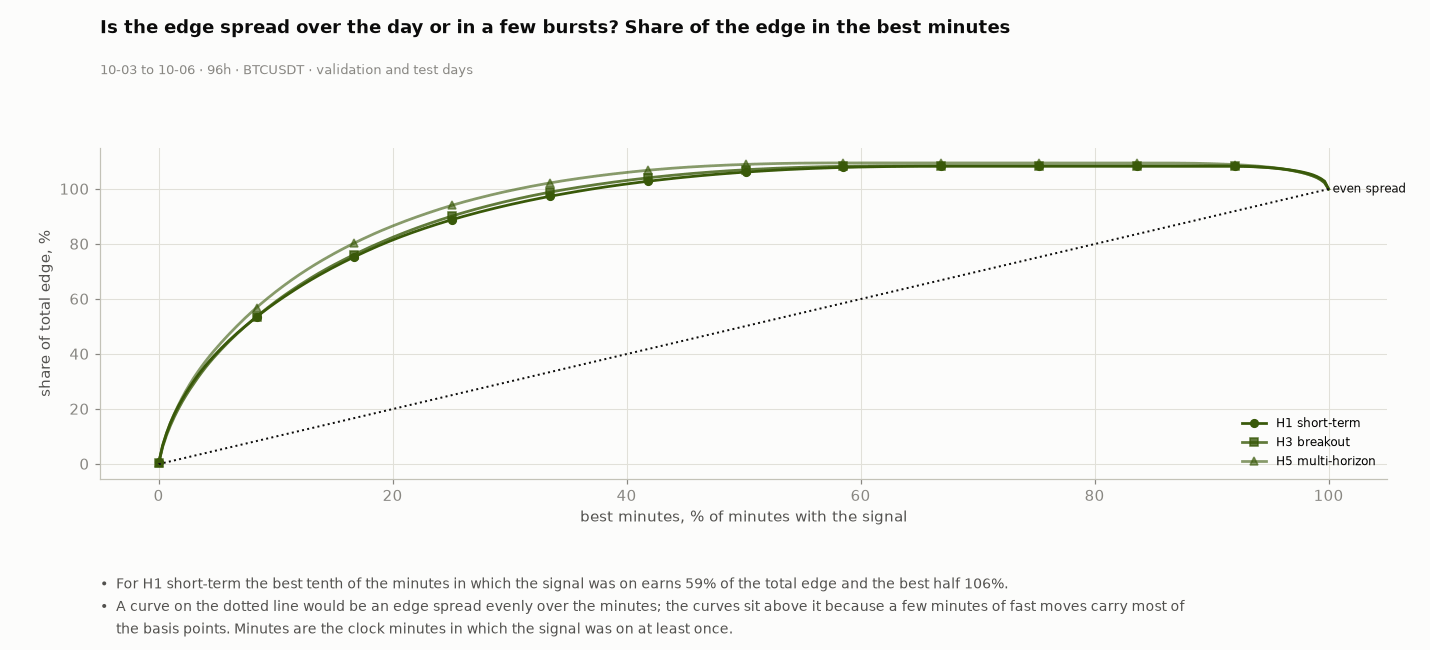

In [62]:
# ---- is the edge spread over the day or in a few bursts? share of the total edge earned in the best minutes ----
_j = [i for i, (li, hj) in enumerate(COH_ALL.cols) if LF.LATENCIES_MS[li] == LAT_BAR_MS and LF.HORIZONS_S[hj] == 5.0][0]
CONC = {f"{h_} {P.FAMILY[h_]['label'].split()[0].lower()}": A.concentration_curve(COH_ALL, *M_OOS[h_], j=_j) for h_ in ("H1", "H3", "H5")}
def share_at(curve, frac):
    x_, y_ = curve
    return float(np.interp(frac, x_, y_))
_k = list(CONC)[0]
_bul = [f"For {_k} the best tenth of the minutes in which the signal was on earns {pct(share_at(CONC[_k], 0.1), 0)} of the total edge and the best half {pct(share_at(CONC[_k], 0.5), 0)}.",
        "A curve on the dotted line would be an edge spread evenly over the minutes; the curves sit above it because a few minutes of fast moves carry most of the basis points. Minutes are the clock minutes in which the signal was on at least once."]
fig = FG.concentration(CONC, WIN_OOS, _bul)
figstyle.show(fig, "fig:s5-concentration", FIGURES)

In [63]:
# ---- arithmetic, not a result: what a basis point is worth to a 15-minute Up/Down contract at the money, as the end nears ----
from math import erf, exp, pi, sqrt
_sig_med = float(np.median(ST.stack(TEST, "sigma_slow")))             # bp per root second
_edge = {h: float(LT[(LT.L_ms == LAT_BAR_MS) & (LT.h_s == h)].edge_bp.iloc[0]) for h in (5.0, 30.0, 60.0, 120.0, 300.0)}
def cents_per_bp(left_s):
    v = (left_s - 40.0) if left_s >= 60 else left_s ** 3 / 10800.0
    return 100.0 / sqrt(2 * pi) / (_sig_med * sqrt(max(v, 1e-9)))
_rows = [(l_, cents_per_bp(l_)) for l_ in (900, 300, 120, 60, 30, 15)]
display(Markdown(f"**What a basis point of BTC is worth to the Up contract when the window is level** (Brownian state, TWAP end, the test days' median volatility of {_sig_med:.2f} bp per root second; a contract at 50 cents moves by the normal density at zero over the volatility to the end)\n\n| Time left | Cents per basis point | Edge of {PACK_NAME} at 5 s, in cents | at 60 s, in cents |\n|---|---|---|---|\n" +
                 "\n".join(f"| {l_} s | {c_:.2f} | {c_ * _edge[5.0]:.2f} | {c_ * _edge[60.0]:.2f} |" for l_, c_ in _rows)))
display(Markdown("The cost to beat is the venue's: the taker fee is a rate times p(1-p) (the market rows carry the rate and exponent), plus the half spread, on each trade. Those are measured against the real book in S3 and S4 to S4; this table only says how many cents a basis point of drift is worth."))
CENTS = {l_: c_ for l_, c_ in _rows}

**What a basis point of BTC is worth to the Up contract when the window is level** (Brownian state, TWAP end, the test days' median volatility of 0.35 bp per root second; a contract at 50 cents moves by the normal density at zero over the volatility to the end)

| Time left | Cents per basis point | Edge of H1 momentum at 5 s, in cents | at 60 s, in cents |
|---|---|---|---|
| 900 s | 3.85 | 1.57 | 2.60 |
| 300 s | 7.01 | 2.86 | 4.72 |
| 120 s | 12.63 | 5.16 | 8.51 |
| 60 s | 25.26 | 10.32 | 17.02 |
| 30 s | 71.44 | 29.20 | 48.13 |
| 15 s | 202.07 | 82.58 | 136.14 |

The cost to beat is the venue's: the taker fee is a rate times p(1-p) (the market rows carry the rate and exponent), plus the half spread, on each trade. Those are measured against the real book in S3 and S4 to S4; this table only says how many cents a basis point of drift is worth.

**Polymarket: where the PnL comes from and where it leaks**

**By the token's best ask at the fill, test days**

| Ask | Entries | Win | Net per entry | 95% by window | Fees per entry |
|---|---|---|---|---|---|
| under 0.30 | 25 | 16.0% | -6.44 | -13.07 to +1.29 | 1.52 |
| 0.30 to 0.50 | 30 | 63.3% | +4.18 | -1.64 to +10.47 | 1.20 |
| 0.50 to 0.70 | 16 | 75.0% | +5.38 | +1.00 to +9.35 | 0.85 |
| 0.70 and over | 17 | 82.4% | +1.74 | -1.28 to +3.96 | 0.33 |

**Cost of a fill, cents a share, test days:** half the quoted spread 0.90, depth slippage beyond the best ask 1.66, taker fee (in plus out) 2.05; the lag read of S2 put the Up mid +2.63 cents in the signal's direction between +150 ms and +1150 ms.

**By time left at the signal, and by exit, test days**

| Group | Entries | Win | Net per entry |
|---|---|---|---|
| last minute | 8 | 75.0% | +8.61 |
| 1 to 3 min | 80 | 53.8% | +0.14 |
| exit expiry | 17 | 35.3% | -7.10 |
| exit sold | 71 | 60.6% | +2.83 |

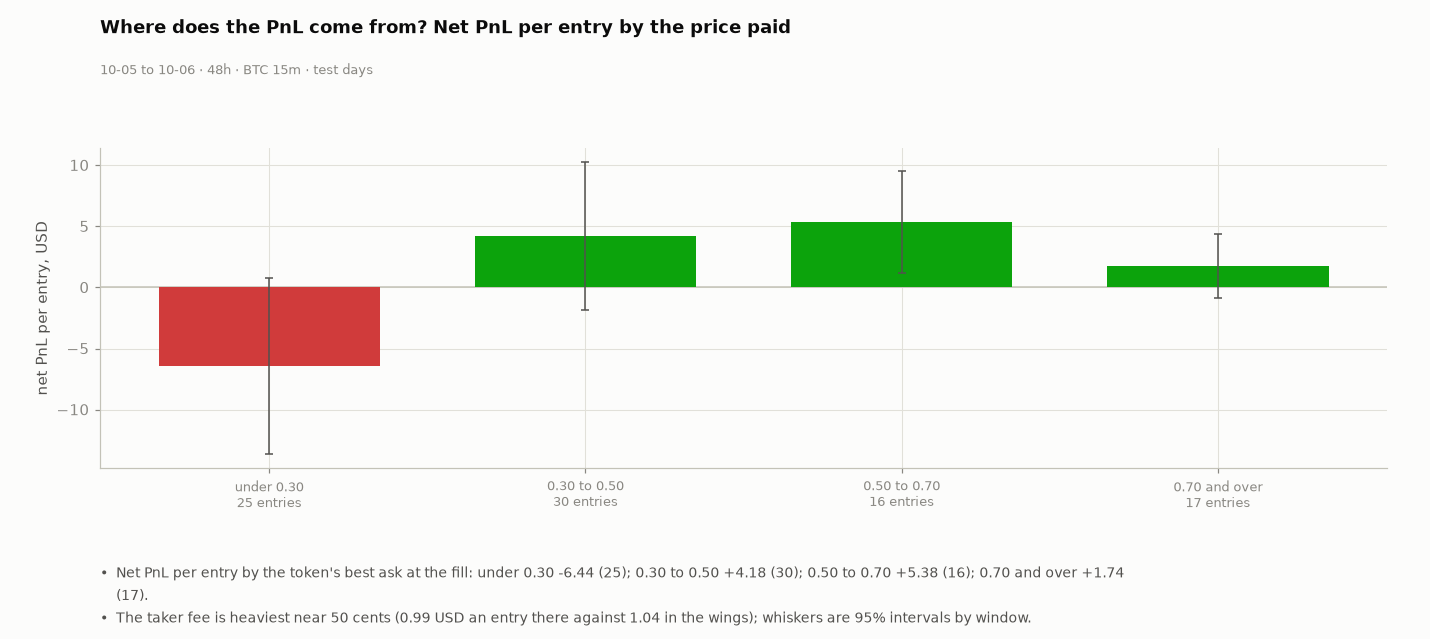

In [64]:
_b = pd.cut(TE.ask, [0.0, 0.3, 0.5, 0.7, 1.0001], labels=["under 0.30", "0.30 to 0.50", "0.50 to 0.70", "0.70 and over"], right=False)
BUCKET = TE.groupby(_b, observed=True).apply(lambda d: pd.Series(dict(BT.summarize(d), ci_lo=BT.cluster_ci(d, reps=800)[1], ci_hi=BT.cluster_ci(d, reps=800)[2])), include_groups=False)
display(Markdown("**By the token's best ask at the fill, test days**\n\n| Ask | Entries | Win | Net per entry | 95% by window | Fees per entry |\n|---|---|---|---|---|---|\n" +
                 "\n".join(f"| {k_} | {int(r.n)} | {pct(r.win)} | {r.per_entry:+.2f} | {r.ci_lo:+.2f} to {r.ci_hi:+.2f} | {r.fees / r.n:.2f} |" for k_, r in BUCKET.iterrows())))
_cost = TE.assign(spread_half_c=TE.spread / 2 * 100, slip_c=(TE.vwap - TE.ask) * 100, fee_c=(TE.fee_in + TE.fee_out) / TE.shares * 100)
display(Markdown(f"**Cost of a fill, cents a share, test days:** half the quoted spread {_cost.spread_half_c.mean():.2f}, depth slippage beyond the best ask {_cost.slip_c.mean():.2f}, taker fee (in plus out) {_cost.fee_c.mean():.2f}; the lag read of S2 put the Up mid {LAG_CENTS_ALL:+.2f} cents in the signal's direction between +150 ms and +1150 ms."))
_x = TE.assign(left_bin=pd.cut(TE.left_s, [0, 60, 180, 420, 901], labels=["last minute", "1 to 3 min", "3 to 7 min", "7 to 15 min"]))
display(Markdown("**By time left at the signal, and by exit, test days**\n\n| Group | Entries | Win | Net per entry |\n|---|---|---|---|\n" +
                 "\n".join(f"| {k_} | {int(r.n)} | {pct(r.win)} | {r.per_entry:+.2f} |" for k_, r in _x.groupby("left_bin", observed=True).apply(lambda d: pd.Series(BT.summarize(d)), include_groups=False).iterrows()) + "\n" +
                 "\n".join(f"| exit {k_} | {int(r.n)} | {pct(r.win)} | {r.per_entry:+.2f} |" for k_, r in TE.groupby("exit").apply(lambda d: pd.Series(BT.summarize(d)), include_groups=False).iterrows())))
_bul = [f"Net PnL per entry by the token's best ask at the fill: " + "; ".join(f"{k_} {r.per_entry:+.2f} ({int(r.n)})" for k_, r in BUCKET.iterrows()) + ".",
        f"The taker fee is heaviest near 50 cents ({float(TE[(TE.ask >= 0.4) & (TE.ask < 0.6)].pipe(lambda d: (d.fee_in + d.fee_out).sum() / max(len(d), 1))):.2f} USD an entry there against {float(TE[(TE.ask < 0.3) | (TE.ask >= 0.7)].pipe(lambda d: (d.fee_in + d.fee_out).sum() / max(len(d), 1))):.2f} in the wings); whiskers are 95% intervals by window."]
fig, ax = FG.frame(3.7, _bul, "Where does the PnL come from? Net PnL per entry by the price paid", WIN_PM_TEST)
a = ax[0]
x = np.arange(len(BUCKET))
FG.signbar(a, x, BUCKET.per_entry, (BUCKET.ci_hi - BUCKET.ci_lo) / 3.92)
FG.zero(a)
a.set_xticks(x); a.set_xticklabels([f"{k_}\n{int(r.n)} entries" for k_, r in BUCKET.iterrows()], fontsize=8.5); a.set_ylabel("net PnL per entry, USD")
figstyle.show(fig, "fig:s5-price", FIGURES)

In [65]:
_fee_pe = TS["fees"] / TS["n"]
ANS6.update(Markdown(f"**{'We lose' if TS['per_entry'] < 0 else 'We do not lose on the point estimate'}: before the fee an entry makes {sgn(TS['gross_per_entry'], 2)} USD, the fee takes {_fee_pe:.2f} and the spread is {TS['spread'] * 100:.1f} cents a share, so the net is {sgn(TS['per_entry'], 2)} USD an entry** ({WIN_PM_TEST})"
                     + ("." if TS["per_entry"] < 0 else f"; the gain has a 95% range of {sgn(CI_LO, 2)} to {sgn(CI_HI, 2)} by window, which is why it is not yet a gain we can bank.")))

## S6 · Decision

| question | decision rule |
|---|---|
| If it passed: what size, can it be filled, what are the limits? | the pack is sized only if the Binance side is PREDICTIVE (Part A's rule) and the chosen configuration earns above zero with an interval above zero, beats other sides, sees a planted peek and pays at 150 ms; otherwise the rung prints as information only (the rule is wired: `SIZED`) |

In [66]:
# ---- the Binance verdict by Part A's rule: the core gates all PASS and at least one pre-registered hypothesis is confirmed ----
GV_ = {g_["id"]: g_["verdict"] for g_ in GATES}
CORE = ("G1", "G2", "G12", "G13", "G16", "G21")
CONFIRMED = [h_ for h_, gid in (("H1", "G5"), ("H2", "G6"), ("H3", "G7"), ("H5", "G9")) if GV_[gid] == "PASS"]
FAIL_CORE = [gid for gid in CORE if GV_[gid] != "PASS"]
BIN_WORD = "PREDICTIVE" if (not FAIL_CORE and CONFIRMED) else "NOT CONFIRMED"
print("Binance side:", BIN_WORD, "| core gates failing:", FAIL_CORE, "| confirmed hypotheses:", CONFIRMED)
# ---- the decision rule of Part B, which now also reads the Binance verdict (a stricter rule than um-004 registered: it can only turn a size into NO SIZE) ----
SIZED = BIN_WORD == "PREDICTIVE" and all(GV_[gid] == "PASS" for gid in ("G11", "G18", "G20")) and GV_["G19"] in ("PASS", "FLAG")
WORD = "1x" if SIZED else "NO SIZE"
CLASS = "A" if SIZED else ("B" if BIN_WORD == "PREDICTIVE" else "C")
CLASS_TXT = {"A": "strong, latency-surviving and monetisable", "B": "predictive on Binance and surviving the delay in basis points, but too small or too slow for Polymarket's costs", "C": "no robust signal"}[CLASS]
_gf = [g_["label"] for g_ in GATES if g_["id"] in ("G11", "G18", "G19", "G20") and g_["verdict"] == "FAIL"]
display(Markdown(f"**Decision: {'a USD 20 clip, one position at a time, paper only' if SIZED else 'NO SIZE'}.** " + ("Every gate of the rule passed." if SIZED else f"Not passed: {', '.join(_gf) or ('the Binance side is ' + BIN_WORD if BIN_WORD != 'PREDICTIVE' else 'none failed outright; the interval or a flag did not clear')}. The rung is information only: USD {CLIP_USD:g} a trade on the USD {BOOK_USD:,.0f} book returned {sgn(TS['net'], 0)} USD on the test days.")))
GATES.append({"id": "G22", "section": "S6", "label": "Sized only if passed", "name": "the decision rule reads the Binance verdict and G11, G18, G19 and G20: a size only when all hold, else the rung is information only",
              "reading": f"{'SIZED' if SIZED else 'NO SIZE'}: Binance {BIN_WORD}; net per entry {sgn(TS['per_entry'], 2)} USD, interval {sgn(CI_LO, 2)} to {sgn(CI_HI, 2)}", "verdict": "PASS" if SIZED else "FAIL",
              "would_change": "any of the gates it reads, or a Binance verdict other than PREDICTIVE"})

Binance side: PREDICTIVE | core gates failing: [] | confirmed hypotheses: ['H1', 'H3', 'H5']


**Decision: NO SIZE.** Not passed: Net per entry above 0. The rung is information only: USD 20 a trade on the USD 1,000 book returned +80 USD on the test days.

## S7 · Verdict - Is it worth trading?

The headline findings come first in plain words, then the gates, the eight answers and the manifest, all rendered from the run's own objects.

In [67]:
ANS7 = display(Markdown("_The answer is written here when the run reaches the verdict._"), display_id=True)

**No: NO SIZE, class B.** The Binance trade price is predictive on BTC's next move, but the chosen Polymarket configuration earns +0.91 USD an entry on 88 test entries (10-05 to 10-06 · 48h · BTC 15m · test days), 95% by window -2.24 to +4.05, and fails Net per entry above 0.

In [68]:
# ---- the headline findings in plain prose, built from the run's own objects (numbers are read, never typed) ----
_L = LT[LT.L_ms == LAT_BAR_MS].set_index("h_s")
_L0 = LT[LT.L_ms == 0].set_index("h_s")
_pkd = DAILY[DAILY.hyp == PACK]
_a_ev = STATE["gbm"]["ev"]
_a_ev = _a_ev[_a_ev.rows == "all"].iloc[0]
_h4 = FAM_TEST[(FAM_TEST.hyp == "H4") & (FAM_TEST.h_s == 5.0)].iloc[0]
_ac = ASSET[(ASSET.h_s == 5.0) & (ASSET.hyp == "H1")].set_index("asset").edge_bp
_conf = [h_ for h_ in ("H1", "H3", "H5") if DEC.get(h_) == "CONFIRMED"]
_lp = LATS.set_index("L")
_bin_sent = ("predicts what BTC does over the next seconds and minutes, and the prediction survives a " + f"{LAT_BAR_MS} ms delay") if BIN_WORD == "PREDICTIVE" else "does not robustly predict what BTC does next"
_pm_sent = ("does not pay enough to size" if not SIZED else "pays: every gate of the decision rule passed")
HEADLINE_MD = (
    f"**The answer: {WORD}, class {CLASS}.** The Binance BTCUSDT trade price alone, using nothing but trades up to the instant, {_bin_sent}. Trading that signal on Polymarket's 15-minute BTC Up/Down books {_pm_sent}: "
    f"the one configuration chosen on the validation days earned {sgn(TS['per_entry'], 2)} USD an entry on the {TS['n']} test-day entries (95% by window {sgn(CI_LO, 2)} to {sgn(CI_HI, 2)}), {sgn(TS['net'], 0)} USD net after the fee, "
    f"{sgn(float(_lp.loc[LAT_MS, 'per_entry']), 2)} an entry at the {LAT_MS} ms delay against {sgn(float(_lp.loc[0, 'per_entry']), 2)} with no delay and {sgn(float(_lp.loc[250, 'per_entry']), 2)} at 250 ms.\n\n"
    f"**On Binance.** When the last second of price moved by at least one second-volatility, going the same way for the next five seconds earned {_L.loc[5.0, 'edge_bp']:+.2f} bp on the two test days (t {_L.loc[5.0, 't']:.0f}; {pct(_L.loc[5.0, 'win_share'], 0)} of the moves that happened went on), "
    f"positive on {int((_pkd.edge_bp > 0).sum())} of {len(_pkd)} days, and trading {LAT_BAR_MS} ms late keeps {pct(_L.loc[5.0, 'edge_bp'] / _L0.loc[5.0, 'edge_bp'], 0)} of the no-delay edge. "
    f"It is momentum, not mean reversion: {', '.join(_conf)} were confirmed on the validation days and again on the test days, and trading against a move of four volatilities or more loses ({_h4.edge_bp:+.2f} bp at 5 s). "
    f"The drift builds for about a minute, peaks near {float(_L.edge_bp.idxmax()):g} s at {_L.edge_bp.max():+.2f} bp, and gives some back by five minutes. It is not a property of every coin (in the same bursts ETH earns {_ac.get('eth', float('nan')):+.2f} bp, SOL {_ac.get('sol', float('nan')):+.2f} and XRP {_ac.get('xrp', float('nan')):+.2f}) "
    f"and it adds nothing to the odds the window ends Up beyond where the window already stands: {_a_ev.mean_abs_lift * 100:.2f} points on average, {_a_ev.gain:+.5f} log loss (95% {_a_ev.lo:+.5f} to {_a_ev.hi:+.5f}).\n\n"
    f"**On Polymarket.** The book follows Binance: {np.nanmean(LG_ALL['mid'][:, _o(150)]) * 100:+.2f} cents of the Up mid in the signal's direction by +150 ms and {np.nanmean(LG_ALL['mid'][:, _o(1000)]) * 100:+.2f} by +1 s, "
    f"so an order that meets the book at {LAT_MS} ms arrives just before most of the move and pays the spread and the fee for it. Random sides at the same moments earn {RAND_PE.mean():+.2f} an entry ({int((RAND_PE >= REAL_PE).sum())} of {len(RAND_PE)} draws at or above the pack), "
    f"the planted peek earns {PEEK.per_entry:+.2f}, so the harness would see a leak.\n\n"
    f"**How far to trust it.** Seven days of one regime, two test days read once, the Polymarket days those of `um-003`: one window, not an independent observation. {N_TOTAL:,} tests were run in all, of which only the pre-registered family and the registered grid carry a bar. "
    f"The move is a few tenths of a basis point collected in bursts, so it is worth money only where a price follows Binance late and cheaply."
)
display(Markdown(HEADLINE_MD))

**The answer: NO SIZE, class B.** The Binance BTCUSDT trade price alone, using nothing but trades up to the instant, predicts what BTC does over the next seconds and minutes, and the prediction survives a 150 ms delay. Trading that signal on Polymarket's 15-minute BTC Up/Down books does not pay enough to size: the one configuration chosen on the validation days earned +0.91 USD an entry on the 88 test-day entries (95% by window -2.24 to +4.05), +80 USD net after the fee, +0.91 an entry at the 150 ms delay against +4.48 with no delay and -1.78 at 250 ms.

**On Binance.** When the last second of price moved by at least one second-volatility, going the same way for the next five seconds earned +0.41 bp on the two test days (t 34; 72% of the moves that happened went on), positive on 7 of 7 days, and trading 150 ms late keeps 96% of the no-delay edge. It is momentum, not mean reversion: H1, H3, H5 were confirmed on the validation days and again on the test days, and trading against a move of four volatilities or more loses (-0.37 bp at 5 s). The drift builds for about a minute, peaks near 120 s at +0.70 bp, and gives some back by five minutes. It is not a property of every coin (in the same bursts ETH earns +0.26 bp, SOL -0.13 and XRP +0.04) and it adds nothing to the odds the window ends Up beyond where the window already stands: 0.04 points on average, -0.00000 log loss (95% -0.00006 to +0.00005).

**On Polymarket.** The book follows Binance: +0.55 cents of the Up mid in the signal's direction by +150 ms and +3.16 by +1 s, so an order that meets the book at 150 ms arrives just before most of the move and pays the spread and the fee for it. Random sides at the same moments earn -3.45 an entry (0 of 200 draws at or above the pack), the planted peek earns +3.89, so the harness would see a leak.

**How far to trust it.** Seven days of one regime, two test days read once, the Polymarket days those of `um-003`: one window, not an independent observation. 1,860 tests were run in all, of which only the pre-registered family and the registered grid carry a bar. The move is a few tenths of a basis point collected in bursts, so it is worth money only where a price follows Binance late and cheaply.

In [69]:
ANS7_TXT = (f"**{'Yes' if SIZED else 'No'}: {WORD}, class {CLASS}.** The Binance trade price is {BIN_WORD.lower()} on BTC's next move, but the chosen Polymarket configuration earns {sgn(TS['per_entry'], 2)} USD an entry on {TS['n']} test entries ({WIN_PM_TEST}), 95% by window {sgn(CI_LO, 2)} to {sgn(CI_HI, 2)}"
            + ("." if SIZED else (f", and fails {', '.join(_gf)}." if _gf else ", and the interval or a flag does not clear the rule.")))
ANS7.update(Markdown(ANS7_TXT)); ANS0.update(Markdown(ANS7_TXT))

In [70]:
# ---- GATES as data; the table, S0 and the manifest render from it ----
for g_ in GATES:
    assert g_["verdict"] in REPORT.GATE_VERDICTS, g_
    assert len(g_["label"]) <= REPORT.MAX_GATE_LABEL, (g_["label"], len(g_["label"]))
assert len({g_["id"] for g_ in GATES}) == len(GATES), "a gate id is used twice"
GATES.sort(key=lambda g_: int(g_["id"][1:]))                     # reading order is id order: the delay gates now run before the equity gate
GV = {g_["id"]: g_["verdict"] for g_ in GATES}
GID = {g_["label"]: g_["id"] for g_ in GATES}
display(Markdown("**Gates**\n\n| Id | Section | Gate | Reading | Verdict |\n|---|---|---|---|---|\n" + "\n".join(f"| {g_['id']} | {g_['section']} | {g_['label']} | {g_['reading']} | **{g_['verdict']}** |" for g_ in GATES)))
FAIL_IDS = [g_["id"] for g_ in GATES if g_["verdict"] == "FAIL"]
print("Binance side:", BIN_WORD, "| decision:", WORD, "| class:", CLASS, "| failing gates:", FAIL_IDS)

**Gates**

| Id | Section | Gate | Reading | Verdict |
|---|---|---|---|---|
| G1 | S2 | Tape and reference match | 100.00% of 75,600 seconds equal the candle close; the stand-in agrees on 98.1% of 672 windows | **PASS** |
| G2 | S2 | No look-ahead | 60 of 60 instants equal; planted future read caught 60 of 60 | **PASS** |
| G3 | S2 | Pack is the signal | 210,743 instants equal (largest difference 3.1e-05); engine cases 9 of 9 | **PASS** |
| G4 | S2 | Windows have a book | 192 of 192 windows (100.0%) | **PASS** |
| G5 | S3 | Momentum continues | test edge +0.13 / +0.41 / +0.54 bp at 1 / 5 / 10 s, t +37 / +34 / +28; validation t +16 / +16 / +17 | **PASS** |
| G6 | S3 | Acceleration adds | test edge +0.10 / +0.29 / +0.36 bp at 1 / 5 / 10 s, t +14 / +10 / +7; validation t +4 / +3 / +4 | **FAIL** |
| G7 | S3 | Breakouts continue | test edge +0.12 / +0.39 / +0.52 bp at 1 / 5 / 10 s, t +46 / +37 / +28; validation t +21 / +20 / +17 | **PASS** |
| G8 | S3 | Extremes reverse | test edge -0.13 / -0.37 / -0.50 bp at 1 / 5 / 10 s, t -15 / -16 / -13; validation t -7 / -8 / -9 | **FAIL** |
| G9 | S3 | Horizons agree | test edge +0.10 / +0.33 / +0.44 bp at 1 / 5 / 10 s, t +46 / +36 / +28; validation t +20 / +19 / +16 | **PASS** |
| G10 | S3 | Momentum in every vol | H6 low vol confirmed; H6 mid vol confirmed; H6 high vol confirmed | **PASS** |
| G11 | S3 | Net per entry above 0 | +0.91 USD per entry on 88 entries, 95% -2.24 to +4.05 | **FAIL** |
| G12 | S4 | Survives 150 ms | t +37 / +34 / +28; share of the no-delay edge kept 97% / 96% / 97% | **PASS** |
| G13 | S4 | Positive every day | 7 of 7 days positive; the weakest day +0.173 bp, t +12.2 | **PASS** |
| G14 | S4 | Models vs the rule | gbm spread +0.953 bp (t +36) against +0.817 bp (t +34) for H1; 1.17 times | **INFO** |
| G15 | S4 | Adds to the window | gain -0.00000, 95% -0.00006 to +0.00005; mean absolute change 0.04 points | **FAIL** |
| G16 | S4 | Beats the placebo | +27.8 placebo standard deviations; planted lookahead dose response ordered; planted leak flagged | **PASS** |
| G17 | S4 | Other coins agree | 6 of 9 coin-hypothesis pairs hold at every hold | **FLAG** |
| G18 | S4 | Beats other sides | pack +0.91, reversed -8.39, random mean -3.45 (0 of 200 draws at or above, p 0.005) | **PASS** |
| G19 | S4 | Planted peek is seen | peek +3.89, pack +0.91, stale -0.82 USD per entry | **PASS** |
| G20 | S4 | Pays at 150 ms | +0.91 at 150 ms, -2.17 at 400 ms, +4.48 at no delay | **PASS** |
| G21 | S5 | Earned per episode | 9,634 episodes, edge +0.506 bp per episode, t +39.7, win share 75.4% | **PASS** |
| G22 | S6 | Sized only if passed | NO SIZE: Binance PREDICTIVE; net per entry +0.91 USD, interval -2.24 to +4.05 | **FAIL** |

Binance side: PREDICTIVE | decision: NO SIZE | class: B | failing gates: ['G6', 'G8', 'G11', 'G15', 'G22']


In [71]:
# ---- the eight answers, from the run's own numbers ----
def row_of(tab, h_):
    return tab[(tab.L_ms == LAT_BAR_MS) & (tab.h_s == h_)].iloc[0]
_p5 = row_of(LT, 5.0); _p0 = LT[(LT.L_ms == 0) & (LT.h_s == 5.0)].iloc[0]
_win_by_h = LT[LT.L_ms == LAT_BAR_MS].set_index("h_s").win_share
_hpeak = float(_win_by_h.idxmax())
_edge_by_h = LT[LT.L_ms == LAT_BAR_MS].set_index("h_s").edge_bp
_gbm5 = MODEL_TAB[(MODEL_TAB.name == "gbm") & (MODEL_TAB.h_s == 5.0)].iloc[0]
_rev = FAM_TEST[(FAM_TEST.hyp == "H4") & (FAM_TEST.h_s == 5.0)].iloc[0]
_days_pos = int((_pk.edge_bp > 0).sum())
_lat_pm = LATS.set_index("L")
_pe150 = float(_lat_pm.loc[150, "per_entry"]); _pe0 = float(_lat_pm.loc[0, "per_entry"])
# the pack on the window question: how often is the state already pointing the same way when the signal fires
_xs = np.where(X_PACK[PACK][1], np.sign(X_PACK[PACK][0]), 0.0)
_fr = A.state_frame(TEST, _xs, A.window_rows(TEST))
_on = _fr.z_drift != 0
_agree = float(np.average(np.sign(_fr.z_state[_on]) == np.sign(_fr.z_drift[_on]), weights=_fr.w[_on]))
FORMULA = {
    "H1": "z = ln(p_t / p_(t-1 s)) / s, where p is the last Binance trade price and s the standard deviation of one-second log returns over the 540 s ending 60 s before t; when |z| >= 1 go with the sign of z",
    "H2": "d = slope of the last 5 s (least squares on one-second prices) minus the slope of the last 30 s; when |d| is in the top fifth of the fit days go with the sign of d",
    "H3": "b = (p_t - highest price of the last 10 s) or (p_t - lowest) when p_t breaks either, over s * sqrt(10); when b is not zero go with its sign",
    "H5": "the returns over 1, 3, 5 and 10 s all have the same sign; go with it",
}
_ev_all = STATE["gbm"]["ev"][STATE["gbm"]["ev"].rows == "all"].iloc[0]
ANS = [
    ("1. Does Binance price alone robustly predict the next few seconds?",
     f"Yes, in the sense of a measured drift, not a fortune. {PACK_NAME} earns {_p5.edge_bp:+.3f} bp over a 5 s hold on the test days (t {_p5.t:+.0f}, win share {pct(_p5.win_share)}), positive on {_days_pos} of {len(_pk)} days, and the best price-only model reaches a correlation of {_gbm5.rho:+.3f} against the return held 5 s."),
    ("2. Momentum or mean reversion?",
     f"Momentum. {', '.join(CONFIRMED)} hold on the validation and the test days; trading AGAINST a move of four volatilities or more earns {_rev.edge_bp:+.3f} bp at 5 s (t {_rev.t:+.0f}). The bigger the move the less reliably it goes on, but it does not reverse on average."),
    ("3. The strongest simple signal, exact formula?", f"{PACK_NAME}: {FORMULA[PACK]}. Entered 150 ms after the instant, it earns {_p5.edge_bp:+.3f} bp at 5 s, {row_of(LT, 60.0).edge_bp:+.3f} bp at 60 s and {row_of(LT, 300.0).edge_bp:+.3f} bp at 300 s. The Polymarket trade is the first row of an H1 burst (bursts of one sign closer than {EPISODE_GAP_MS / 1000:g} s are one)."),
    ("4. How long does it survive?",
     f"As a BTC drift it builds for about a minute: the edge is {sgn(float(_edge_by_h.loc[1.0]), 3)} bp at 1 s, {sgn(float(_edge_by_h.loc[10.0]), 3)} at 10 s, {sgn(float(_edge_by_h.loc[60.0]), 3)} at 60 s and peaks at {float(_edge_by_h.idxmax()):g} s ({sgn(float(_edge_by_h.max()), 3)} bp), then gives back to {sgn(float(_edge_by_h.loc[300.0]), 3)} at 300 s; the win share is highest at a hold of {_hpeak:g} s ({pct(float(_win_by_h.loc[_hpeak]))}). As a Polymarket quote it survives only until the book catches up: the Up mid has covered most of the move by about half a second (S2), so the price of a late order is the whole story (S4)."),
    ("5. Does it survive 150 ms?",
     f"In basis points of BTC yes: at 150 ms the 5 s edge is {_p5.edge_bp:+.3f} bp against {_p0.edge_bp:+.3f} bp at no delay ({pct(_p5.edge_bp / _p0.edge_bp, 0)} kept, t {_p5.t:+.0f}). On Polymarket the chosen configuration earns {_pe150:+.2f} USD per entry at 150 ms against {_pe0:+.2f} with no delay and {float(_lat_pm.loc[400, 'per_entry']):+.2f} at 400 ms."),
    ("6. Positive EV after Polymarket fees, spread and delay?",
     f"{'Yes on the test days' if (CI_LO > 0) else ('Not shown' if TS['per_entry'] > 0 else 'No')}: {TS['n']} entries, {sgn(TS['per_entry'], 2)} USD per entry (95% by window {sgn(CI_LO, 2)} to {sgn(CI_HI, 2)}), {sgn(TS['net'], 0)} USD net; before the fee {sgn(TS['gross_per_entry'], 2)} per entry. The book follows Binance with a lag: by +150 ms the Up mid has moved {np.nanmean(LG_ALL['mid'][:, _o(150)]) * 100:+.2f} cents in the signal's direction, by +1 s {np.nanmean(LG_ALL['mid'][:, _o(1000)]) * 100:+.2f}; an order at 150 ms meets it just before most of the move, one at 250 ms nets {float(_lat_pm.loc[250, 'per_entry']):+.2f} per entry. {'The decision rule sizes it.' if SIZED else 'NO SIZE: the rule did not pass.'}"),
    ("7. Does it generalise across days?",
     f"The drift does: {PACK_NAME} is positive on {_days_pos} of {len(_pk)} days, and the other three coins agree on {_n_ok} of 9 coin-hypothesis pairs. The chosen Polymarket trade, per entry by day: " + "; ".join(f"{d_[5:]} {r_.per_entry:+.2f}" for d_, r_ in _bt_days.iterrows()) + " USD. All seven days are one regime (one week, no crash, no halt), so this is one observation of the regime, and two test days are not a generalisation."),
    ("8. Is it new against the current fair-value model?",
     f"Yes as an object: it is a forecast of the next move, not the window's state. When it fires the window's own state points the same way only {pct(_agree, 0)} of the time, and on the probability the window ends Up it adds {_ev_all.gain:+.5f} log loss over the state alone (95% {_ev_all.lo:+.5f} to {_ev_all.hi:+.5f}). The Polymarket result is a different bet from `um-003`'s (hold to expiry on a fair-value edge, NO SIZE), on the same days."),
]
display(Markdown("**The eight answers**\n\n" + "\n\n".join(f"**{q_}** {a_}" for q_, a_ in ANS)))
display(Markdown(f"**Conclusion: {CLASS}** ({CLASS_TXT}). " + {"A": "The pack passes every gate of the decision rule on the test days.", "B": "Binance price dynamics hold a real signal that survives 150 ms in basis points; on Polymarket the chosen configuration's interval does not clear zero after the fee, spread and fill (G11), so nothing is sized.", "C": "The Binance side did not confirm a signal."}[CLASS]))
RESULT_LINES = [f"RESULT um-004 test_entries={TS['n']}", f"RESULT um-004 test_win_rate_pct={TS['win'] * 100:.2f}", f"RESULT um-004 test_net_per_entry_usd={TS['per_entry']:.4f}", f"RESULT um-004 test_net_pnl_usd={TS['net']:.2f}", f"RESULT um-004 lag_mid_move_cents={LAG_CENTS_ALL:.4f}"]
print("\n".join(l_.replace("RESULT um-004 ", "") for l_ in RESULT_LINES))

**The eight answers**

**1. Does Binance price alone robustly predict the next few seconds?** Yes, in the sense of a measured drift, not a fortune. H1 momentum earns +0.409 bp over a 5 s hold on the test days (t +34, win share 71.7%), positive on 7 of 7 days, and the best price-only model reaches a correlation of +0.214 against the return held 5 s.

**2. Momentum or mean reversion?** Momentum. H1, H3, H5 hold on the validation and the test days; trading AGAINST a move of four volatilities or more earns -0.369 bp at 5 s (t -16). The bigger the move the less reliably it goes on, but it does not reverse on average.

**3. The strongest simple signal, exact formula?** H1 momentum: z = ln(p_t / p_(t-1 s)) / s, where p is the last Binance trade price and s the standard deviation of one-second log returns over the 540 s ending 60 s before t; when |z| >= 1 go with the sign of z. Entered 150 ms after the instant, it earns +0.409 bp at 5 s, +0.674 bp at 60 s and +0.469 bp at 300 s. The Polymarket trade is the first row of an H1 burst (bursts of one sign closer than 5 s are one).

**4. How long does it survive?** As a BTC drift it builds for about a minute: the edge is +0.135 bp at 1 s, +0.544 at 10 s, +0.674 at 60 s and peaks at 120 s (+0.695 bp), then gives back to +0.469 at 300 s; the win share is highest at a hold of 5 s (71.7%). As a Polymarket quote it survives only until the book catches up: the Up mid has covered most of the move by about half a second (S2), so the price of a late order is the whole story (S4).

**5. Does it survive 150 ms?** In basis points of BTC yes: at 150 ms the 5 s edge is +0.409 bp against +0.426 bp at no delay (96% kept, t +34). On Polymarket the chosen configuration earns +0.91 USD per entry at 150 ms against +4.48 with no delay and -2.17 at 400 ms.

**6. Positive EV after Polymarket fees, spread and delay?** Not shown: 88 entries, +0.91 USD per entry (95% by window -2.24 to +4.05), +80 USD net; before the fee +1.97 per entry. The book follows Binance with a lag: by +150 ms the Up mid has moved +0.55 cents in the signal's direction, by +1 s +3.16; an order at 150 ms meets it just before most of the move, one at 250 ms nets -1.78 per entry. NO SIZE: the rule did not pass.

**7. Does it generalise across days?** The drift does: H1 momentum is positive on 7 of 7 days, and the other three coins agree on 6 of 9 coin-hypothesis pairs. The chosen Polymarket trade, per entry by day: 10-03 +6.97; 10-04 +5.72; 10-05 -0.02; 10-06 +1.76 USD. All seven days are one regime (one week, no crash, no halt), so this is one observation of the regime, and two test days are not a generalisation.

**8. Is it new against the current fair-value model?** Yes as an object: it is a forecast of the next move, not the window's state. When it fires the window's own state points the same way only 56% of the time, and on the probability the window ends Up it adds -0.00000 log loss over the state alone (95% -0.00006 to +0.00005). The Polymarket result is a different bet from `um-003`'s (hold to expiry on a fair-value edge, NO SIZE), on the same days.

**Conclusion: B** (predictive on Binance and surviving the delay in basis points, but too small or too slow for Polymarket's costs). Binance price dynamics hold a real signal that survives 150 ms in basis points; on Polymarket the chosen configuration's interval does not clear zero after the fee, spread and fill (G11), so nothing is sized.

test_entries=88
test_win_rate_pct=55.68
test_net_per_entry_usd=0.9110
test_net_pnl_usd=80.16
lag_mid_move_cents=2.6301


In [72]:
# ---- the card and the verdict (directional format, systematic style) ----
_cut = lambda s, n: s if len(s) <= n else s[: n - 1].rstrip() + "."
mk = lambda metric, value, bar="", verdict="", gate=None: {"metric": metric, "value": value, "bar": bar, "verdict": GV[gate] if gate else verdict, **({"gate": gate} if gate else {})}
_dly = TE.groupby("day").net.sum()
_worst_day = float(_dly.min()) if len(_dly) else 0.0
_wins, _loss = TE[TE.net > 0].net, TE[TE.net <= 0].net
PF = float(_wins.sum() / abs(_loss.sum())) if len(_loss) and _loss.sum() != 0 else None
WLR = float(_wins.mean() / abs(_loss.mean())) if len(_wins) and len(_loss) else None
HOLD_H = float(((TE.left_s if CHOSEN.exit == "hold" else pd.Series([CHOSEN.hold_s + 2 * LAT_MS / 1000] * len(TE))).mean()) / 3600.0) if len(TE) else None
DD_USD = _dd
METRICS = {"ann_return_pct": None, "excess_vs_hurdle_pct": None, "ann_vol_pct": None, "sharpe": None, "sortino": None, "calmar": None, "psr": None, "dsr": None,
           "max_dd_pct": DD_USD / BOOK_USD * 100, "max_dd_days": float(len(TEST_DAYS)), "n_periods": float(len(TEST_DAYS)), "periods_per_year": 365.0,
           "total_return_pct": TS["net"] / BOOK_USD * 100, "n_trades": float(TS["n"]), "trades_per_day": TS["n"] / len(TEST_DAYS), "hit_rate_pct": TS["win"] * 100 if TS["n"] else None,
           "profit_factor": PF, "expectancy_bps": TS["per_entry"] / CLIP_USD * 1e4 if TS["n"] else None, "win_loss_ratio": WLR, "avg_hold_h": HOLD_H, "exposure_pct": None,
           "turnover_ann": float(TE.cost.sum() / len(TEST_DAYS) * 365 / BOOK_USD) if len(TE) else None, "fees_pct_of_gross": float(TS["fees"] / abs(TS["gross"]) * 100) if TS["gross"] else None,
           "worst_period_pct": _worst_day / BOOK_USD * 100, "gross_edge_bps": TS["gross_per_entry"] / CLIP_USD * 1e4 if TS["n"] else None, "cost_bps": TS["fees"] / max(TS["n"], 1) / CLIP_USD * 1e4,
           "breakeven_cost_bps": TS["gross_per_entry"] / CLIP_USD * 1e4 if TS["n"] else None, "capacity_usd": None, "beta_to_underlying": None}
NA = {k_: "two test days: an annualised or daily-return ratio is not meaningful" for k_ in ("ann_return_pct", "excess_vs_hurdle_pct", "ann_vol_pct", "sharpe", "sortino", "calmar", "psr", "dsr")}
NA["exposure_pct"] = "exposure over the window was not tracked per second"
NA["capacity_usd"] = "the ladder depth at each fill is not kept beyond the clip"
NA["beta_to_underlying"] = "a binary payoff on Up or Down: no single underlying beta"
for k_, v_ in list(METRICS.items()):
    if v_ is None or (isinstance(v_, float) and not math.isfinite(v_)):
        METRICS[k_] = None
        NA.setdefault(k_, "no entry or no loss on the test days")
VERDICT = {"word": WORD, "why": [_cut(f"net {sgn(TS['per_entry'], 2)} USD per entry on {TS['n']} test entries, 95% by window {sgn(CI_LO, 2)} to {sgn(CI_HI, 2)}", 110),
                                 _cut(f"Binance {BIN_WORD}: {_p5.edge_bp:+.2f} bp over 5 s at 150 ms, t {_p5.t:+.0f}; {int((RAND_PE >= REAL_PE).sum())} of {len(RAND_PE)} random-side draws earn as much", 110),
                                 _cut(f"{_pe150:+.2f} USD per entry at 150 ms, {_pe0:+.2f} with no delay", 110)] if not SIZED else [_cut(f"every gate of the decision rule passed on {TS['n']} test entries", 110)],
           "next_bet": _cut("the same pack on ETH, SOL and XRP books and on fresh days; net per entry above zero with an interval above zero", 150)}
CARD = {
    "question": _cut("Does the Binance trade price predict BTC's next move, and does the signal pay on Polymarket's 15-minute Up/Down after the fee, the spread and a 150 ms delay?", 200),
    "answer": _cut(f"{WORD}, class {CLASS}. Binance {BIN_WORD}: {_p5.edge_bp:+.2f} bp over 5 s at 150 ms (t {_p5.t:+.0f}). Polymarket test days: {TS['n']} entries net {sgn(TS['net'], 0)} USD ({sgn(TS['per_entry'], 2)} each, 95% {sgn(CI_LO, 2)} to {sgn(CI_HI, 2)}); the book has covered {pct(float(np.nanmean(LG_ALL['mid'][:, _o(150)]) / np.nanmean(LG_ALL['fair'][:, _o(150)])), 0)} of the Binance-implied move by +150 ms.", 240),
    "implementation": [("Trade", _cut("Buy Up or Down 150 ms after a Binance momentum burst", 70)), ("Venue", "Polymarket 15m BTC Up/Down; Binance trades are input"), ("Rule", _cut(f"z >= {CHOSEN.z0:g}, {'hold' if CHOSEN.exit == 'hold' else f'sell back after {CHOSEN.hold_s:g} s'}, ask {CHOSEN.lo:g} to {CHOSEN.hi:g}", 70)),
                       ("Size", f"{usd(CLIP_USD)} a trade, {usd(BOOK_USD)} book, 1x"), ("Costs", _cut("taker fee 0.07 x p(1-p) [1], ladder walked at +150 ms", 70)), ("Window", f"{DAYS_ALL[0][5:]} to {DAYS_ALL[-1][5:]}, {HOURS_ALL}h, 1 regime")],
    "big": [dict(mk("Binance edge, 150 ms", f"{_p5.edge_bp:+.3f} bp", f"t {_p5.t:.0f}, bar {T_BAR:g}", gate="G12"), scope="test"),
            dict(mk("Net per entry, Polymarket", f"{TS['per_entry']:+.2f} USD", f"95% {CI_LO:+.2f} to {CI_HI:+.2f}", gate="G11"), scope="test"),
            dict(mk("Net after the fee", f"{TS['net']:+,.0f} USD", f"{TS['n']} entries", gate="G11"), scope="test"),
            dict(mk("Pays at 150 ms", f"{_pe150:+.2f} USD", f"no delay {_pe0:+.2f}", gate="G20"), scope="150 ms")],
    "blocks": [
        {"title": "Binance: confirmation", "rows": [mk("Momentum continues", " / ".join(f"{x:+.2f}" for x in FAM_TEST[(FAM_TEST.hyp == "H1")].edge_bp), "bp at 1, 5, 10 s", gate="G5"), mk("Breakouts continue", " / ".join(f"{x:+.2f}" for x in FAM_TEST[(FAM_TEST.hyp == "H3")].edge_bp), "bp at 1, 5, 10 s", gate="G7"),
                                          mk("Horizons agree", " / ".join(f"{x:+.2f}" for x in FAM_TEST[(FAM_TEST.hyp == "H5")].edge_bp), "bp at 1, 5, 10 s", gate="G9"), mk("Extremes reverse", " / ".join(f"{x:+.2f}" for x in FAM_TEST[(FAM_TEST.hyp == "H4")].edge_bp), "bp at 1, 5, 10 s", gate="G8")]},
        {"title": "Binance: delay and days", "rows": [mk("Edge at no delay, held 5 s", f"{_p0.edge_bp:+.3f} bp", "", "INFO"), mk("Share kept at 150 ms", pct(_p5.edge_bp / _p0.edge_bp, 0), "half or more", gate="G12"),
                                           mk("Weakest day", f"{float(_pk.edge_bp.min()):+.3f} bp", "above 0", gate="G13"), mk("Coins that agree", f"{_n_ok} of 9", "all nine", gate="G17")]},
        {"title": "Binance: real and earned", "rows": [mk("Placebo standard deviations", f"{SHUF['z']:.1f}", "above 3", gate="G16"), mk("Look-ahead probes passed", f"{CAUS['equal']} of {CAUS['n']}", "all", gate="G2"),
                                         mk("Edge per episode", f"{_e5.edge_bp:+.3f} bp", "above 0", gate="G21"), mk("Log-loss gain over state", f"{_ev_all.gain:+.5f}", f"{_ev_all.lo:+.4f} to {_ev_all.hi:+.4f}", gate="G15")]},
        {"title": "PnL, USD", "rows": [mk("Before the fee", sgn(TS["gross"], 0), "", "INFO"), mk("Taker fees", usd(TS["fees"]), "", "INFO"), mk("After the fee", sgn(TS["net"], 0), "above 0", gate="G11"), mk("Deepest drawdown", sgn(-DD_USD, 0), f"book {usd(BOOK_USD)}", "INFO"), mk("Worst day", sgn(_worst_day, 0), "", "INFO")]},
        {"title": "Against other sides", "rows": [mk("Random sides, per entry", sgn(float(RAND_PE.mean()), 2), "", "INFO"), mk("Reversed side, per entry", sgn(float(FADE.per_entry), 2), "", "INFO"), mk("Draws at or above the pack", f"{int((RAND_PE >= REAL_PE).sum())} of {len(RAND_PE)}", "under 1 in 20", gate="G18"), mk("Planted peek, per entry", sgn(float(PEEK.per_entry), 2), "pays more", gate="G19")]},
        {"title": "Delay", "rows": [mk("At no delay, per entry", sgn(_pe0, 2), "", "INFO"), mk("At 150 ms, per entry", sgn(_pe150, 2), "above 0", gate="G20"), mk("At 400 ms, per entry", sgn(float(_lat_pm.loc[400, "per_entry"]), 2), "", "INFO"), mk("Net at twice the fee, per entry", sgn(_fee[2][1], 2), "", "INFO")]},
        {"title": "The book's lag", "rows": [mk("Mid move +150 to +1150 ms", f"{LAG_CENTS_ALL:+.2f} cents", "signal direction", "INFO"), mk("Half spread paid", f"{_cost.spread_half_c.mean():.2f} cents", "", "INFO"), mk("Fee a share", f"{_cost.fee_c.mean():.2f} cents", "", "INFO"), mk("Depth slippage", f"{_cost.slip_c.mean():.2f} cents", "", "INFO")]},
        {"title": "Checks", "rows": [mk("Engine cases held", "9 of 9", "all", gate="G3"), mk("Windows with a book", pct(_share, 0), "90% bar", gate="G4"), mk("Tape equals venue candles", pct(KL_SHARE, 2), "all", gate="G1"), mk("Tests run, all families", f"{N_TOTAL:,}", "24 confirmatory", verdict="INFO")]}],
    "sizes": {"cols": ["Size", "Net, USD", "Per entry", "Verdict"], "chosen": 0 if SIZED else None, "rows": [["1x" if SIZED else "1x info only", sgn(TS["net"], 0), sgn(TS["per_entry"], 2), "PASS" if SIZED else "FAIL"]]},
    "footer": [_cut(f"Part B registered as {RUN_ID} before any Polymarket day was scored; {N_TRIALS} trials on two validation days, two test days read once.", 160),
               _cut(f"{PROTO_FROZEN} froze Part A's protocol before the test days; {N_TOTAL:,} tests, only the 24 pre-registered carry a bar.", 160),
               _cut("The Polymarket days are those of um-003: one window, one regime, not an independent observation.", 160),
               _cut(f"{HOURS_ALL}h, {VERIFY['passed']}/{VERIFY['total']} checks; Binance and Polymarket clocks taken as one, no queue, we only lift.", 160)],
}
assert not REPORT.card_problems(CARD, metrics={k_: (None if v_ is None else float(v_)) for k_, v_ in METRICS.items()}, gates={g_["id"]: g_ for g_ in GATES}, word=WORD, carry=False), \
    REPORT.card_problems(CARD, metrics={k_: (None if v_ is None else float(v_)) for k_, v_ in METRICS.items()}, gates={g_["id"]: g_ for g_ in GATES}, word=WORD, carry=False)

In [73]:
# ---- the study manifest fund.study/1 (directional format, systematic style) ----
import hashlib
from fundplat.data.predmkts import updown15_pin
STUDY_GATES = [{k_: g_[k_] for k_ in ("id", "section", "name", "label", "reading", "verdict", "would_change")} for g_ in GATES]
RUN_AT = dt.datetime.now(dt.timezone.utc).strftime("%Y-%m-%dT%H:%MZ")
_inp = A.inputs_block([SYMBOL, "ETHUSDT", "SOLUSDT", "XRPUSDT"], LF.day_ms(DAYS_ALL[0]), LF.day_ms(DAYS_ALL[-1]) + LF.DAY_MS)
_series, _unpinned = list(_inp["series"]), list(_inp["unpinned"])
for d_ in PM_DAYS:
    try:
        ip_ = updown15_pin.input_pin(d_)
        _series.append(dict(spec=f"polymarket:updown15 {d_}:l2-ladders:-", pin=hashlib.sha256(f"updown15-l2:{d_}:{ip_['digest']}".encode()).hexdigest(), rows=int(ip_["rows"]), first_ts=LF.day_ms(d_), last_ts=LF.day_ms(d_) + LF.DAY_MS - 1, handle=None, cls="pin", trunc=False))
    except KeyError as e_:
        _unpinned.append({"what": f"polymarket updown15 ladders {d_}", "why": f"the day is not finalized by the ladder job ({str(e_)[:60]})"})
INPUTS = {"digest": REPORT.inputs_digest([x_["pin"] for x_ in _series]), "series": _series, "unpinned": _unpinned}
PROFILE = {"market": "predmkts", "markets": ["predmkts", "crypto"], "venues": ["polymarket", "binance"], "instruments": ["BTC 15m Up/Down", "BTCUSDT spot trades"], "bar": "15m"}
COMPONENTS = [{"name": "PnL before the fee", "usd": float(TS["gross"])}, {"name": "taker fees", "usd": -float(TS["fees"])}]
assert abs(sum(c_["usd"] for c_ in COMPONENTS) - TS["net"]) < 0.01, "the PnL parts do not add to the net"
FIG_KINDS = {"fig:s2-weighting": "rule-comparison", "fig:s2-lag": "signal-decay", "fig:s3-scan": "signal-and-outcome-scatter", "fig:s3-deciles": "signal-and-outcome-scatter", "fig:s3-shortret": "signal-and-outcome-scatter",
             "fig:s3-continuation": "calibration", "fig:s3-horizon": "signal-decay", "fig:s3-breakout": "calibration", "fig:s3-reversal": "calibration", "fig:s3-volregime": "regime-and-concentration",
             "fig:s3-secleft": "regime-and-concentration", "fig:s3-grid": "parameter-surface", "fig:s3-equity": "equity-curve",
             "fig:s3-latency": "signal-decay", "fig:s4-daily": "out-of-sample-test", "fig:s4-models": "rule-comparison", "fig:s4-state": "significance-test",
             "fig:s4-dose": "significance-test", "fig:s4-assets": "regime-and-concentration", "fig:s4-benchmarks": "rule-comparison", "fig:s3-pm-latency": "signal-decay", "fig:s3-pm-trades": "win-loss-distribution", "fig:s3-pm-pertrade": "equity-curve", "fig:s3-pm-rollwin": "rolling-statistics", "fig:s3-windows": "exposure-over-time", "fig:s4-pm-daily": "out-of-sample-test",
             "fig:s5-concentration": "regime-and-concentration", "fig:s5-price": "regime-and-concentration"}
assert {f_["id"] for f_ in FIGURES} == set(FIG_KINDS), set(FIG_KINDS) ^ {f_["id"] for f_ in FIGURES}
for f_ in FIGURES:
    f_["kind"] = FIG_KINDS[f_["id"]]
CAVEATS = ["seven days, one regime, two test days: one observation of the regime, not a promise",
           "the Polymarket days are those of um-003: one window, not an independent observation",
           f"{N_TRIALS} trials on two validation days: the chosen configuration's validation number is flattered",
           f"the 15-minute reference is a Binance stand-in for the Chainlink TWAP: {pct(TW_SHARE, 0)} agreement with recorded outcomes",
           "prices are trades, not quotes: the one-tick bid-ask bounce sits inside the noise at the holds used",
           "the validation days were seen beside the fit days once in design: not a clean selection set",
           "the exploratory scan is thousands of tests; only the pre-registered family carries a bar",
           "the book is a vendor's reconstruction of the venue's stream; Binance and Polymarket clocks taken as one",
           "we only lift: no queue, no rebate; the ladder as of signal + delay stands in for the venue's re-validation",
           "the 150 ms delay is read from the venue changelog; no fact card carries it yet",
           "a hold bets on the window's end, not on the drift; a sale needs bids and pays the fee again"]
assert all(len(c_) <= 110 for c_ in CAVEATS), [len(c_) for c_ in CAVEATS]
HEADLINE = {"metric": "net PnL per entry, USD, test days", "label": "Net per entry", "value": float(TS["per_entry"]), "unit": "usd", "hurdle": 0.0, "gate": GID["Net per entry above 0"]}
EQ = [(t_, float(e_)) for t_, e_ in zip(_t, _eq)] or [(dt.datetime.fromtimestamp(LF.day_ms(TEST_DAYS[0]) / 1000, dt.timezone.utc), BOOK_USD)]
STUDY = REPORT.build_manifest(
    id=STUDY_ID, kind=KIND, desk=DESK, title=TITLE, question=QUESTION, status="registered", run={"executed": RUN_AT, "kernel": "ccvenv"}, inputs=INPUTS,
    window={"from": f"{DAYS_ALL[0]}T00:00Z", "to": f"{(dt.date.fromisoformat(DAYS_ALL[-1]) + dt.timedelta(days=1)).isoformat()}T00:00Z", "hours": HOURS_ALL, "regimes": 1},
    verify={"suite": VERIFY["suite"], "passed": VERIFY["passed"], "total": VERIFY["total"], "books": VERIFY["books"]}, gates=STUDY_GATES, figures=FIGURES, verdict=VERDICT, caveats=CAVEATS,
    headline=HEADLINE, components=COMPONENTS, summary=CARD, format="directional", style="systematic", metrics=METRICS, na=NA,
    strategy={"name": "Binance momentum lift on 15m BTC Up/Down", "thesis": "a burst of Binance price movement goes on for seconds to minutes and the Polymarket book follows it late", "market": "prediction markets",
              "instruments": ["BTC"], "venues": ["Polymarket", "Binance (input)"], "style": "momentum"},
    rules={"entry": _cut(f"H1 burst, z >= {CHOSEN.z0:g}, ask {CHOSEN.lo:g} to {CHOSEN.hi:g}, left <= {CHOSEN.left_max_s:g} s", 60), "exit": "hold to the outcome" if CHOSEN.exit == "hold" else f"sell back after {CHOSEN.hold_s:g} s", "sizing": f"{usd(CLIP_USD)} a trade",
           "rebalance": None, "hedge": None, "hold": "to expiry" if CHOSEN.exit == "hold" else f"{CHOSEN.hold_s:g} s", "stop": None, "cost": "taker fee 0.07 x p x (1-p); ladder at +150 ms"},
    params={"clip": {"value": CLIP_USD, "unit": "usd", "source": "owner"}, "latency_ms": {"value": float(LAT_MS), "unit": "ms", "source": "[1]"}, "z_min": {"value": float(CHOSEN.z0), "unit": "sd", "source": "[U]"},
            "fee_rate": {"value": 0.07, "unit": "rate", "source": "[API]"}},
    equity=EQ, profile=PROFILE, book=None)
S0_HANDLE.update(Markdown(REPORT.summary_md(STUDY)))
display(REPORT.display_bundle(STUDY), raw=True)
print("\n".join(l_.replace("RESULT um-004 ", "") for l_ in RESULT_LINES))

study manifest fund.study/1: 22 gates, 28 figures, verdict NO SIZE

test_entries=88
test_win_rate_pct=55.68
test_net_per_entry_usd=0.9110
test_net_pnl_usd=80.16
lag_mid_move_cents=2.6301


## A · Appendix

Part A: the strongest features of the exploratory scan at three holds, and every model fit with its validation correlation. The tape of each day is in S1.3 and S3, the tests of each family in S4. Part B: the whole registered grid on the validation days (every configuration), the window coverage of the test days and the log of every entry of the chosen configuration on the test days.

In [74]:
_a = SCAN[(SCAN.L_ms == LAT_BAR_MS)].copy()
_a["abs_t"] = _a.t.abs()
_a = _a.sort_values("abs_t", ascending=False).groupby("h_s").head(8).sort_values(["h_s", "abs_t"], ascending=[True, False])
display(Markdown("**Exploratory scan, strongest eight features at each hold (validation days, entered 150 ms later)**"))
display(HTML(_a[["h_s", "feature", "rho_fit", "rho", "t", "rho_pertrade", "spread_bp", "mono", "days_same_sign"]].round(3).to_html(index=False, border=0)))
display(Markdown("**Model fits and their validation correlations**"))
display(HTML(TRIALS.round(4).to_html(index=False, border=0)))
display(Markdown("**Edge by day for H1, H3 and H5 at a 5 s hold**"))
display(HTML(DAILY.drop(columns=["seconds"]).round(3).to_html(index=False, border=0)))

**Exploratory scan, strongest eight features at each hold (validation days, entered 150 ms later)**

h_s,feature,rho_fit,rho,t,rho_pertrade,spread_bp,mono,days_same_sign
0.25,agree_6,0.074,0.037,22.071,0.088,0.016,0.988,2
0.25,agree_4,0.083,0.038,21.843,0.096,0.013,0.855,2
0.25,pctrange_10s,0.058,0.029,20.529,0.066,0.003,0.771,2
0.25,pctrange_5s,0.067,0.028,20.322,0.070,0.003,0.800,2
0.25,newhi_5s,0.096,0.050,20.070,0.123,0.014,0.800,2
0.25,hilo_recency_10s,-0.060,-0.043,-19.482,-0.095,-0.028,-0.988,2
0.25,newhi_10s,0.090,0.057,19.461,0.126,0.019,0.800,2
0.25,newhi_3s,0.095,0.039,18.797,0.109,0.009,0.800,2
0.50,agree_4,0.107,0.050,23.133,0.107,0.024,0.855,2
0.50,agree_6,0.095,0.049,23.055,0.098,0.034,0.988,2


**Model fits and their validation correlations**

model,setting,h_s,val_rho
ridge,lambda 0.0001,1.0,0.1001
ridge,lambda 0.01,1.0,0.1005
ridge,lambda 1,1.0,0.0927
logistic,l2 1,1.0,0.0100
logistic,l2 100,1.0,0.0098
gbm,depth 2,1.0,0.1305
gbm,depth 3,1.0,0.1337
ridge,lambda 0.0001,5.0,0.1312
ridge,lambda 0.01,5.0,0.1322
ridge,lambda 1,5.0,0.1264


**Edge by day for H1, H3 and H5 at a 5 s hold**

day,hyp,edge_bp,se,t,win_share,role
2026-09-30,H1,0.405,0.022,18.073,0.706,fit
2026-09-30,H3,0.416,0.021,19.871,0.696,fit
2026-09-30,H5,0.368,0.018,20.147,0.652,fit
2026-10-01,H1,0.449,0.017,26.126,0.704,fit
2026-10-01,H3,0.416,0.016,26.360,0.692,fit
2026-10-01,H5,0.372,0.014,26.329,0.649,fit
2026-10-02,H1,0.437,0.024,18.196,0.685,fit
2026-10-02,H3,0.454,0.020,23.044,0.680,fit
2026-10-02,H5,0.404,0.018,22.483,0.640,fit
2026-10-03,H1,0.173,0.014,12.212,0.702,val


In [75]:
_g = SUMV.sort_values("per_entry", ascending=False)[["cfg", "n", "win", "per_entry", "gross_per_entry", "fees", "px"]].copy()
_g["win"] = (_g["win"] * 100).round(1)
display(Markdown("**Registered grid, validation days (all 24)**"))
display(HTML(_g.rename(columns={"n": "entries", "win": "win %", "per_entry": "net per entry", "gross_per_entry": "before fee per entry", "px": "avg price"}).round(3).to_html(index=False, border=0)))
display(Markdown("**Window coverage, test days**"))
display(HTML(TEST_WIN.groupby("day").agg(windows=("slug", "size"), with_book=("status", lambda s: int((s == "ok").sum())), signals=("triggers", "sum")).to_html(border=0)))
display(Markdown("**Every entry of the chosen configuration, test days** (times in seconds from the window start; prices are the token's)"))
display(HTML(TE[["slug", "into_s", "left_s", "side", "z", "ask", "bid", "vwap", "shares", "cost", "fee_in", "fee_out", "exit", "won", "gross", "net"]].round(3).to_html(index=False, border=0)))

**Registered grid, validation days (all 24)**

cfg,entries,win %,net per entry,before fee per entry,fees,avg price
z1|hold|0.15-0.85|le180|L150,50.0,56.0,6.777,7.507,36.522,0.478
z2|hold|0.15-0.85|le180|L150,49.0,55.1,6.496,7.226,35.759,0.478
z2|scalp60|0.15-0.85|le180|L150,66.0,63.6,6.460,7.661,79.242,0.482
z1|scalp60|0.15-0.85|le180|L150,67.0,61.2,5.359,6.551,79.835,0.474
z2|scalp10|0.15-0.85|le180|L150,107.0,57.9,4.133,5.434,139.213,0.522
z2|hold|all|le180|L150,147.0,49.0,3.815,4.541,106.620,0.479
z1|scalp10|0.15-0.85|le180|L150,117.0,56.4,3.590,4.927,156.421,0.508
z2|hold|0.15-0.85|any|L150,189.0,66.1,3.178,3.795,116.635,0.559
z2|hold|all|any|L150,190.0,66.3,3.173,3.787,116.780,0.561
z1|hold|all|le180|L150,151.0,50.3,3.031,3.727,105.228,0.499


**Window coverage, test days**

,windows,with_book,signals
day,,,
2026-10-05,96,96,3671
2026-10-06,96,96,3258


**Every entry of the chosen configuration, test days** (times in seconds from the window start; prices are the token's)

slug,into_s,left_s,side,z,ask,bid,vwap,shares,cost,fee_in,fee_out,exit,won,gross,net
btc-updown-15m-1791158400,724.668,175.332,-1,-2.066,0.80,0.780,0.808,24.753,20.0,0.269,0.017,sold,True,4.506,4.220
btc-updown-15m-1791159300,734.025,165.975,-1,-2.229,0.58,0.570,0.587,34.068,20.0,0.578,0.592,sold,True,-1.603,-2.774
btc-updown-15m-1791159300,803.137,96.863,-1,-2.350,0.78,0.770,0.780,25.641,20.0,0.308,0.018,sold,True,5.385,5.059
btc-updown-15m-1791161100,745.727,154.273,-1,-2.050,0.30,0.250,0.300,66.667,20.0,0.980,0.179,sold,False,-17.333,-18.493
btc-updown-15m-1791165600,741.856,158.144,-1,-2.148,0.17,0.160,0.200,100.016,20.0,1.120,0.204,sold,False,-17.000,-18.323
btc-updown-15m-1791169200,742.235,157.765,1,3.451,0.26,0.250,0.261,76.704,20.0,1.035,0.500,sold,False,-12.030,-13.564
btc-updown-15m-1791171900,720.250,179.750,-1,-3.042,0.79,0.780,0.790,25.316,20.0,0.294,0.018,sold,True,5.063,4.752
btc-updown-15m-1791176400,725.195,174.805,1,4.241,0.45,0.440,0.489,40.865,20.0,0.713,0.536,sold,False,10.649,9.399
btc-updown-15m-1791176400,786.587,113.413,1,2.335,0.84,0.830,0.842,23.765,20.0,0.222,0.373,sold,False,-4.315,-4.910
btc-updown-15m-1791176400,850.318,49.682,-1,-2.184,0.39,0.380,0.433,46.170,20.0,0.789,0.000,expiry,True,26.170,25.381


## Research summary

In [76]:
M_ = STUDY["metrics"]
assert [g1_["verdict"] for g1_ in STUDY["gates"]] == [g1_["verdict"] for g1_ in GATES] and STUDY["verdict"]["word"] == WORD and len(STUDY["figures"]) == len(FIGURES)
assert STUDY["summary"] == json.loads(json.dumps(CARD)) and not REPORT.card_problems(STUDY["summary"], metrics=STUDY["metrics"], gates={g1_["id"]: g1_ for g1_ in STUDY["gates"]}, word=WORD, carry=False)
display(Markdown(HEADLINE_MD))
display(HTML(summary_card.render(CARD, carry=False)))
display(Markdown("**Gates**\n\n| Gate | Verdict |\n|---|---|\n" + "\n".join(f"| {g_['id']} {g_['label']}: {g_['reading']} | **{g_['verdict']}** |" for g_ in GATES)))

**The answer: NO SIZE, class B.** The Binance BTCUSDT trade price alone, using nothing but trades up to the instant, predicts what BTC does over the next seconds and minutes, and the prediction survives a 150 ms delay. Trading that signal on Polymarket's 15-minute BTC Up/Down books does not pay enough to size: the one configuration chosen on the validation days earned +0.91 USD an entry on the 88 test-day entries (95% by window -2.24 to +4.05), +80 USD net after the fee, +0.91 an entry at the 150 ms delay against +4.48 with no delay and -1.78 at 250 ms.

**On Binance.** When the last second of price moved by at least one second-volatility, going the same way for the next five seconds earned +0.41 bp on the two test days (t 34; 72% of the moves that happened went on), positive on 7 of 7 days, and trading 150 ms late keeps 96% of the no-delay edge. It is momentum, not mean reversion: H1, H3, H5 were confirmed on the validation days and again on the test days, and trading against a move of four volatilities or more loses (-0.37 bp at 5 s). The drift builds for about a minute, peaks near 120 s at +0.70 bp, and gives some back by five minutes. It is not a property of every coin (in the same bursts ETH earns +0.26 bp, SOL -0.13 and XRP +0.04) and it adds nothing to the odds the window ends Up beyond where the window already stands: 0.04 points on average, -0.00000 log loss (95% -0.00006 to +0.00005).

**On Polymarket.** The book follows Binance: +0.55 cents of the Up mid in the signal's direction by +150 ms and +3.16 by +1 s, so an order that meets the book at 150 ms arrives just before most of the move and pays the spread and the fee for it. Random sides at the same moments earn -3.45 an entry (0 of 200 draws at or above the pack), the planted peek earns +3.89, so the harness would see a leak.

**How far to trust it.** Seven days of one regime, two test days read once, the Polymarket days those of `um-003`: one window, not an independent observation. 1,860 tests were run in all, of which only the pre-registered family and the registered grid carry a bar. The move is a few tenths of a basis point collected in bursts, so it is worth money only where a price follows Binance late and cheaply.

Size,"Net, USD",Per entry,Verdict
1x info only,+80,+0.91,FAIL


**Gates**

| Gate | Verdict |
|---|---|
| G1 Tape and reference match: 100.00% of 75,600 seconds equal the candle close; the stand-in agrees on 98.1% of 672 windows | **PASS** |
| G2 No look-ahead: 60 of 60 instants equal; planted future read caught 60 of 60 | **PASS** |
| G3 Pack is the signal: 210,743 instants equal (largest difference 3.1e-05); engine cases 9 of 9 | **PASS** |
| G4 Windows have a book: 192 of 192 windows (100.0%) | **PASS** |
| G5 Momentum continues: test edge +0.13 / +0.41 / +0.54 bp at 1 / 5 / 10 s, t +37 / +34 / +28; validation t +16 / +16 / +17 | **PASS** |
| G6 Acceleration adds: test edge +0.10 / +0.29 / +0.36 bp at 1 / 5 / 10 s, t +14 / +10 / +7; validation t +4 / +3 / +4 | **FAIL** |
| G7 Breakouts continue: test edge +0.12 / +0.39 / +0.52 bp at 1 / 5 / 10 s, t +46 / +37 / +28; validation t +21 / +20 / +17 | **PASS** |
| G8 Extremes reverse: test edge -0.13 / -0.37 / -0.50 bp at 1 / 5 / 10 s, t -15 / -16 / -13; validation t -7 / -8 / -9 | **FAIL** |
| G9 Horizons agree: test edge +0.10 / +0.33 / +0.44 bp at 1 / 5 / 10 s, t +46 / +36 / +28; validation t +20 / +19 / +16 | **PASS** |
| G10 Momentum in every vol: H6 low vol confirmed; H6 mid vol confirmed; H6 high vol confirmed | **PASS** |
| G11 Net per entry above 0: +0.91 USD per entry on 88 entries, 95% -2.24 to +4.05 | **FAIL** |
| G12 Survives 150 ms: t +37 / +34 / +28; share of the no-delay edge kept 97% / 96% / 97% | **PASS** |
| G13 Positive every day: 7 of 7 days positive; the weakest day +0.173 bp, t +12.2 | **PASS** |
| G14 Models vs the rule: gbm spread +0.953 bp (t +36) against +0.817 bp (t +34) for H1; 1.17 times | **INFO** |
| G15 Adds to the window: gain -0.00000, 95% -0.00006 to +0.00005; mean absolute change 0.04 points | **FAIL** |
| G16 Beats the placebo: +27.8 placebo standard deviations; planted lookahead dose response ordered; planted leak flagged | **PASS** |
| G17 Other coins agree: 6 of 9 coin-hypothesis pairs hold at every hold | **FLAG** |
| G18 Beats other sides: pack +0.91, reversed -8.39, random mean -3.45 (0 of 200 draws at or above, p 0.005) | **PASS** |
| G19 Planted peek is seen: peek +3.89, pack +0.91, stale -0.82 USD per entry | **PASS** |
| G20 Pays at 150 ms: +0.91 at 150 ms, -2.17 at 400 ms, +4.48 at no delay | **PASS** |
| G21 Earned per episode: 9,634 episodes, edge +0.506 bp per episode, t +39.7, win share 75.4% | **PASS** |
| G22 Sized only if passed: NO SIZE: Binance PREDICTIVE; net per entry +0.91 USD, interval -2.24 to +4.05 | **FAIL** |